In [111]:
import os
import scanpy
import scanpy as sc
import numpy as np
import pandas as pd

import random

random.seed(10)

In [112]:
# Directory h5ad data (Just test for a specific sample)
#os.chdir("/data/ciperi/Atlas_SSC/LUNG/GSE212109")
#directory_h5ad = "GSE212109.h5ad"
#adata_merged = scanpy.read_h5ad(directory_h5ad)

#print(adata_merged)

In [113]:
#print(adata_merged.raw.X)

In [114]:
import scanpy as sc
from pathlib import Path

# Base directory containing all GSE folders / h5ad files
base_dir = Path("/home/ciperi/data/Atlas_SSC/SKIN")

# Find all .h5ad files inside directories starting with GSE
h5ad_files = sorted(base_dir.glob("GSE*/**/*.h5ad"))
h5ad_files = h5ad_files[:-1]
print(h5ad_files)

print(f"Found {len(h5ad_files)} .h5ad files:")
for f in h5ad_files:
    print("  -", f)

# Read each dataset
adatas = []
for f in h5ad_files:
    print(f"\nReading {f.name} ...")
    adata = sc.read_h5ad(f)

    # Add a metadata column with the dataset name
    adata.obs["dataset"] = f.parent.name

    # Optionally make variable names unique
    adata.var_names_make_unique()

    adatas.append(adata)

# 🧬 --- Gene overlap comparison before merging ---
gene_lists = [set(a.var_names) for a in adatas]
shared_genes = set.intersection(*gene_lists)
all_genes = set.union(*gene_lists)

print("\n🧬 Gene overlap summary:")
print(f" - Total unique genes across all datasets: {len(all_genes):,}")
print(f" - Shared genes across all datasets: {len(shared_genes):,}")
print(f" - Percentage shared: {len(shared_genes)/len(all_genes)*100:.2f}%")

# Optional: show how many genes are shared per dataset
for i, a in enumerate(adatas):
    perc = len(shared_genes & set(a.var_names)) / len(a.var_names) * 100
    print(f"   {a.obs['dataset'][0]}: {perc:.2f}% shared genes")
    

# Merge all datasets
print("\nMerging all datasets ...")
adata_merged = adatas[0].concatenate(
    adatas[1:],
    batch_key="batch",
    batch_categories=[a.obs["dataset"][0] for a in adatas]
) #inner join by default (only the common one saved)

# Save merged dataset
output_file = base_dir / "merged_Atlas_SSC.h5ad"
#adata_merged.write(output_file)

print(f"\n✅ Merged AnnData object saved to:\n{output_file}")
print(adata_merged)


[PosixPath('/home/ciperi/data/Atlas_SSC/SKIN/GSE138669/GSE138669.h5ad'), PosixPath('/home/ciperi/data/Atlas_SSC/SKIN/GSE209635/GSE209635.h5ad')]
Found 2 .h5ad files:
  - /home/ciperi/data/Atlas_SSC/SKIN/GSE138669/GSE138669.h5ad
  - /home/ciperi/data/Atlas_SSC/SKIN/GSE209635/GSE209635.h5ad

Reading GSE138669.h5ad ...

Reading GSE209635.h5ad ...

🧬 Gene overlap summary:
 - Total unique genes across all datasets: 33,538
 - Shared genes across all datasets: 33,538
 - Percentage shared: 100.00%
   GSE138669: 100.00% shared genes
   GSE209635: 100.00% shared genes

Merging all datasets ...

✅ Merged AnnData object saved to:
/home/ciperi/data/Atlas_SSC/SKIN/merged_Atlas_SSC.h5ad
AnnData object with n_obs × n_vars = 137879 × 33538
    obs: 'n_genes', 'sample', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribosomal', 'pct_counts_hemoglobin', 'pct_counts_platelet', 'umi_gene_ratio', 'batch', 'geo_accession', 'status', 'submission_date', 'last_update_date', 'type', 'channel_c

... storing 'dataset' as categorical


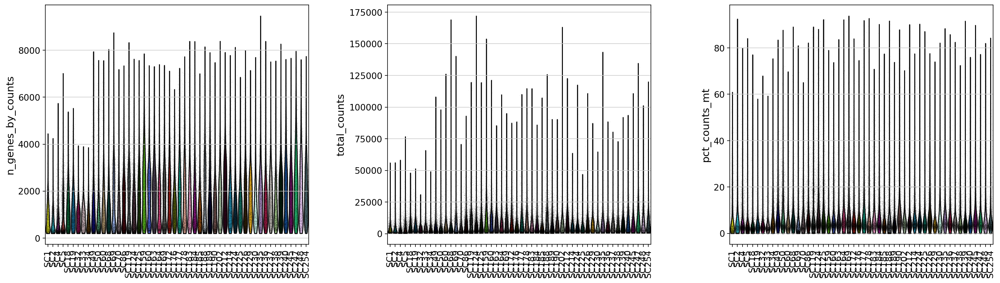

In [115]:
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6, 6)

sc.pl.violin(adata_merged,
    ["n_genes_by_counts","total_counts", "pct_counts_mt"],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)

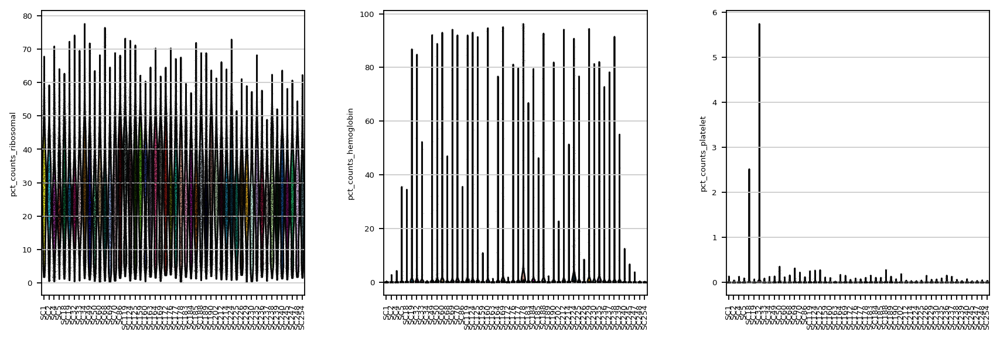

In [116]:
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6, 6)
sc.set_figure_params(scanpy=True, fontsize=6)

sc.pl.violin(adata_merged,
    ["pct_counts_ribosomal", "pct_counts_hemoglobin","pct_counts_platelet"],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=False,
    size = 0.2 )  # 3 inches per row)  # width x height in inches)

In [117]:
adata_merged.obs

,n_genes,sample,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribosomal,pct_counts_hemoglobin,pct_counts_platelet,umi_gene_ratio,batch,...,condition:ch1,tissue:ch1,dataset,characteristics_ch1.4,contact_email,supplementary_file_2,supplementary_file_3,individual:ch1,time:ch1,treatment:ch1
cell,,,,,,,,,,,,,,,,,,,,,
SC124_AAACCTGAGTTAGCGG-1-GSE138669,1700,SC124,6970.0,1700,12.941177,39.110473,0.000000,0.0,4.100000,GSE138669,...,CONTROL,skin;skin,GSE138669,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SC124_AAACCTGCAACTGCGC-1-GSE138669,1580,SC124,7385.0,1580,2.626947,27.217332,0.000000,0.0,4.674051,GSE138669,...,CONTROL,skin;skin,GSE138669,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SC124_AAACCTGCACCACGTG-1-GSE138669,815,SC124,2085.0,815,11.750600,7.769784,0.047962,0.0,2.558282,GSE138669,...,CONTROL,skin;skin,GSE138669,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SC124_AAACCTGCATTTCAGG-1-GSE138669,1183,SC124,4538.0,1183,4.451300,48.677832,0.000000,0.0,3.836010,GSE138669,...,CONTROL,skin;skin,GSE138669,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SC124_AAACCTGGTGGCGAAT-1-GSE138669,1471,SC124,3568.0,1471,14.125560,16.704036,0.028027,0.0,2.425561,GSE138669,...,CONTROL,skin;skin,GSE138669,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SC224_TTTGGTTAGGTTCCTA-1-SC224-GSE209635,798,SC224,1817.0,798,2.751789,25.261420,0.055036,0.0,2.276942,GSE209635,...,Systemic sclerosis (SSc),Skin,GSE209635,time: TOFA-Bsl,alextsoi@umich.edu,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6381...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6381...,01-111,TOFA-Bsl,TOFA
SC224_TTTGGTTTCCTGCTTG-1-SC224-GSE209635,387,SC224,3316.0,387,2.352232,10.434258,72.285885,0.0,8.568475,GSE209635,...,Systemic sclerosis (SSc),Skin,GSE209635,time: TOFA-Bsl,alextsoi@umich.edu,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6381...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6381...,01-111,TOFA-Bsl,TOFA
SC224_TTTGTCAGTACTTCTT-1-SC224-GSE209635,1461,SC224,4021.0,1461,2.760507,22.407362,0.149217,0.0,2.752225,GSE209635,...,Systemic sclerosis (SSc),Skin,GSE209635,time: TOFA-Bsl,alextsoi@umich.edu,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6381...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6381...,01-111,TOFA-Bsl,TOFA


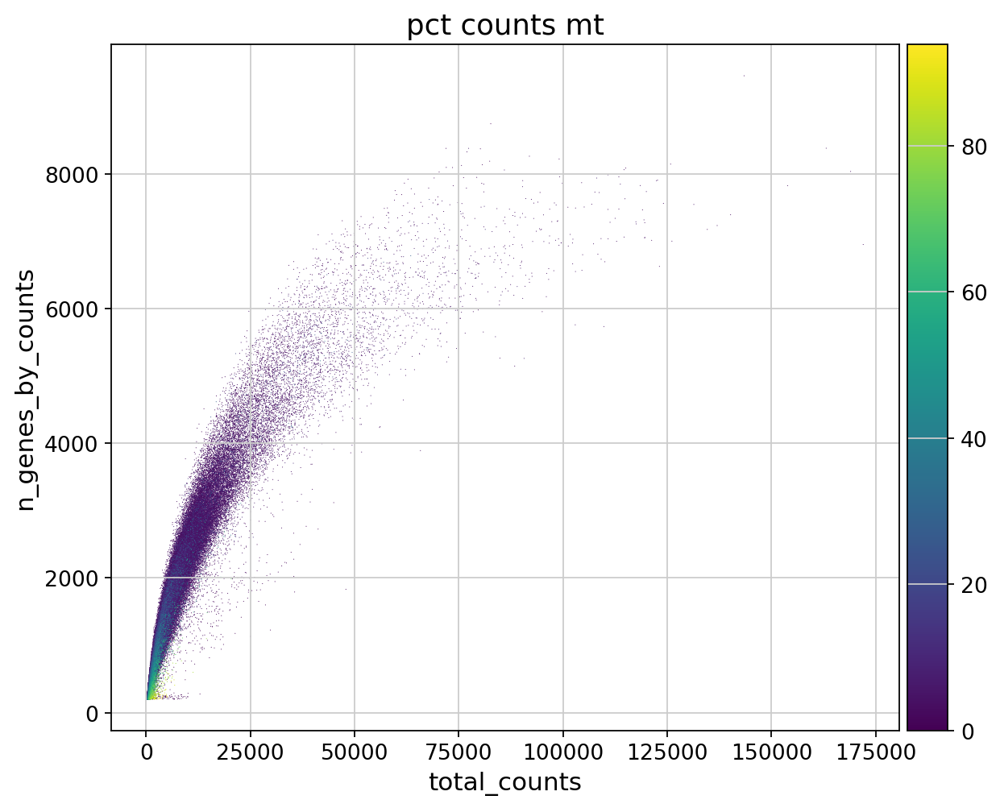

In [118]:
plt.rcParams["figure.figsize"] = (7, 7)
plt.rcParams["axes.titlesize"] = 16       # Title size
plt.rcParams["axes.labelsize"] = 14       # X and Y label size
plt.rcParams["xtick.labelsize"] = 12      # X tick size
plt.rcParams["ytick.labelsize"] = 12      # Y tick size
sc.pl.scatter(adata_merged, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")

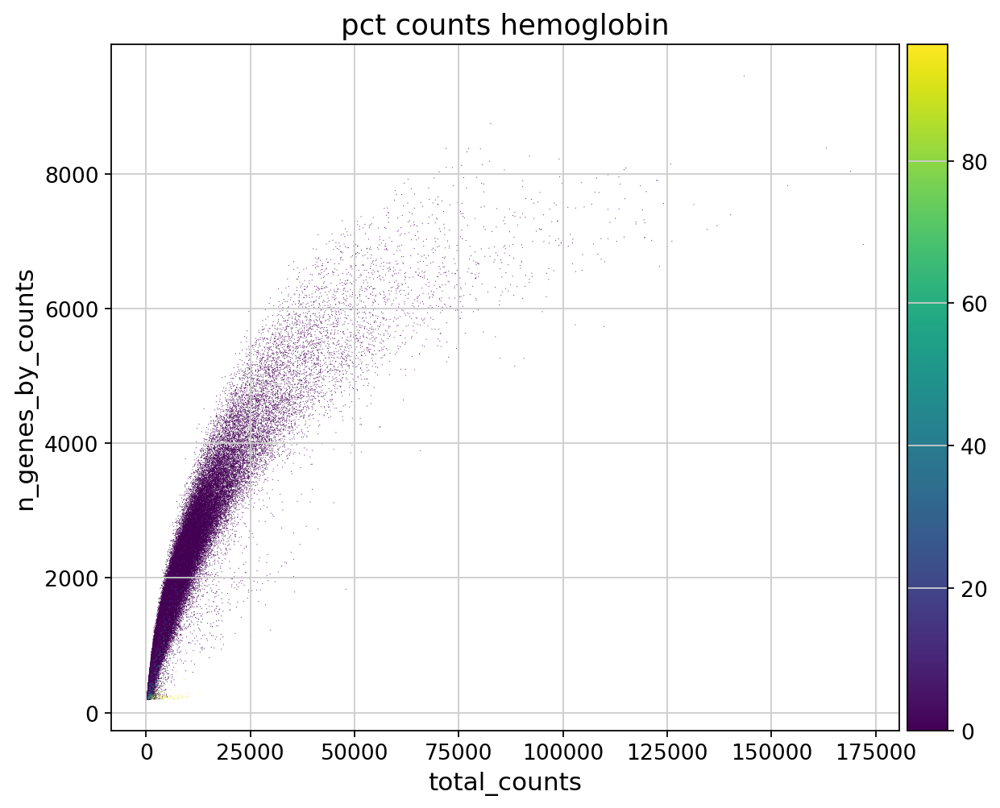

In [119]:
sc.pl.scatter(adata_merged, x="total_counts", y="n_genes_by_counts", color="pct_counts_hemoglobin")

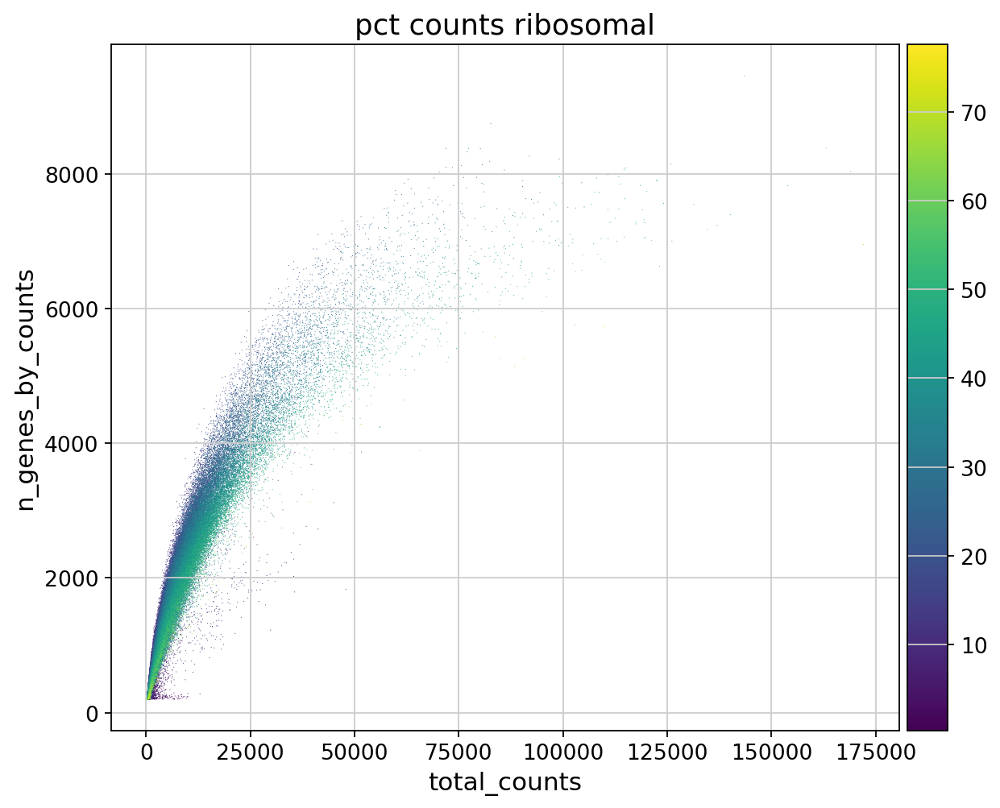

In [120]:
sc.pl.scatter(adata_merged, x="total_counts", y="n_genes_by_counts", color="pct_counts_ribosomal")

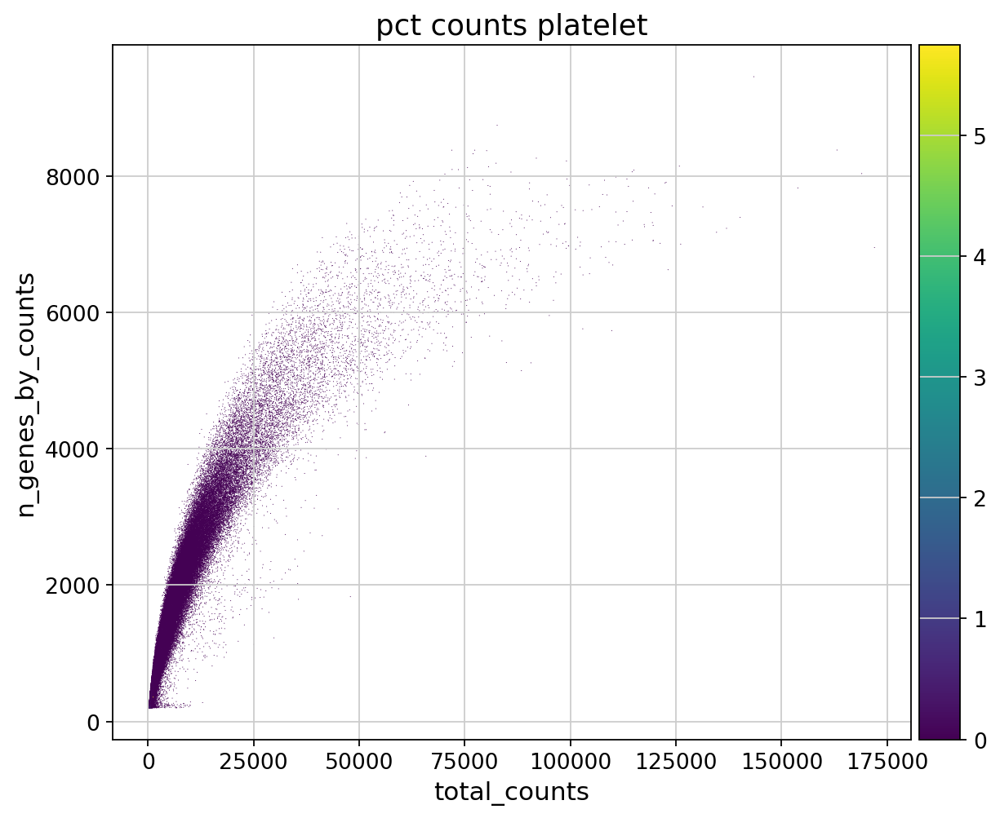

In [121]:
sc.pl.scatter(adata_merged, x="total_counts", y="n_genes_by_counts", color="pct_counts_platelet")

In [122]:
print(len(adata_merged.obs))

137879


# FILTERING THRESHOLD EXPLORATION

In [123]:
# Define thresholds for filtering
ribo_thresholds_down = np.arange(0, 15, 2.5)  # Ribosomal % from 0% to 15%
ribo_thresholds_up = np.arange(20, 50, 5)  # Ribosomal % from 20% to 60%
# Create a table to store results
results = []

print("Initial number of cells")
print(len(adata_merged.obs))

Initial number of cells
137879


In [124]:
for ribo_down in ribo_thresholds_down:
    for ribo_up in ribo_thresholds_up:
        num_cells_removed = ((adata_merged.obs["pct_counts_ribosomal"] > ribo_down) & 
                             (adata_merged.obs["pct_counts_ribosomal"] < ribo_up)).sum()
        results.append([ribo_down, ribo_up, num_cells_removed])

# Convert to DataFrame
qc_table = pd.DataFrame(results, columns=["Ribo_Threshold down > (%)", "Ribo_Threshold up < (%)", "Cells_Filtered"])
print(qc_table)

    Ribo_Threshold down > (%)  Ribo_Threshold up < (%)  Cells_Filtered
0                         0.0                       20           47615
1                         0.0                       25           69216
2                         0.0                       30           90413
3                         0.0                       35          108029
4                         0.0                       40          121375
5                         0.0                       45          130337
6                         2.5                       20           47022
7                         2.5                       25           68623
8                         2.5                       30           89820
9                         2.5                       35          107436
10                        2.5                       40          120782
11                        2.5                       45          129744
12                        5.0                       20           42995
13    

In [125]:
# Define thresholds for filtering
gene_thresholds = np.arange(5000, 9000, 1000)  # Gene Threshold
count_thresholds = np.arange(30000, 70000, 10000)  # Count Threshold
# Create a table to store results
results = []

print("Initial number of cells")
print(len(adata_merged.obs))

Initial number of cells
137879


In [126]:
for gene in gene_thresholds:
    for count in count_thresholds:
        num_cells_removed = ((adata.obs["total_counts"] < gene) & 
                             (adata.obs["n_genes_by_counts"] < count)).sum()
        results.append([gene, count, num_cells_removed])

# Convert to DataFrame
qc_table = pd.DataFrame(results, columns=["Gene number < (%)", "Reads/UMI counts < (%)", "Cells_Filtered"])
print(qc_table)

    Gene number < (%)  Reads/UMI counts < (%)  Cells_Filtered
0                5000                   30000           36118
1                5000                   40000           36118
2                5000                   50000           36118
3                5000                   60000           36118
4                6000                   30000           40432
5                6000                   40000           40432
6                6000                   50000           40432
7                6000                   60000           40432
8                7000                   30000           44215
9                7000                   40000           44215
10               7000                   50000           44215
11               7000                   60000           44215
12               8000                   30000           47503
13               8000                   40000           47503
14               8000                   50000           47503
15      

In [127]:
# Define thresholds for filtering
mito_thresholds = np.arange(5, 25, 5)  # Ribosomal % from 2.5% to 15%
hemo_thresholds = np.arange(0.5, 2.0, 0.5)  # Hemoglobin % from 0.25% to 1.5%
plat_thresholds = np.arange(0.5, 2.0, 0.5)  # Platelets % from 0.25% to 1.5%
# Create a table to store results
results = []

print("Initial number of cells")
print(len(adata_merged.obs))

Initial number of cells
137879


In [128]:
for mito in mito_thresholds:
    for hemo in hemo_thresholds:
        for plat in plat_thresholds:
            num_cells_removed = ((adata_merged.obs["pct_counts_mt"] < mito) & 
                                 (adata_merged.obs["pct_counts_hemoglobin"] < hemo) &
                                 (adata_merged.obs["pct_counts_platelet"] < plat)).sum()
            results.append([mito, hemo, plat, num_cells_removed])

# Convert to DataFrame
qc_table = pd.DataFrame(results, columns=["Mito_Thr < (%)", "Hemo_Thr < (%)", "Plat_Thr < (%)", "Cells_Filtered"])
print(qc_table)

    Mito_Thr < (%)  Hemo_Thr < (%)  Plat_Thr < (%)  Cells_Filtered
0                5             0.5             0.5           84293
1                5             0.5             1.0           84293
2                5             0.5             1.5           84293
3                5             1.0             0.5           84693
4                5             1.0             1.0           84693
5                5             1.0             1.5           84693
6                5             1.5             0.5           84774
7                5             1.5             1.0           84774
8                5             1.5             1.5           84774
9               10             0.5             0.5          110534
10              10             0.5             1.0          110534
11              10             0.5             1.5          110534
12              10             1.0             0.5          111054
13              10             1.0             1.0          11

# FILTERING STEP (Harmonized with Celina)
## UMI > 200
## Removal genes with < 10 total reads
## % mitocondrial removal after 95th percentile, il less than 20%, 20% filtering by default
## % Gene number and UMI removal after the 99th percentile

In [129]:
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6, 6)
sc.set_figure_params(scanpy=True, fontsize=6)

print("Prefilter number of cells")
print(len(adata_merged.obs))

Prefilter number of cells
137879


In [130]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

def adaptive_gene_filter(
    adata,
    feature: str = "total_counts",
    low_base: float = 200,
    plot_hist: bool = True,
    plot_violin: bool = True,
    violin_max_cells: int = 20000
):
    """
    Fixed filtering based on number of genes per cell (n_genes_by_counts).
    Removes cells with too few detected genes, using percentile and dynamic thresholds.
    Keeps same plotting/violin logic as adaptive_ribo_filter().
    """

    values = adata.obs[feature].dropna()

    # --- Manual modification to apply a fixed threshold ---
    low_cutoff = 200
    # --- Apply filtering ---
    mask = adata.obs[feature] >= low_cutoff
    adata_filtered = adata[mask].copy()
    adata_removed = adata[~mask].copy()

    print(f"  • Cells kept: {adata_filtered.n_obs}")
    print(f"  • Cells removed: {adata_removed.n_obs}")

    # --- Histogram ---
    if plot_hist:
        plt.figure(figsize=(6,4))
        plt.hist(values, bins=60, alpha=0.5, label='All cells')
        plt.axvline(low_cutoff, color='b', linestyle='--', label='Low cutoff')
        plt.xlabel(feature)
        plt.ylabel("Cell count")
        plt.legend()
        plt.tight_layout()
        plt.show()

    # --- Memory-efficient violin plots (same as ribosomal filter) ---
    if plot_violin:
        def _subsample(adata_in):
            if adata_in.n_obs > violin_max_cells:
                idx = np.random.choice(adata_in.n_obs, violin_max_cells, replace=False)
                return adata_in[idx, :].copy()
            return adata_in

        adata_filt_sub = _subsample(adata_filtered)
        adata_rem_sub = _subsample(adata_removed)

        print(f"\nGenerating violin plots (subsampled):")
        print(f"  Filtered: {adata_filt_sub.n_obs} cells, Removed: {adata_rem_sub.n_obs} cells")

        # Filtered cells
        print("\nFiltered cells:")
        sc.pl.violin(
            adata_filt_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_filt_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

        # Removed cells
        print("\nRemoved cells:")
        sc.pl.violin(
            adata_rem_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_rem_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

    return adata_filtered, adata_removed


  • Cells kept: 137879
  • Cells removed: 0


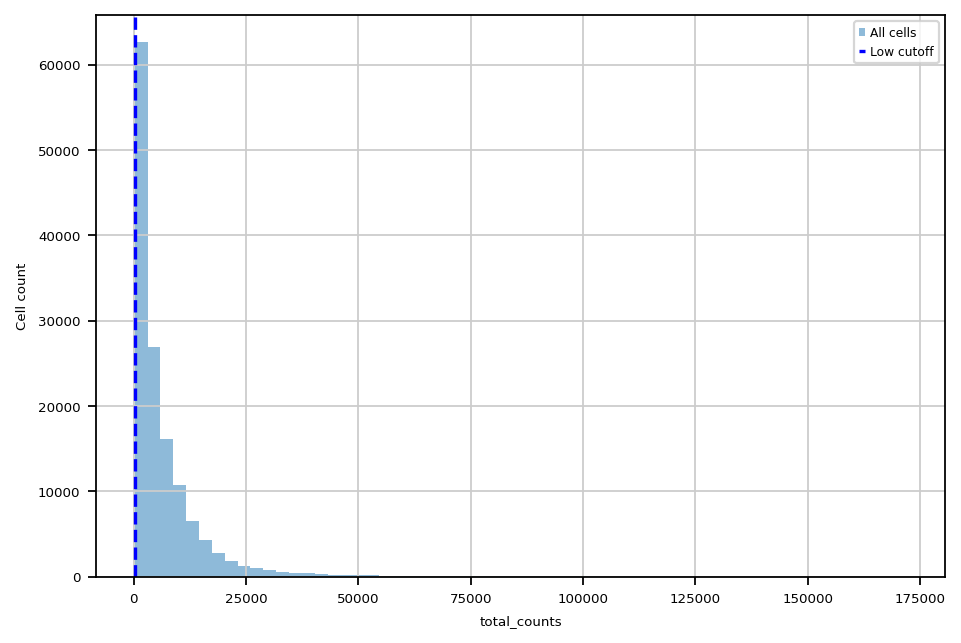


Generating violin plots (subsampled):
  Filtered: 20000 cells, Removed: 0 cells

Filtered cells:


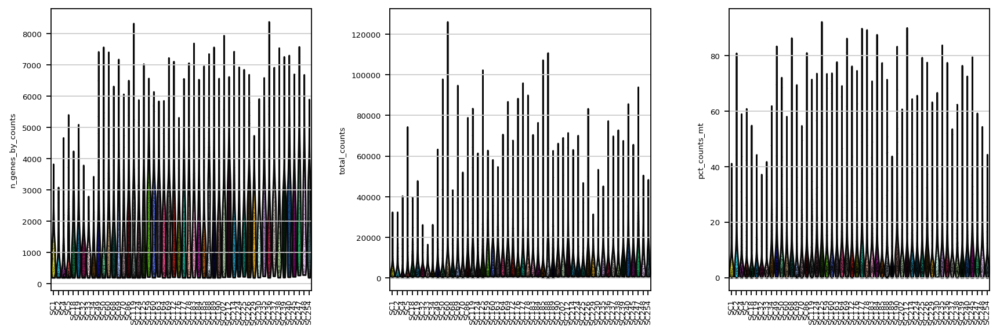

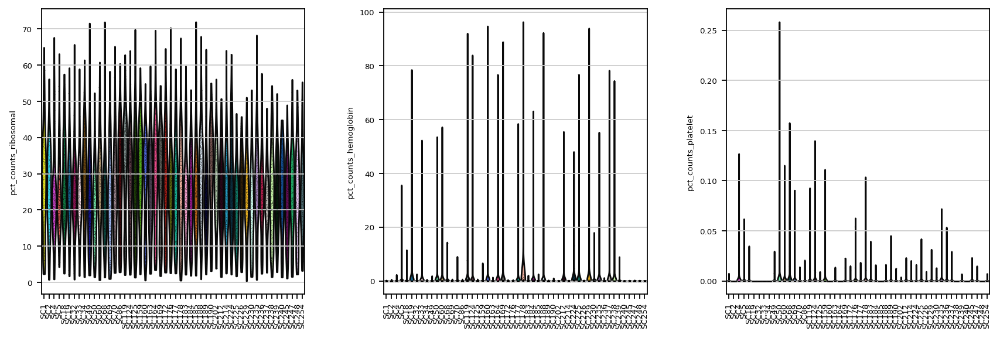


Removed cells:


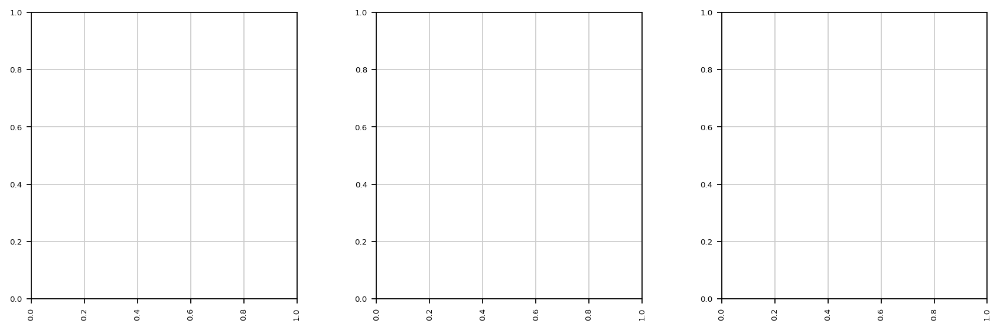

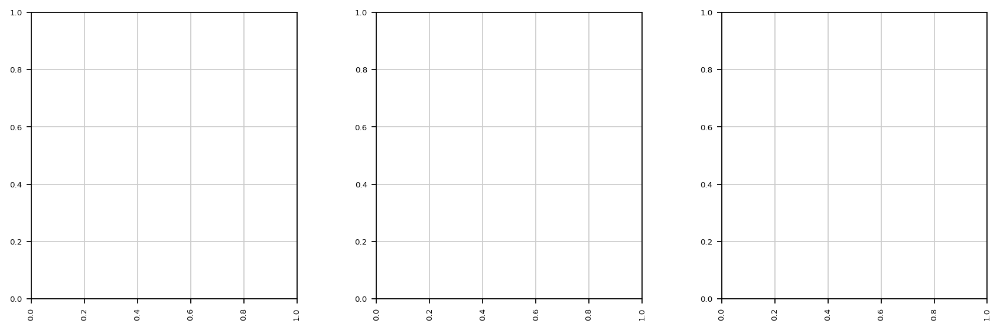

In [131]:
adata_merged, adata_gene_removed = adaptive_gene_filter(
    adata_merged,
    feature="total_counts",
    low_base=200,
    plot_hist=True,
    plot_violin=True,
    violin_max_cells=20000
)


In [132]:
adata
values = adata.obs["total_counts"].dropna()
low_perc = np.percentile(values, 100 - 1)
print(low_perc)

48817.46


In [133]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

def adaptive_gene_filter(
    adata,
    feature: str = "total_counts",
    tail_trim: float = 1,
    plot_hist: bool = True,
    plot_violin: bool = True,
    violin_max_cells: int = 20000
):
    """
    Adaptive filtering based on number of genes per cell (n_genes_by_counts).
    Removes cells with too few detected genes, using percentile and dynamic thresholds.
    Keeps same plotting/violin logic as adaptive_ribo_filter().
    """

    values = adata.obs[feature].dropna()

    # --- Compute baseline (percentile and fraction below threshold) ---
    low_cutoff = np.percentile(values, 100 - tail_trim)
    

    print(f"Adaptive gene filtering summary:")
    print(f"  • Initial number of cells: {adata.n_obs}")
    print(f"  • Percentile baseline (low): {tail_trim}%")

    # --- Apply filtering ---
    mask = adata.obs[feature] <= low_cutoff
    adata_filtered = adata[mask].copy()
    adata_removed = adata[~mask].copy()

    print(f"  • Cells kept: {adata_filtered.n_obs}")
    print(f"  • Cells removed: {adata_removed.n_obs}")

    # --- Histogram ---
    if plot_hist:
        plt.figure(figsize=(6,4))
        plt.hist(values, bins=60, alpha=0.5, label='All cells')
        plt.axvline(low_cutoff, color='b', linestyle='--', label='Low cutoff')
        plt.xlabel(feature)
        plt.ylabel("Cell count")
        plt.legend()
        plt.tight_layout()
        plt.show()

    # --- Memory-efficient violin plots (same as ribosomal filter) ---
    if plot_violin:
        def _subsample(adata_in):
            if adata_in.n_obs > violin_max_cells:
                idx = np.random.choice(adata_in.n_obs, violin_max_cells, replace=False)
                return adata_in[idx, :].copy()
            return adata_in

        adata_filt_sub = _subsample(adata_filtered)
        adata_rem_sub = _subsample(adata_removed)

        print(f"\nGenerating violin plots (subsampled):")
        print(f"  Filtered: {adata_filt_sub.n_obs} cells, Removed: {adata_rem_sub.n_obs} cells")

        # Filtered cells
        print("\nFiltered cells:")
        sc.pl.violin(
            adata_filt_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_filt_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

        # Removed cells
        print("\nRemoved cells:")
        sc.pl.violin(
            adata_rem_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_rem_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

    return adata_filtered, adata_removed


Adaptive gene filtering summary:
  • Initial number of cells: 137879
  • Percentile baseline (low): 1%
  • Cells kept: 136500
  • Cells removed: 1379


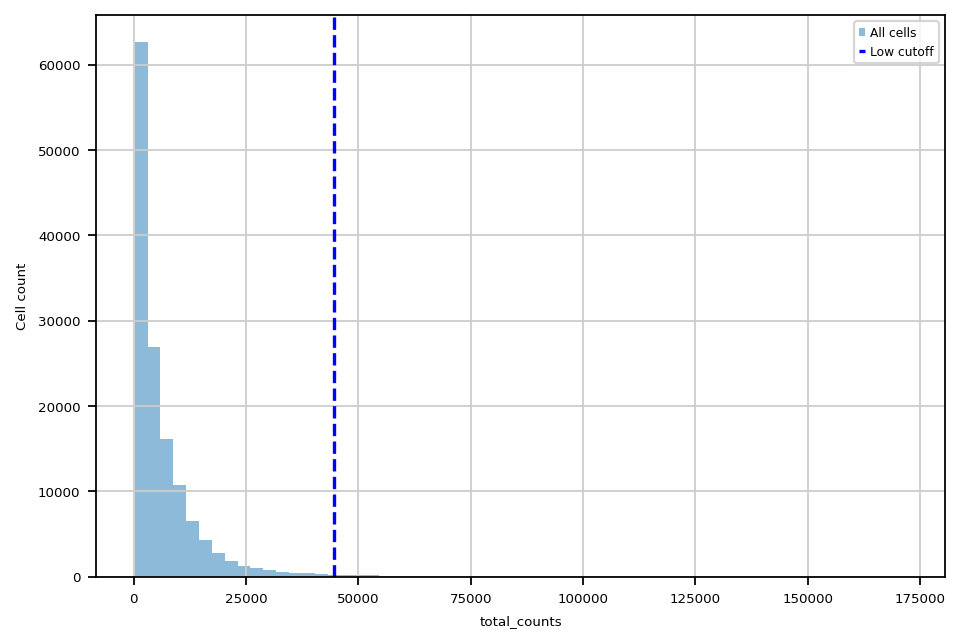


Generating violin plots (subsampled):
  Filtered: 20000 cells, Removed: 1379 cells

Filtered cells:


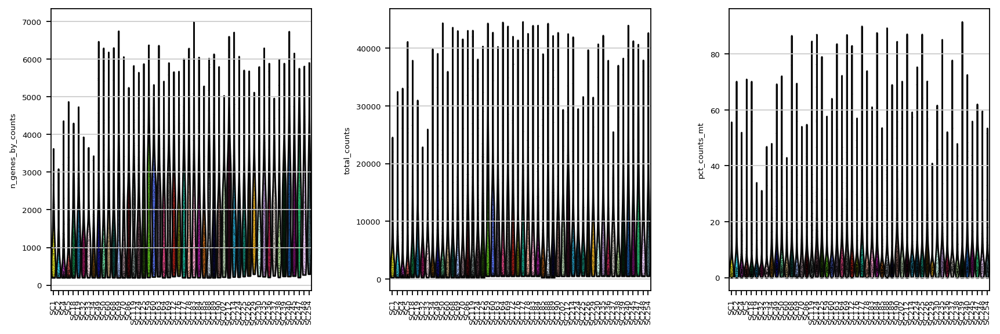

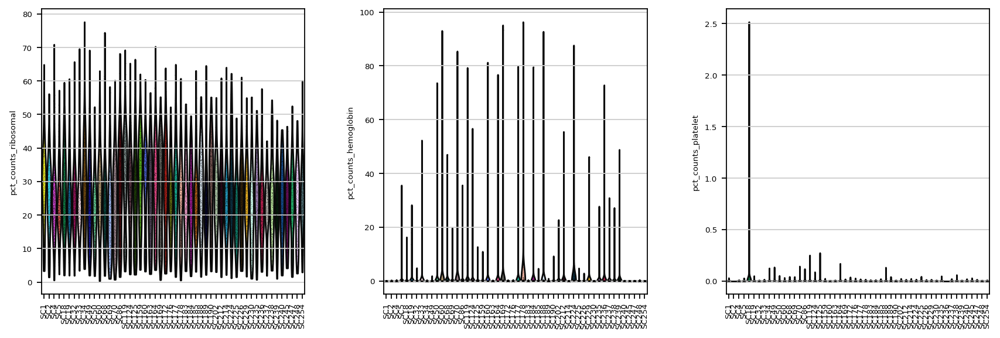


Removed cells:


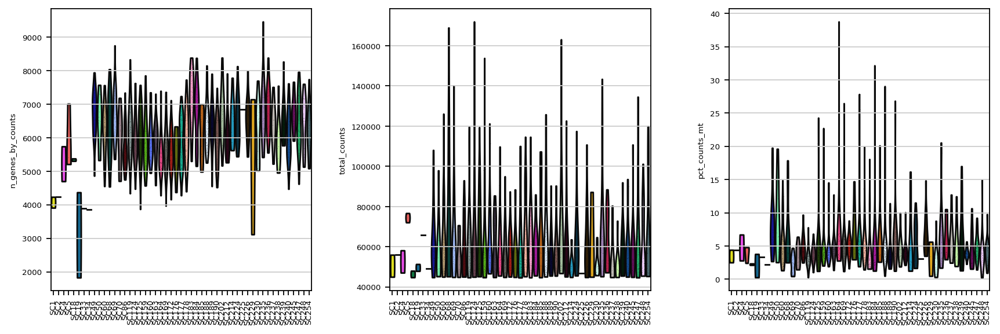

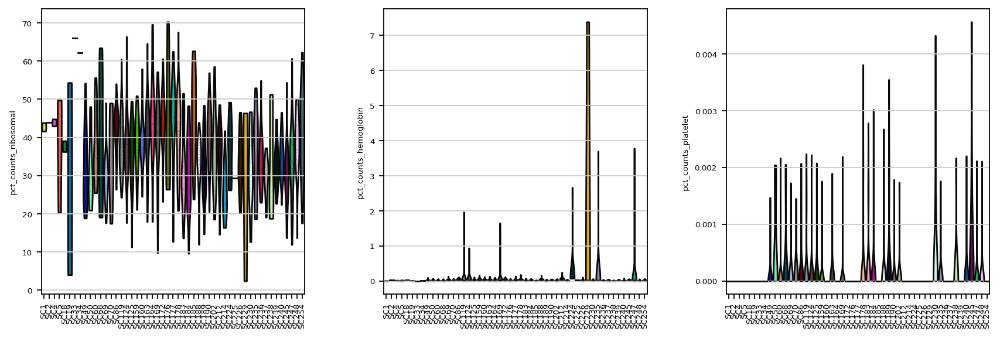

In [134]:
adata_merged, adata_gene_removed = adaptive_gene_filter(
    adata_merged,
    feature="total_counts",
    tail_trim=1,
    plot_hist=True,
    plot_violin=True,
    violin_max_cells=20000
)


Adaptive gene filtering summary:
  • Initial number of cells: 136500
  • Percentile baseline (low): 1%
  • Cells kept: 135135
  • Cells removed: 1365


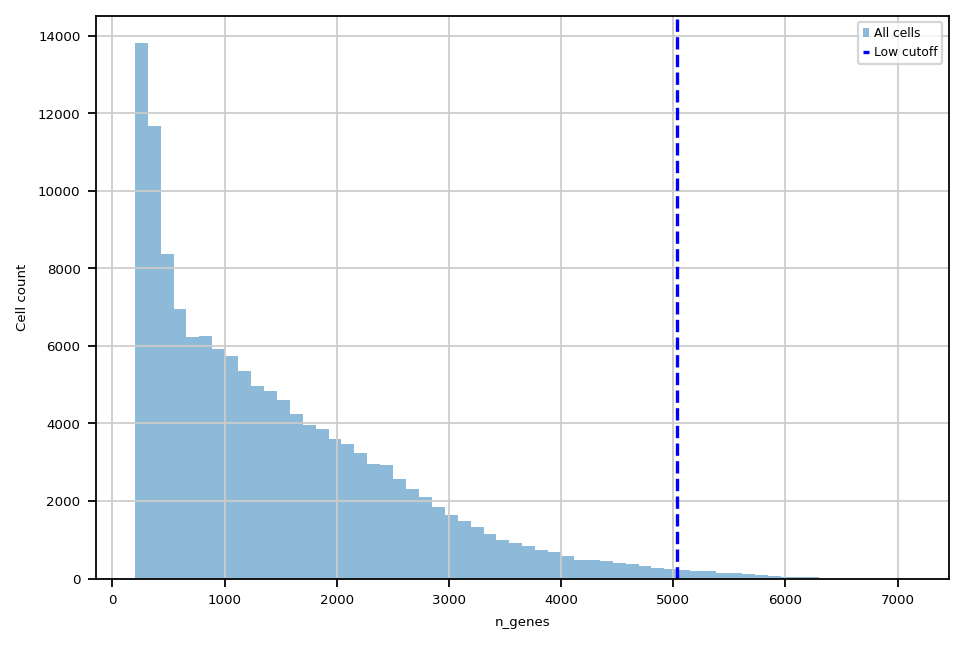


Generating violin plots (subsampled):
  Filtered: 20000 cells, Removed: 1365 cells

Filtered cells:


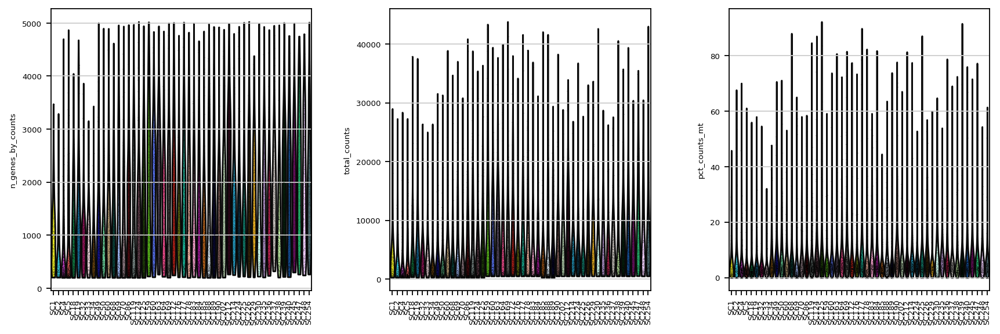

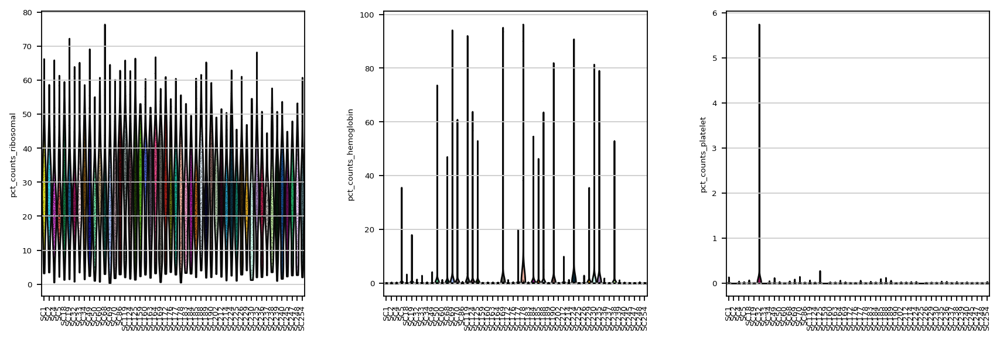


Removed cells:


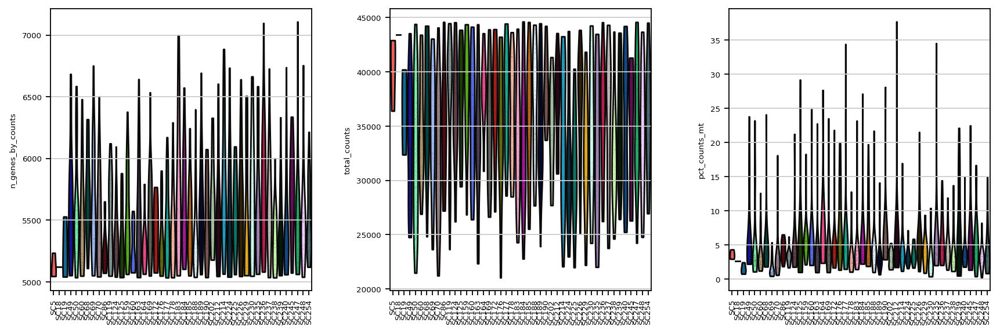

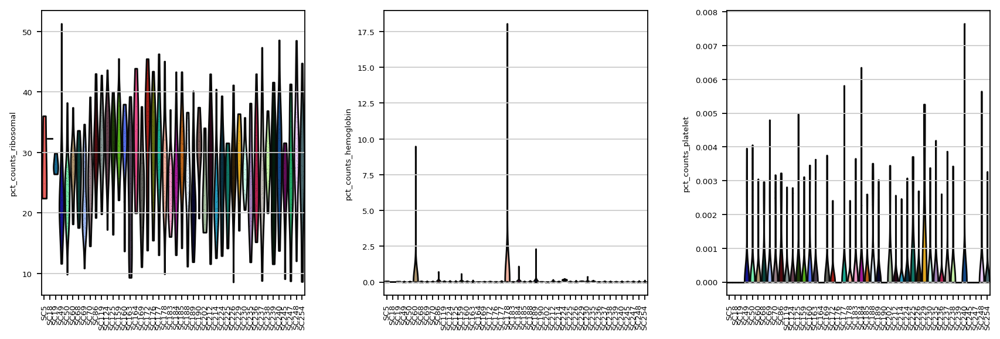

In [135]:
adata_merged, adata_gene_removed = adaptive_gene_filter(
    adata_merged,
    feature="n_genes",
    tail_trim=1,
    plot_hist=True,
    plot_violin=True,
    violin_max_cells=20000
)

In [136]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

def adaptive_gene_filter(
    adata,
    feature: str = "pct_counts_mt",
    low_base: float = 20,
    tail_trim: float = 5,
    plot_hist: bool = True,
    plot_violin: bool = True,
    violin_max_cells: int = 20000
):
    """
    Adaptive filtering based on number of genes per cell (n_genes_by_counts).
    Removes cells with too few detected genes, using percentile and dynamic thresholds.
    Keeps same plotting/violin logic as adaptive_ribo_filter().
    """

    values = adata.obs[feature].dropna()

    # --- Compute baseline (percentile and fraction below threshold) ---
    low_perc = np.percentile(values, 100 - tail_trim)

    if low_perc < low_base:
        low_cutoff = low_base
    else:
        low_cutoff = low_perc
    

    print(f"Adaptive gene filtering summary:")
    print(f"  • Initial number of cells: {adata.n_obs}")
    print(f"  • Percentile baseline (low): {tail_trim}%")
    print(f"  • Percentile threshold: {low_perc}%")
    print(f"  • Chosen threshold: {low_cutoff}%")

    # --- Apply filtering ---
    mask = adata.obs[feature] <= low_cutoff
    adata_filtered = adata[mask].copy()
    adata_removed = adata[~mask].copy()

    print(f"  • Cells kept: {adata_filtered.n_obs}")
    print(f"  • Cells removed: {adata_removed.n_obs}")

    # --- Histogram ---
    if plot_hist:
        plt.figure(figsize=(6,4))
        plt.hist(values, bins=60, alpha=0.5, label='All cells')
        plt.axvline(low_cutoff, color='b', linestyle='--', label='Low cutoff')
        plt.xlabel(feature)
        plt.ylabel("Cell count")
        plt.legend()
        plt.tight_layout()
        plt.show()

    # --- Memory-efficient violin plots (same as ribosomal filter) ---
    if plot_violin:
        def _subsample(adata_in):
            if adata_in.n_obs > violin_max_cells:
                idx = np.random.choice(adata_in.n_obs, violin_max_cells, replace=False)
                return adata_in[idx, :].copy()
            return adata_in

        adata_filt_sub = _subsample(adata_filtered)
        adata_rem_sub = _subsample(adata_removed)

        print(f"\nGenerating violin plots (subsampled):")
        print(f"  Filtered: {adata_filt_sub.n_obs} cells, Removed: {adata_rem_sub.n_obs} cells")

        # Filtered cells
        print("\nFiltered cells:")
        sc.pl.violin(
            adata_filt_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_filt_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

        # Removed cells
        print("\nRemoved cells:")
        sc.pl.violin(
            adata_rem_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_rem_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

    return adata_filtered, adata_removed


Adaptive gene filtering summary:
  • Initial number of cells: 135135
  • Percentile baseline (low): 5%
  • Percentile threshold: 28.320240080356587%
  • Chosen threshold: 28.320240080356587%
  • Cells kept: 128378
  • Cells removed: 6757


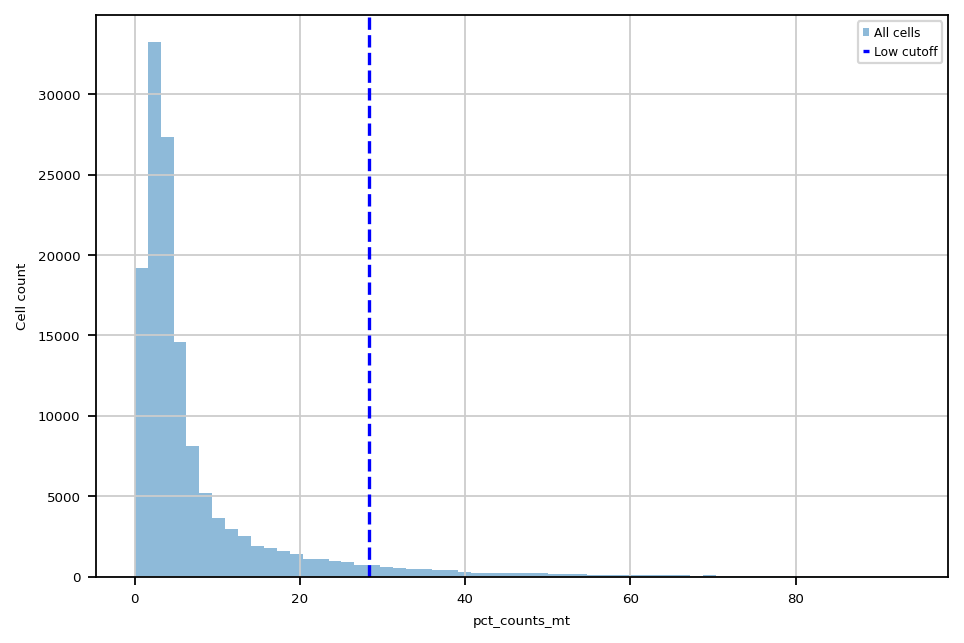


Generating violin plots (subsampled):
  Filtered: 20000 cells, Removed: 6757 cells

Filtered cells:


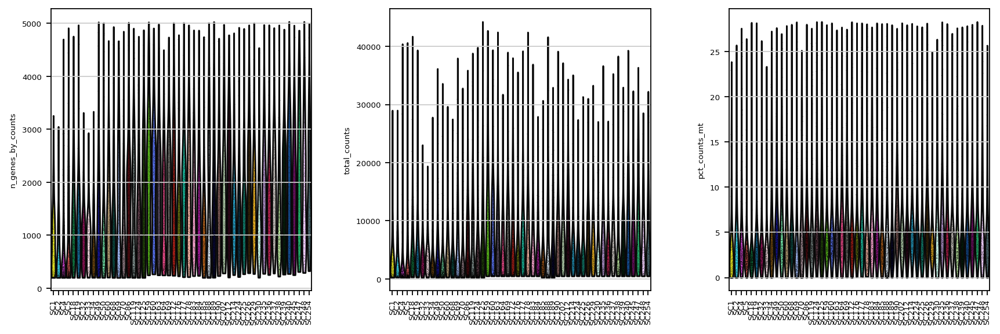

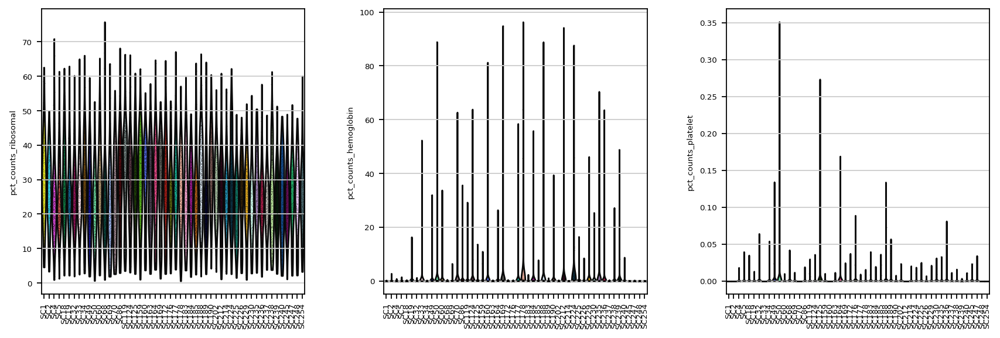


Removed cells:


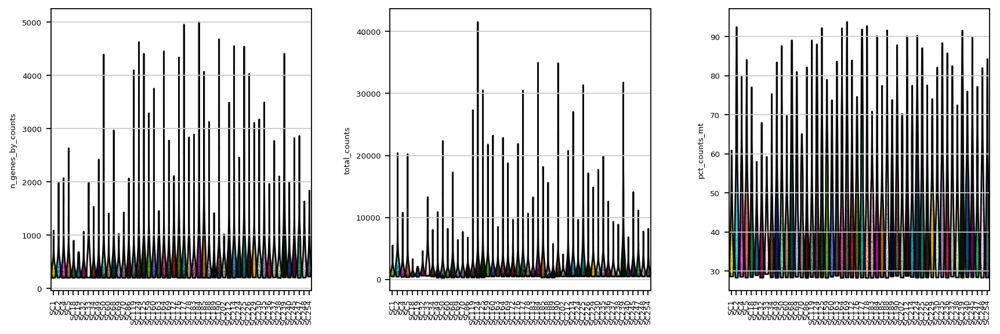

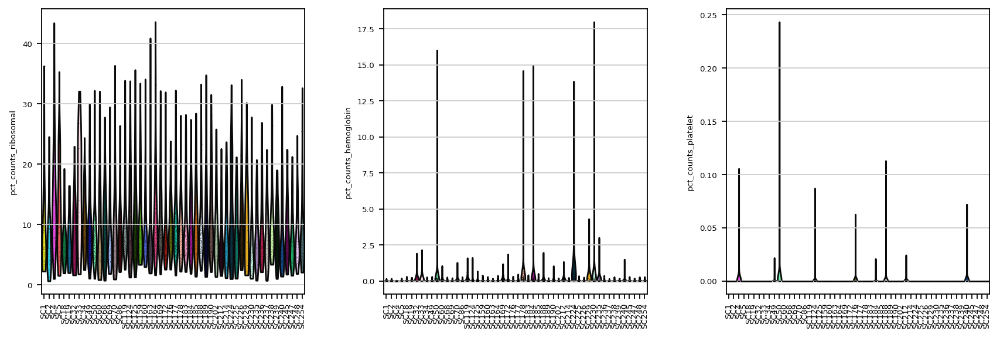

In [137]:
adata_merged, adata_gene_removed = adaptive_gene_filter(
    adata_merged,
    feature="pct_counts_mt",
    low_base=20,
    tail_trim=5,
    plot_hist=True,
    plot_violin=True,
    violin_max_cells=20000
)


In [138]:
import scanpy as sc
import numpy as np

print(f"Genes before: {adata_merged.n_vars}")

# Calcola il totale delle reads per gene (somma su tutte le cellule)
gene_counts = np.array(adata_merged.X.sum(axis=0)).flatten()

# Crea una maschera booleana: True per i geni con >= 10 reads
gene_mask = gene_counts >= 10

# Filtra l'AnnData
adata_merged = adata_merged[:, gene_mask].copy()

print(f"Genes after: {adata_merged.n_vars}")

Genes before: 33538
Genes after: 23748


# After Filtering and clustering

In [139]:
adata_merged.raw = adata_merged.copy()
sc.pp.normalize_total(adata_merged, target_sum=1e4)
print(adata_merged.raw.X)

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 190105991 stored elements and shape (128378, 23748)>
  Coords	Values
  (0, 11)	1.0
  (0, 30)	1.0
  (0, 40)	1.0
  (0, 51)	4.0
  (0, 57)	1.0
  (0, 62)	1.0
  (0, 77)	1.0
  (0, 113)	15.0
  (0, 115)	1.0
  (0, 135)	1.0
  (0, 140)	1.0
  (0, 141)	1.0
  (0, 144)	2.0
  (0, 150)	1.0
  (0, 153)	6.0
  (0, 201)	2.0
  (0, 202)	1.0
  (0, 219)	1.0
  (0, 237)	1.0
  (0, 276)	2.0
  (0, 295)	2.0
  (0, 296)	1.0
  (0, 312)	2.0
  (0, 356)	35.0
  (0, 366)	2.0
  :	:
  (128377, 22181)	1.0
  (128377, 22201)	4.0
  (128377, 22323)	1.0
  (128377, 22400)	1.0
  (128377, 22458)	3.0
  (128377, 22619)	1.0
  (128377, 22674)	3.0
  (128377, 22781)	1.0
  (128377, 22877)	1.0
  (128377, 23098)	1.0
  (128377, 23198)	1.0
  (128377, 23219)	4.0
  (128377, 23328)	1.0
  (128377, 23375)	1.0
  (128377, 23379)	1.0
  (128377, 23457)	1.0
  (128377, 23724)	1.0
  (128377, 23725)	7.0
  (128377, 23726)	13.0
  (128377, 23727)	4.0
  (128377, 23729)	4.0
  (128377, 23730)	8.0
  (12837

In [140]:
import re

print(f"Original genes: {adata_merged.n_vars}")

# Keep genes that do NOT match the pattern: ends with .digit
pattern = re.compile(r".*\.\d+$")
keep_genes = [not pattern.match(gene) for gene in adata_merged.var_names]

# Subset the AnnData object
adata2 = adata_merged[:, keep_genes].copy()

print(f"Filtered genes: {adata2.n_vars}")

Original genes: 23748
Filtered genes: 19143


In [141]:
cite_genes = adata.var_names[adata.var_names.str.contains("CITE", case=False, na=False)]
print(cite_genes)

Index(['CITED4', 'CITED2', 'CITED1'], dtype='object')


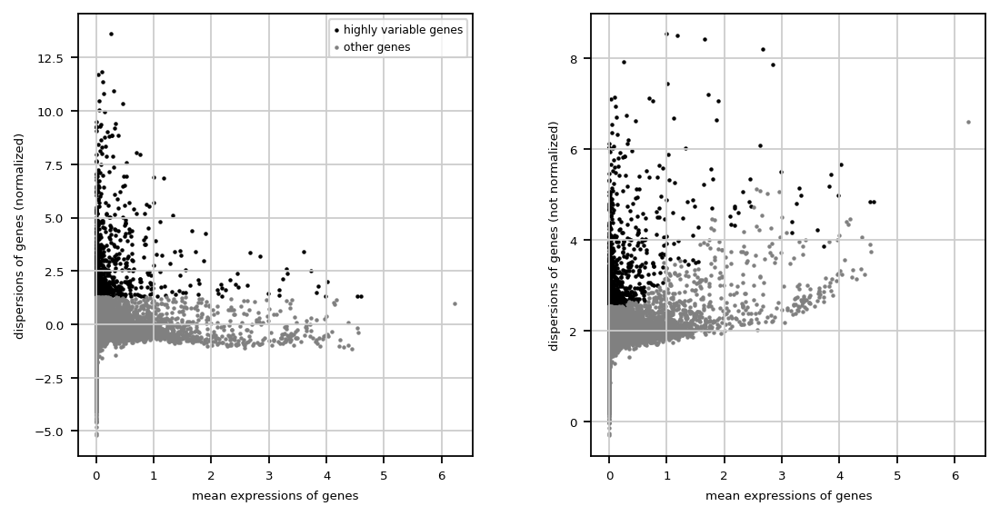

In [142]:
sc.pp.log1p(adata2)
sc.pp.highly_variable_genes(adata2, n_top_genes=1000)
#sc.pp.highly_variable_genes(adata2, min_mean=0.0125, max_mean=3, min_disp=0.5, n_top_genes=1000)
sc.pl.highly_variable_genes(adata2)

In [143]:
hv_genes = adata2.var.highly_variable
print(hv_genes)
adata_hv = adata2[:, hv_genes].copy()

FAM87B       False
LINC00115    False
FAM41C       False
SAMD11       False
NOC2L        False
             ...  
MT-ND4       False
MT-ND5       False
MT-ND6       False
MT-CYB       False
MAFIP        False
Name: highly_variable, Length: 19143, dtype: bool


In [144]:
import numpy as np
import skimage

# Run Scrublet
sc.pp.scrublet(adata_hv, use_approx_neighbors=True, sim_doublet_ratio=1, n_neighbors=10, n_prin_comps=5 )

print("predicted doublets")
print(adata_hv.obs['predicted_doublet'].sum())  # conta i True direttamente

predicted doublets
1981


cell
SC124_AAACCTGAGTTAGCGG-1-GSE138669          0.070652
SC124_AAACCTGCAACTGCGC-1-GSE138669          0.029197
SC124_AAACCTGCACCACGTG-1-GSE138669          0.029197
SC124_AAACCTGCATTTCAGG-1-GSE138669          0.151786
SC124_AAACCTGGTGGCGAAT-1-GSE138669          0.023973
                                              ...   
SC224_TTTGGTTAGGTTCCTA-1-SC224-GSE209635    0.101351
SC224_TTTGGTTTCCTGCTTG-1-SC224-GSE209635    0.011561
SC224_TTTGTCAGTACTTCTT-1-SC224-GSE209635    0.042017
SC224_TTTGTCATCCAAGCCG-1-SC224-GSE209635    0.008242
SC224_TTTGTCATCTGTACGA-1-SC224-GSE209635    0.191489
Name: doublet_score, Length: 128378, dtype: float64
cell
SC124_AAACCTGAGTTAGCGG-1-GSE138669          False
SC124_AAACCTGCAACTGCGC-1-GSE138669          False
SC124_AAACCTGCACCACGTG-1-GSE138669          False
SC124_AAACCTGCATTTCAGG-1-GSE138669          False
SC124_AAACCTGGTGGCGAAT-1-GSE138669          False
                                            ...  
SC224_TTTGGTTAGGTTCCTA-1-SC224-GSE209635    False
SC224

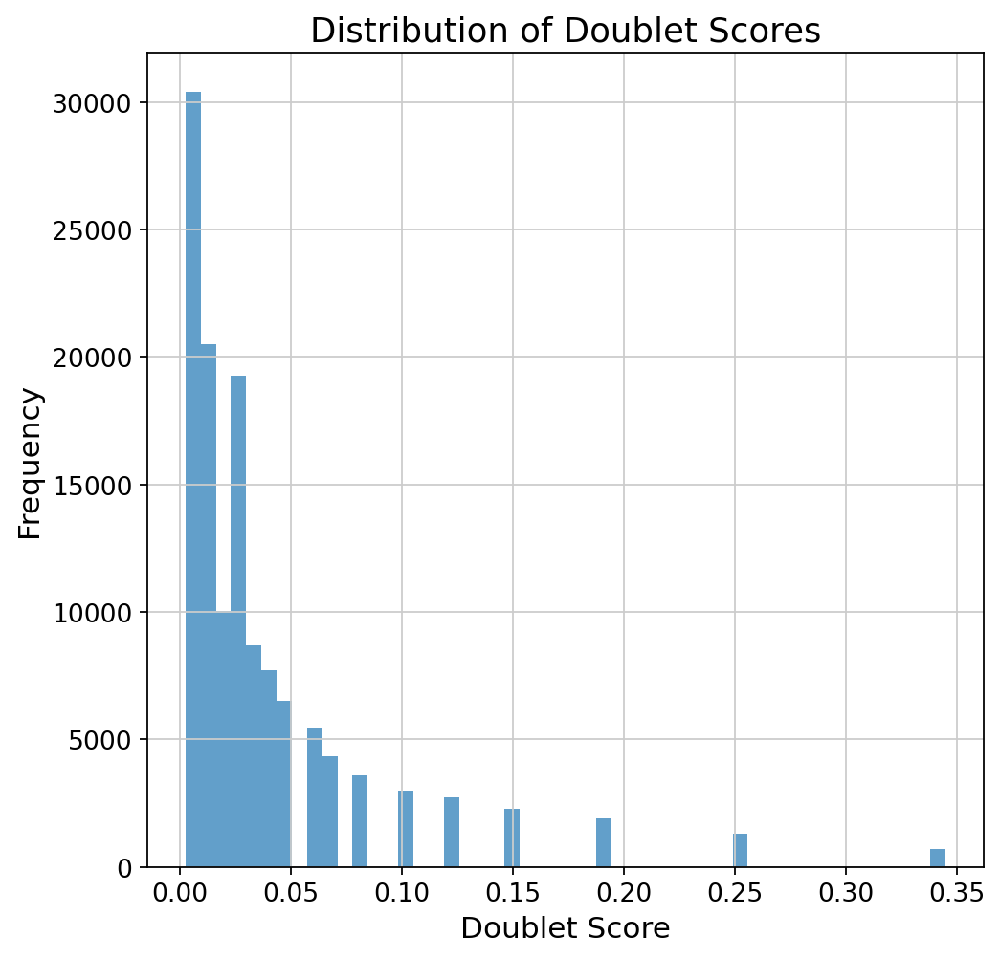

In [145]:
import matplotlib.pyplot as plt


plt.rcParams["figure.figsize"] = (7, 7)
plt.rcParams["axes.titlesize"] = 16       # Title size
plt.rcParams["axes.labelsize"] = 14       # X and Y label size
plt.rcParams["xtick.labelsize"] = 12      # X tick size
plt.rcParams["ytick.labelsize"] = 12      # Y tick size

# Scrublet results are stored in the AnnData object
# Doublet scores
print(adata_hv.obs['doublet_score'])
# Predicted doublets
print(adata_hv.obs['predicted_doublet'])

# Histogram of doublet scores
adata_hv.obs['doublet_score'].plot.hist(bins=50, alpha=0.7)
plt.xlabel('Doublet Score')
plt.ylabel('Frequency')
plt.title('Distribution of Doublet Scores')
plt.show()

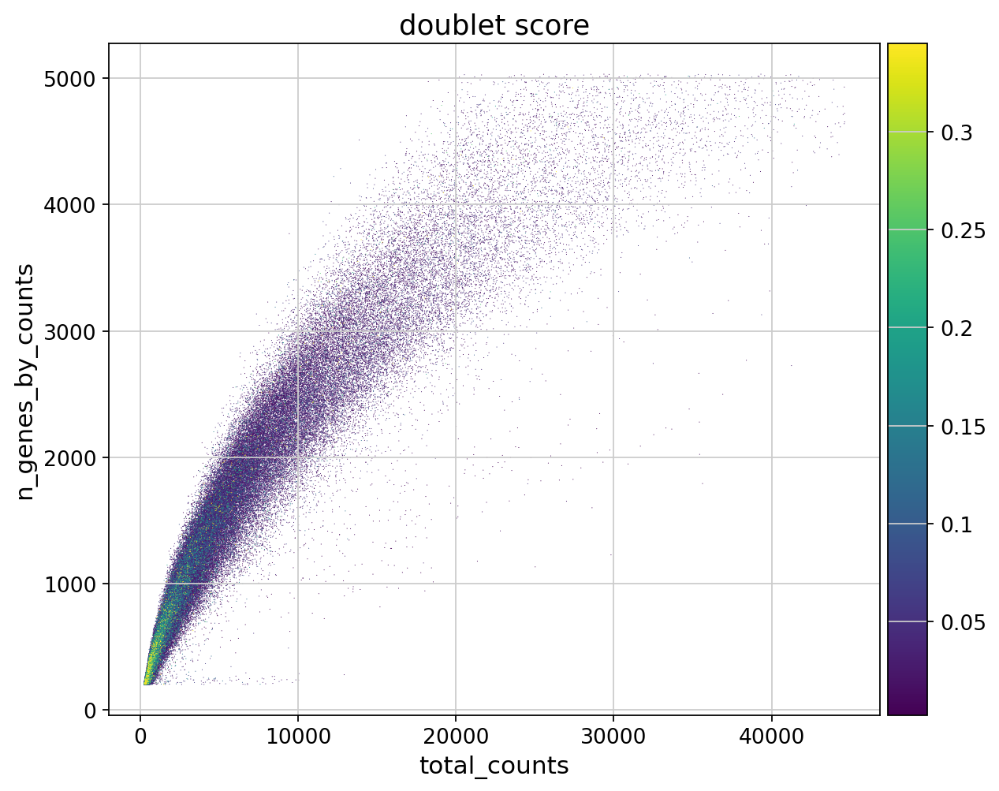

In [146]:
plt.rcParams["figure.figsize"] = (7, 7)
plt.rcParams["axes.titlesize"] = 16       # Title size
plt.rcParams["axes.labelsize"] = 14       # X and Y label size
plt.rcParams["xtick.labelsize"] = 12      # X tick size
plt.rcParams["ytick.labelsize"] = 12      # Y tick size
sc.pl.scatter(adata_hv, x="total_counts", y="n_genes_by_counts", color="doublet_score")

In [147]:
adata_hv.obs['predicted_doublet'] = adata_hv.obs['predicted_doublet'].fillna(False).astype(int)  # 1 = doublet, 0 = singlet

In [148]:
adata3 = adata2
adata3.obs['predicted_doublet'] = adata_hv.obs['predicted_doublet'].copy()
adata3.obs['doublet_score'] = adata_hv.obs['doublet_score'].copy()

print("Number of cells")
print(len(adata3.obs))

Number of cells
128378


In [149]:
adata_removed = adata3[adata3.obs["predicted_doublet"] == 1].copy()
adata3 = adata3[adata3.obs["predicted_doublet"] == 0].copy()

print("Number of cells post doublets")
print(len(adata3.obs))

Number of cells post doublets
126397


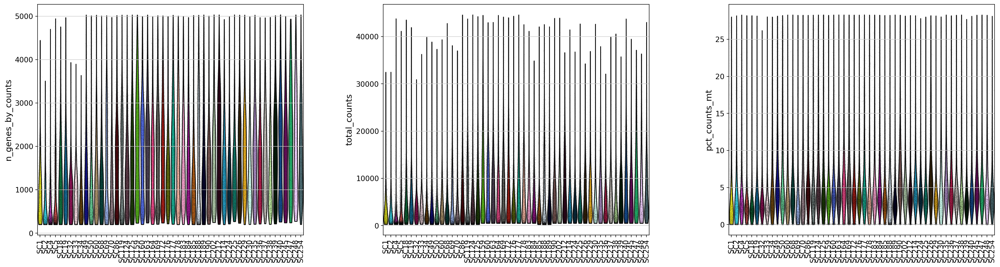

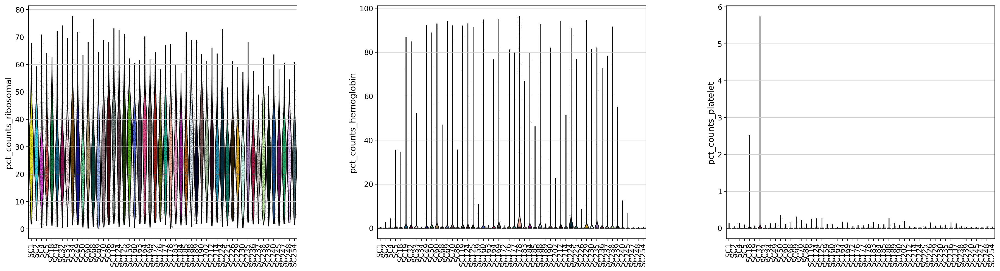

In [150]:
sc.pl.violin(adata3,
    ["n_genes_by_counts", "total_counts","pct_counts_mt"],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)
sc.pl.violin(adata3,
    ["pct_counts_ribosomal","pct_counts_hemoglobin","pct_counts_platelet" ],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)

Cells removed
1981


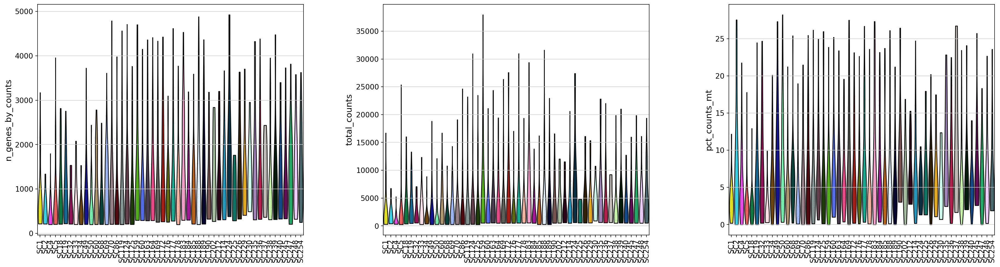

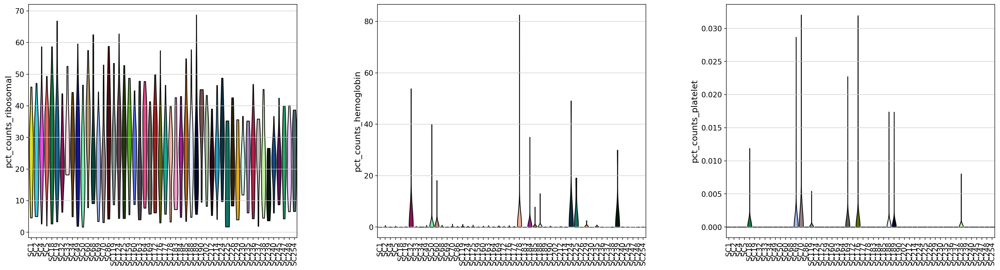

In [151]:
print("Cells removed")
print(len(adata_removed.obs))
sc.pl.violin(adata_removed,
    ["n_genes_by_counts", "total_counts","pct_counts_mt"],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)
sc.pl.violin(adata_removed,
    ["pct_counts_ribosomal","pct_counts_hemoglobin","pct_counts_platelet" ],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)

In [152]:
print("Average number of cells per sample")
print(len(adata3.obs)/adata3.obs["sample"].nunique())

Average number of cells per sample
2430.7115384615386


In [153]:
adata3.obs["sample"].nunique()

52

In [154]:
## Scale data
#sc.pp.scale(adata3, max_value=10)
## 

sc.tl.pca(adata3, svd_solver="arpack", use_highly_variable=True)

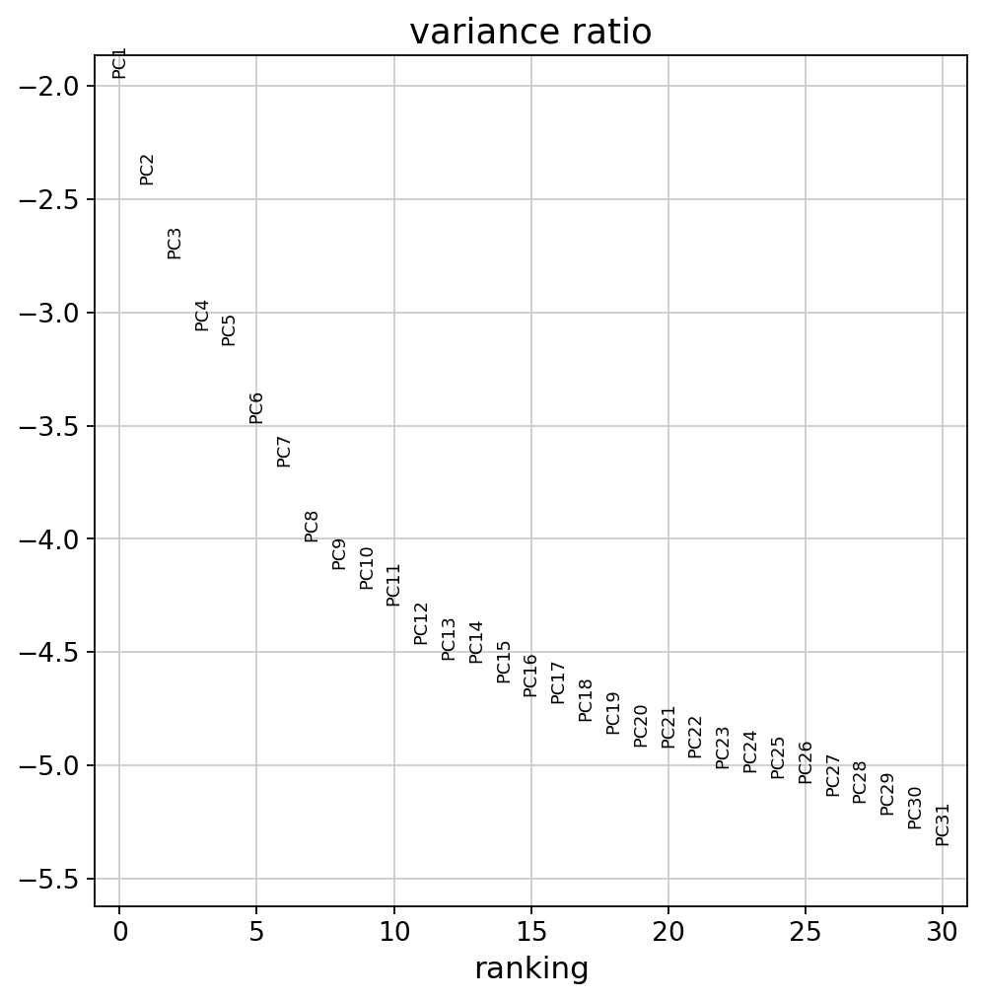

In [155]:
sc.pl.pca_variance_ratio(adata3, log=True)

In [156]:
sc.pp.neighbors(adata3, n_neighbors=15, n_pcs=50)

In [157]:
sc.tl.umap(adata3)

In [158]:
adata3.obs

,n_genes,sample,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribosomal,pct_counts_hemoglobin,pct_counts_platelet,umi_gene_ratio,batch,...,dataset,characteristics_ch1.4,contact_email,supplementary_file_2,supplementary_file_3,individual:ch1,time:ch1,treatment:ch1,predicted_doublet,doublet_score
cell,,,,,,,,,,,,,,,,,,,,,
SC124_AAACCTGAGTTAGCGG-1-GSE138669,1700,SC124,6970.0,1700,12.941177,39.110473,0.000000,0.0,4.100000,GSE138669,...,GSE138669,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.070652
SC124_AAACCTGCAACTGCGC-1-GSE138669,1580,SC124,7385.0,1580,2.626947,27.217332,0.000000,0.0,4.674051,GSE138669,...,GSE138669,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.029197
SC124_AAACCTGCACCACGTG-1-GSE138669,815,SC124,2085.0,815,11.750600,7.769784,0.047962,0.0,2.558282,GSE138669,...,GSE138669,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.029197
SC124_AAACCTGCATTTCAGG-1-GSE138669,1183,SC124,4538.0,1183,4.451300,48.677832,0.000000,0.0,3.836010,GSE138669,...,GSE138669,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.151786
SC124_AAACCTGGTGGCGAAT-1-GSE138669,1471,SC124,3568.0,1471,14.125560,16.704036,0.028027,0.0,2.425561,GSE138669,...,GSE138669,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.023973
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SC224_TTTGGTTAGGTTCCTA-1-SC224-GSE209635,798,SC224,1817.0,798,2.751789,25.261420,0.055036,0.0,2.276942,GSE209635,...,GSE209635,time: TOFA-Bsl,alextsoi@umich.edu,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6381...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6381...,01-111,TOFA-Bsl,TOFA,0,0.101351
SC224_TTTGGTTTCCTGCTTG-1-SC224-GSE209635,387,SC224,3316.0,387,2.352232,10.434258,72.285885,0.0,8.568475,GSE209635,...,GSE209635,time: TOFA-Bsl,alextsoi@umich.edu,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6381...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6381...,01-111,TOFA-Bsl,TOFA,0,0.011561
SC224_TTTGTCAGTACTTCTT-1-SC224-GSE209635,1461,SC224,4021.0,1461,2.760507,22.407362,0.149217,0.0,2.752225,GSE209635,...,GSE209635,time: TOFA-Bsl,alextsoi@umich.edu,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6381...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM6381...,01-111,TOFA-Bsl,TOFA,0,0.042017


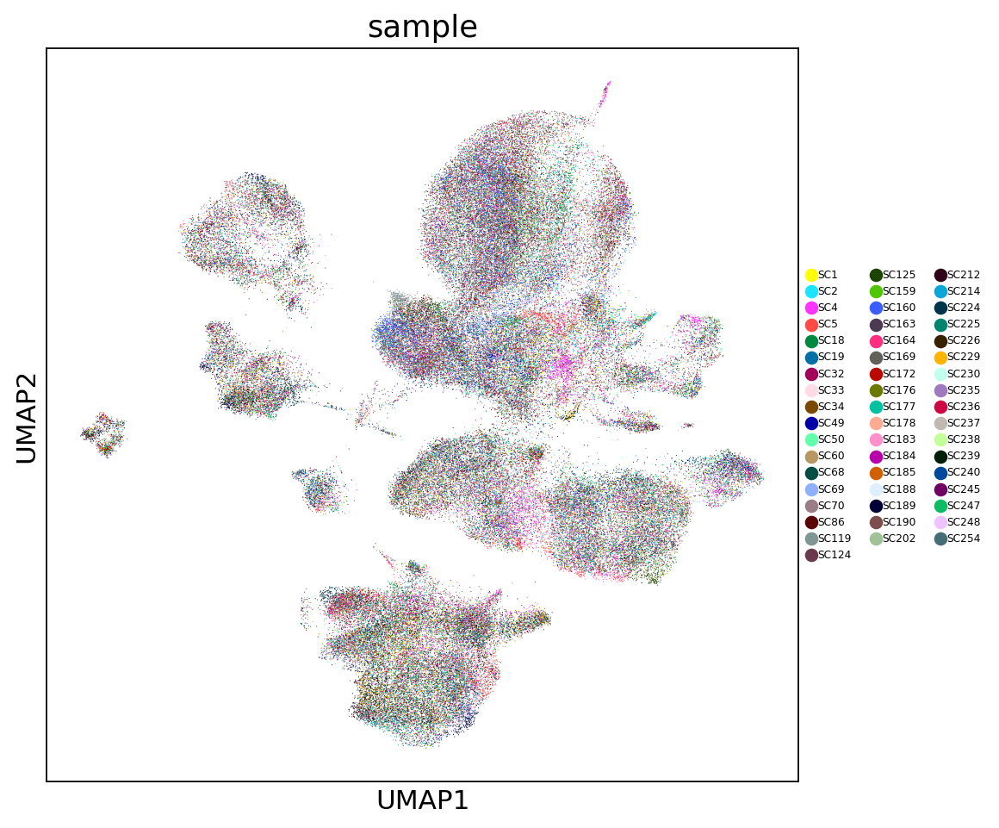

In [159]:
sc.pl.umap(adata3, color=['sample'])

SC124


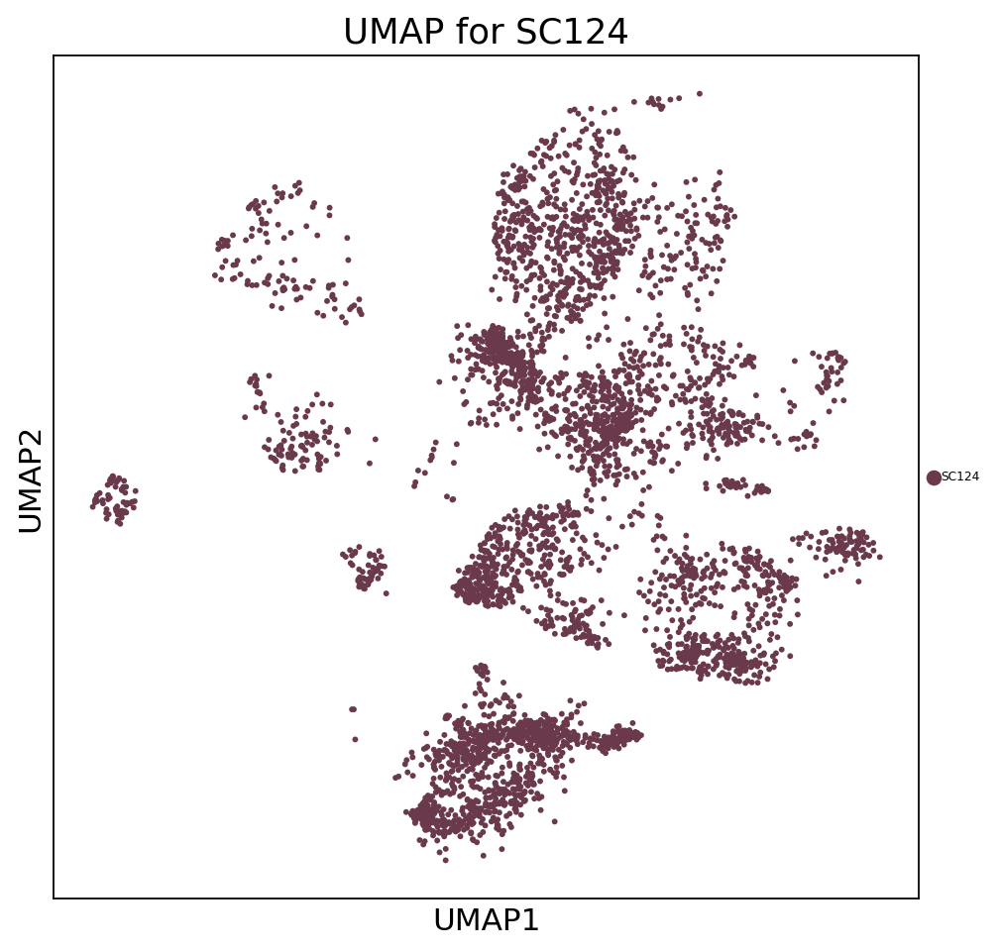

SC33


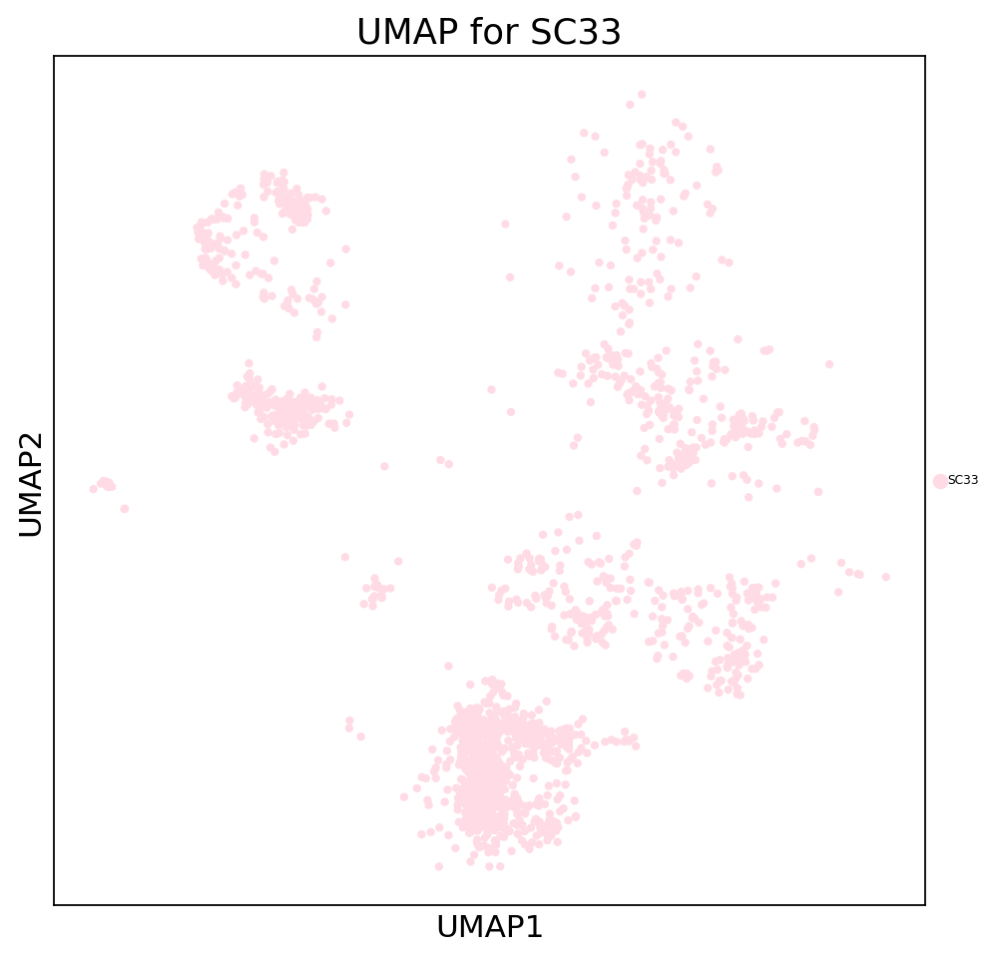

SC185


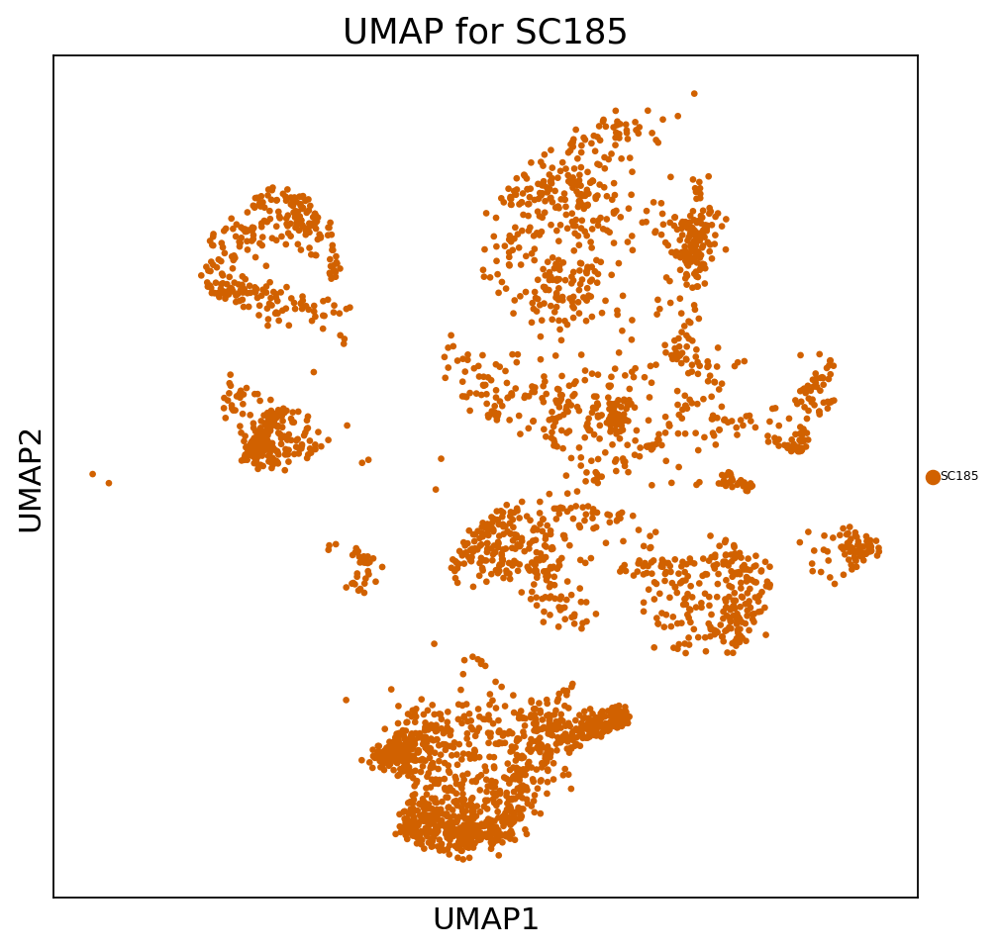

SC50


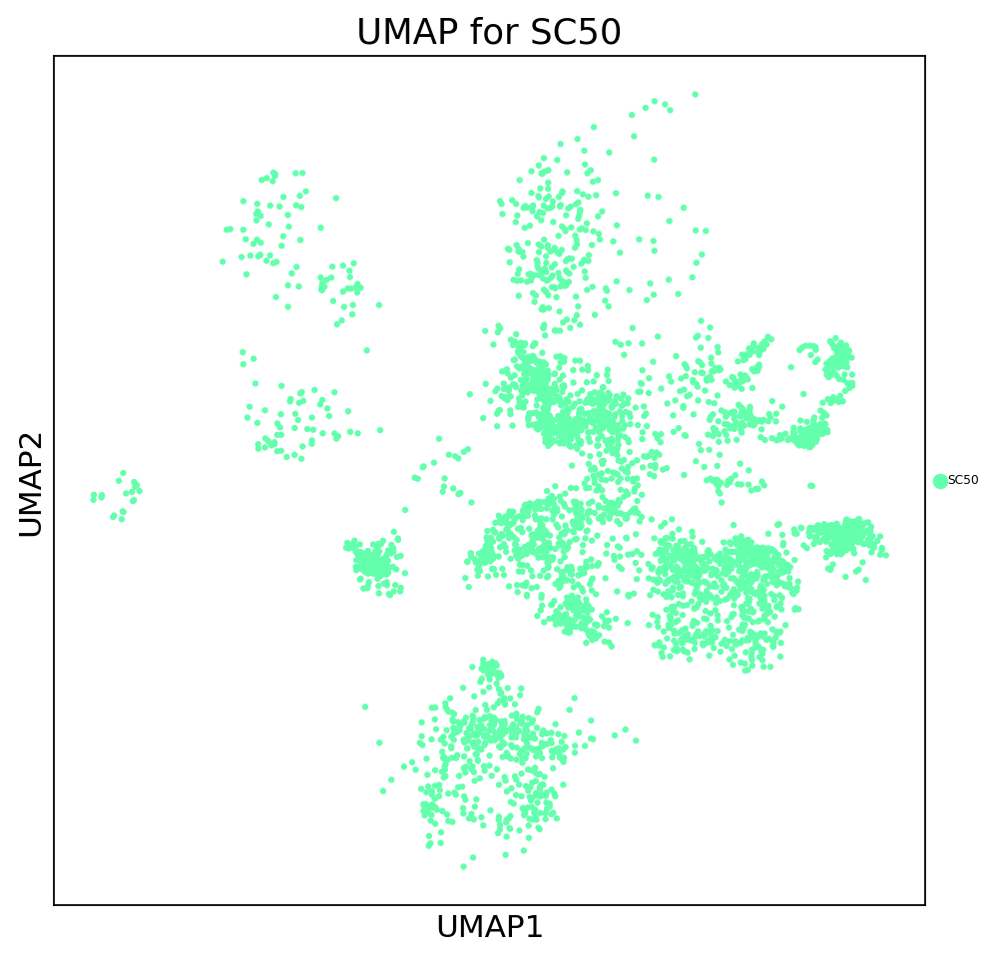

SC125


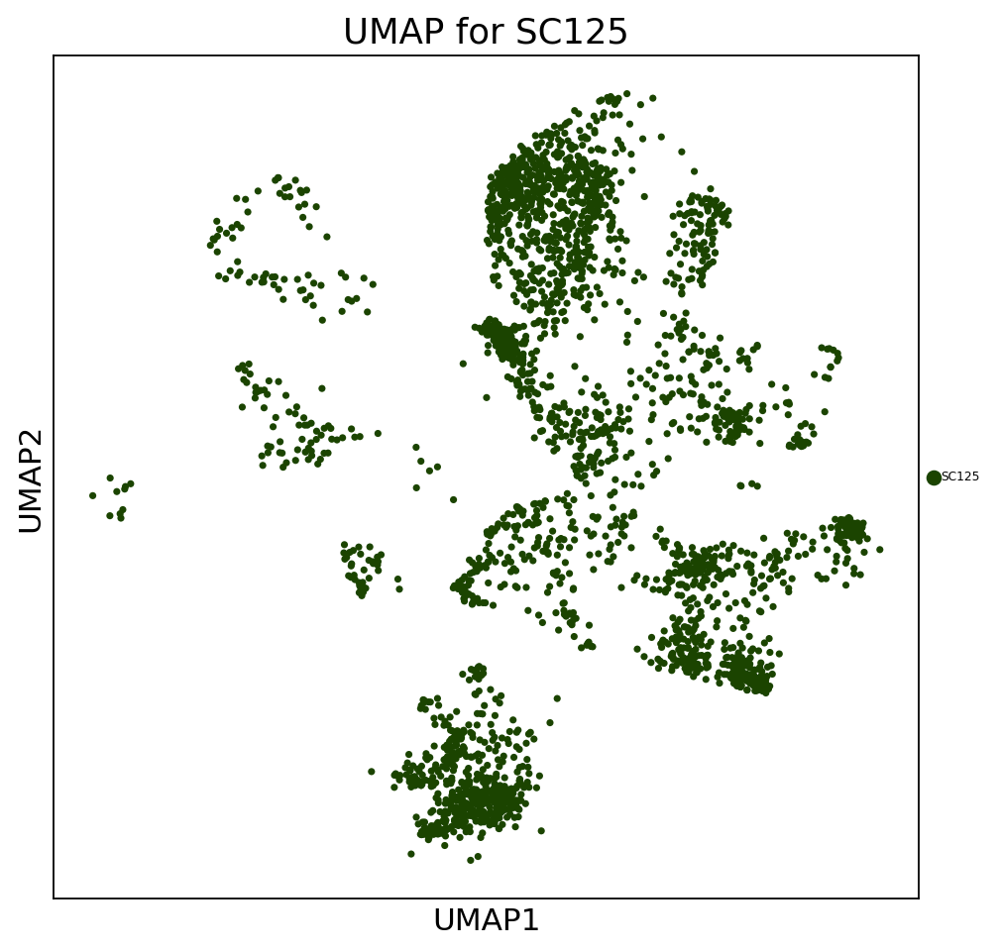

SC69


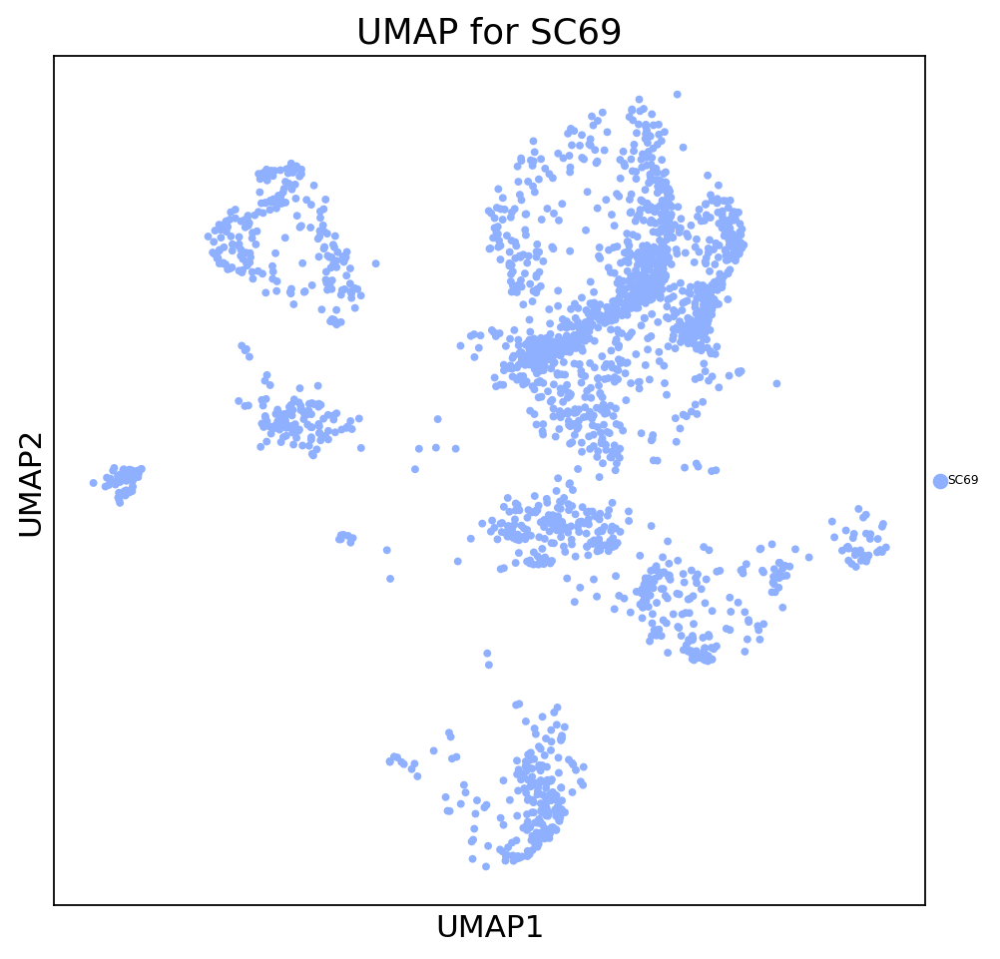

SC18


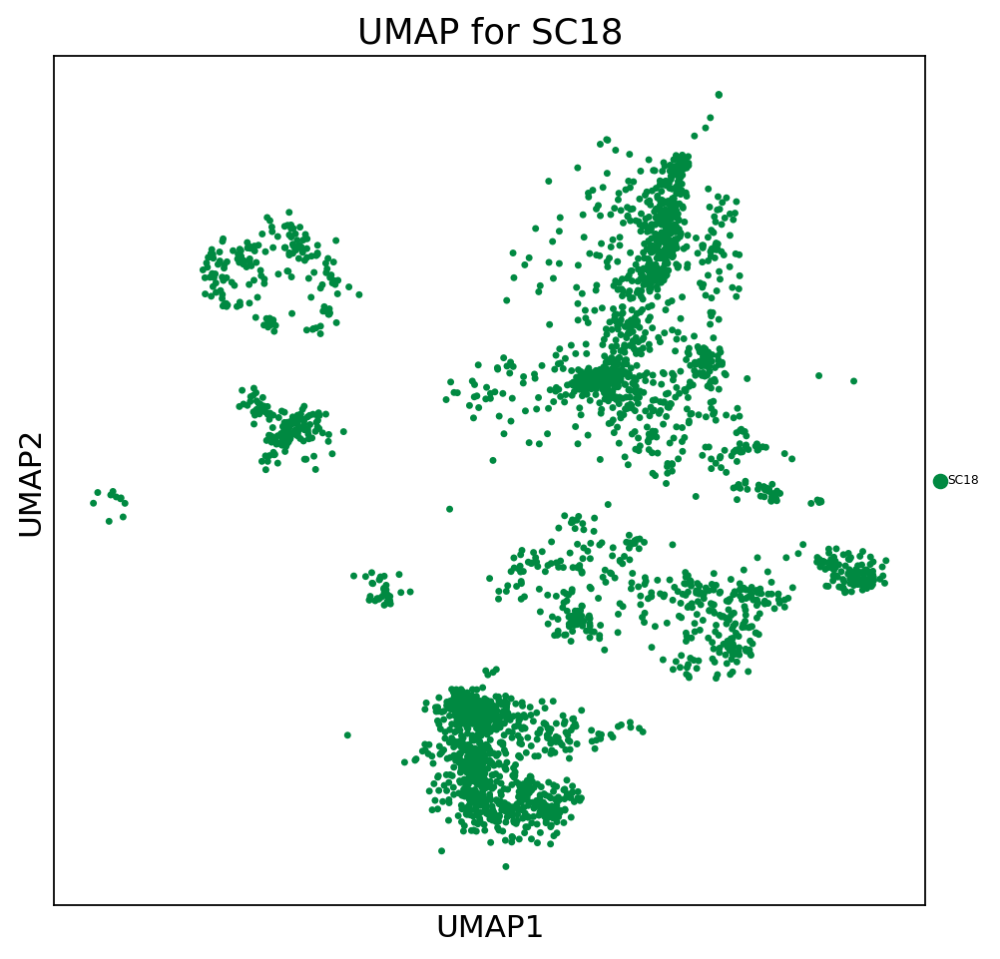

SC1


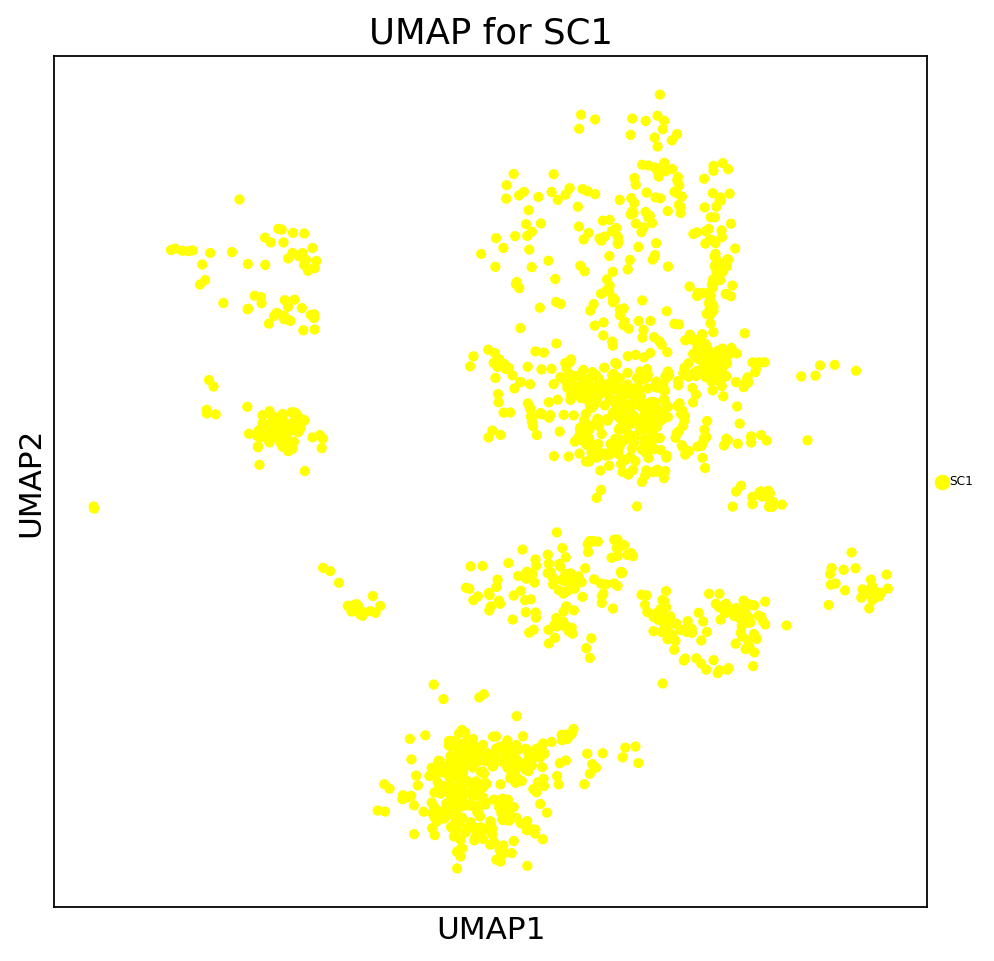

SC68


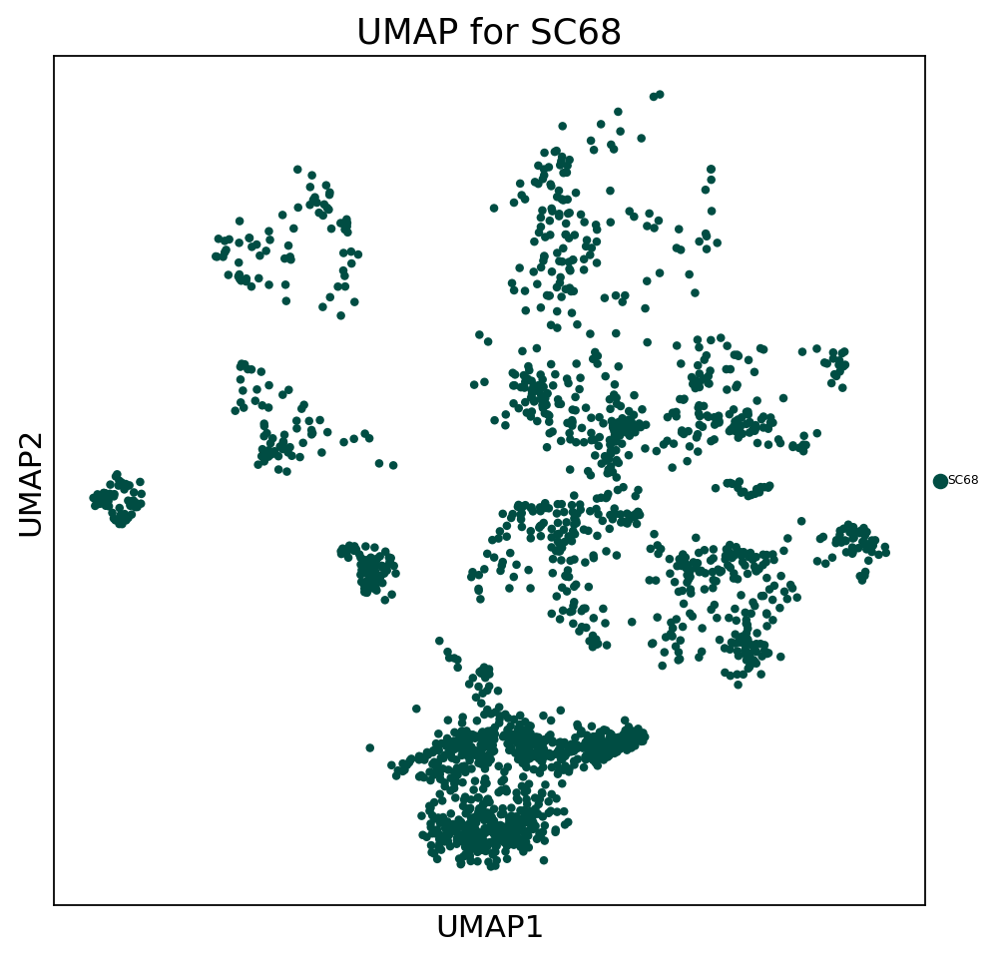

SC34


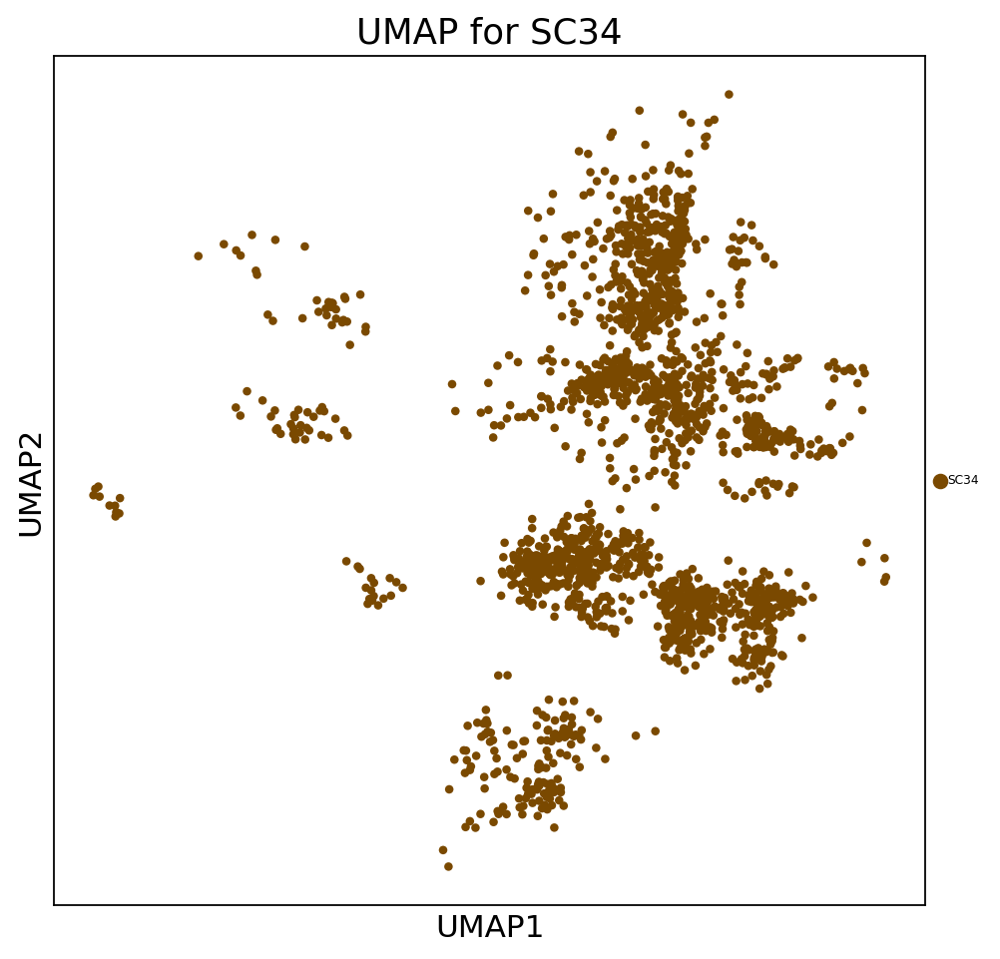

SC119


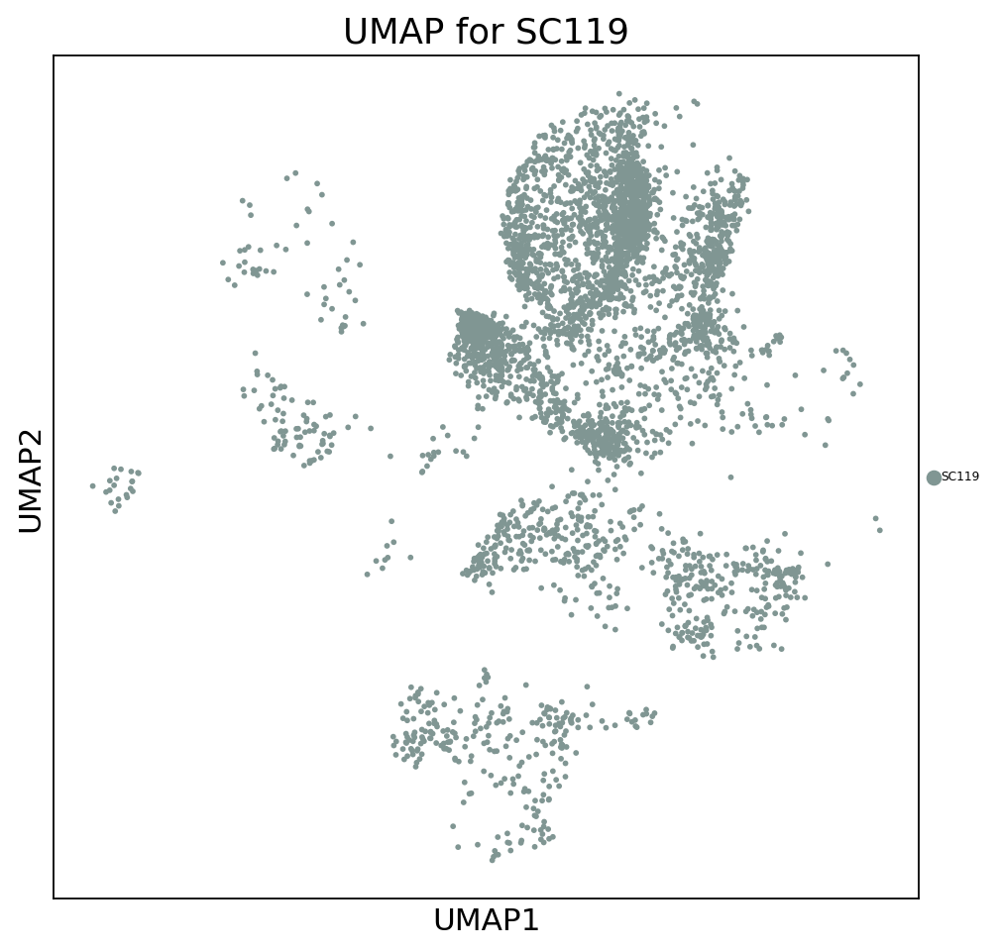

SC70


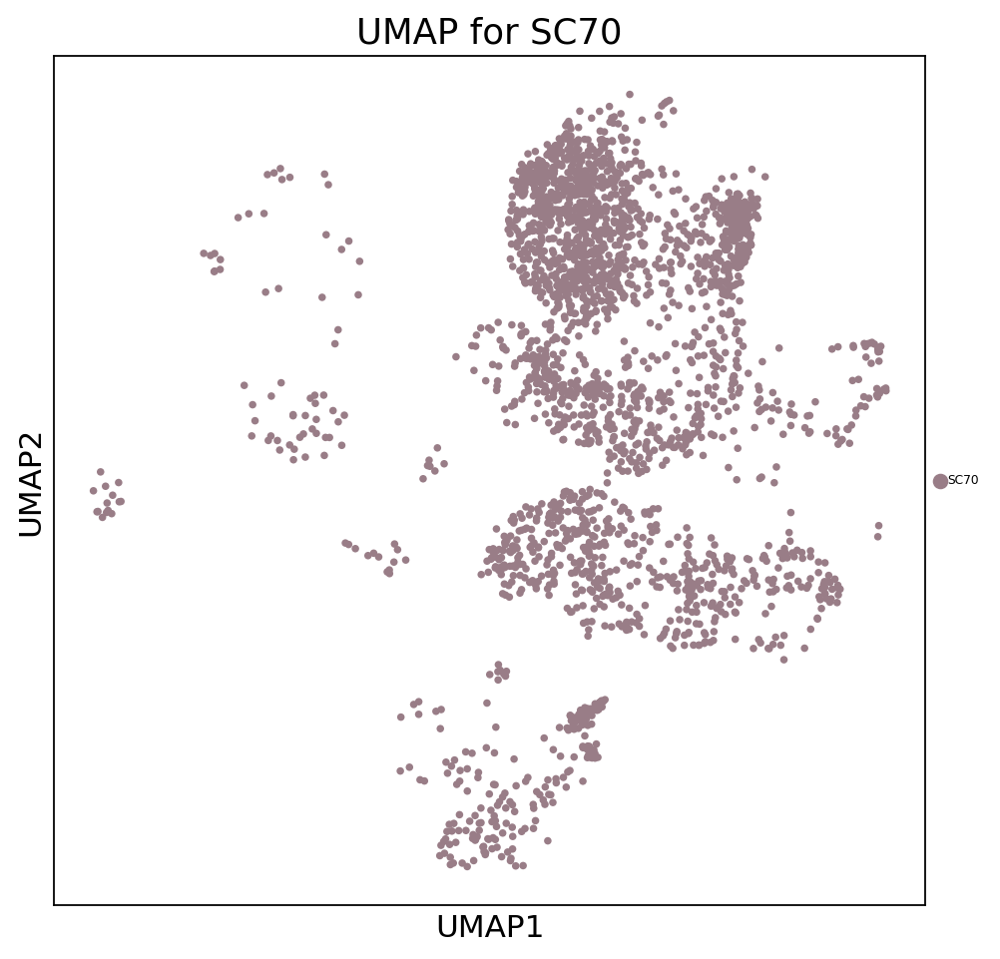

SC19


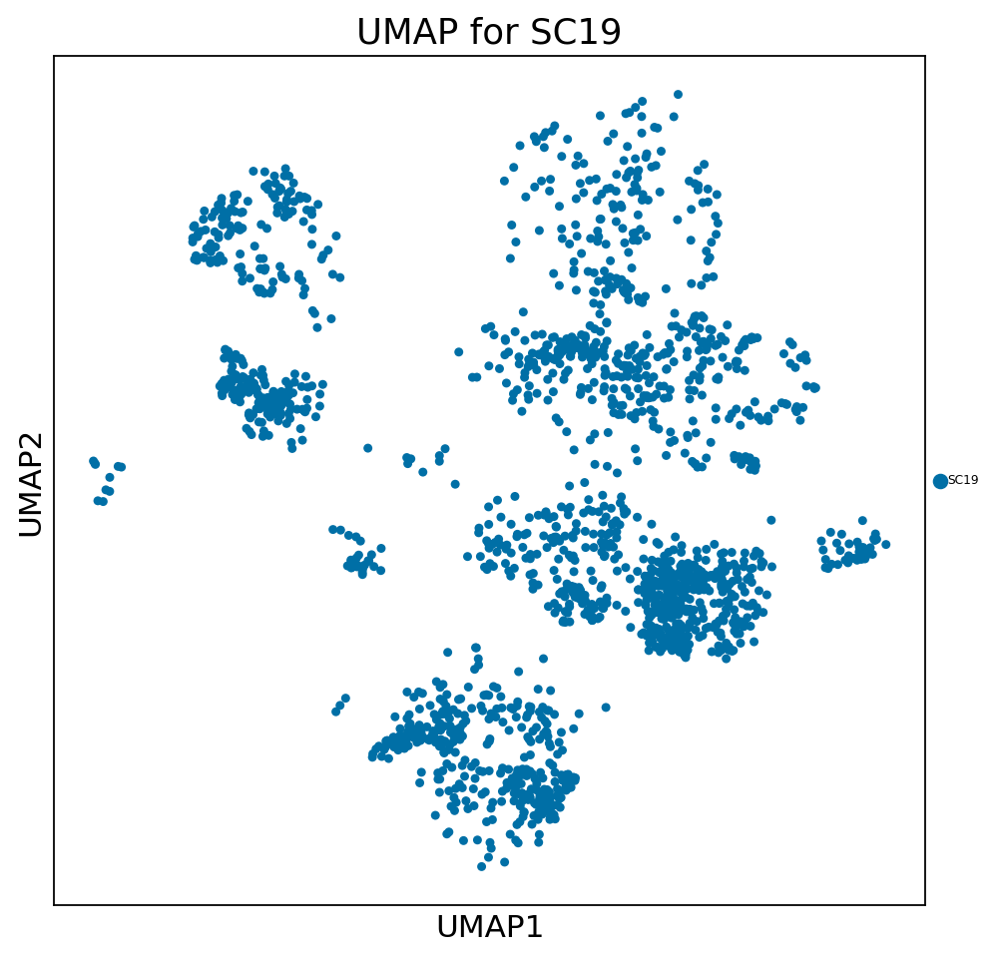

SC2


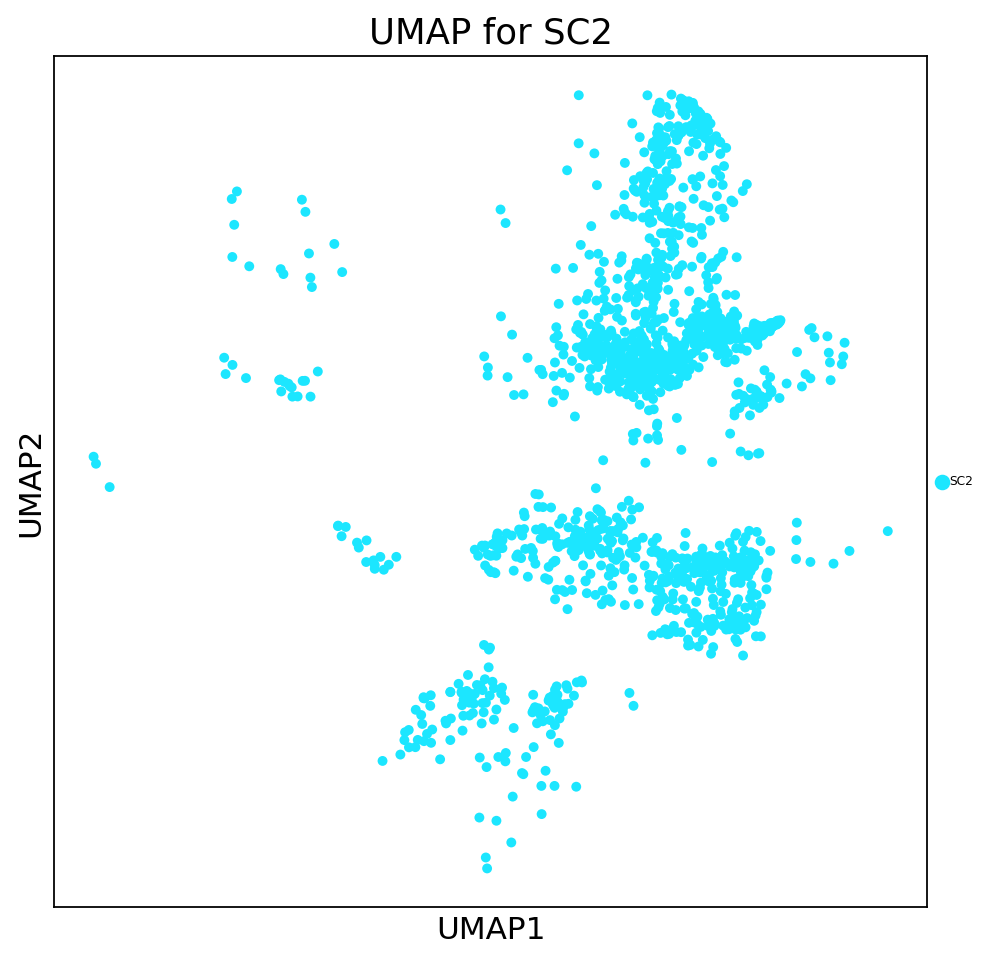

SC5


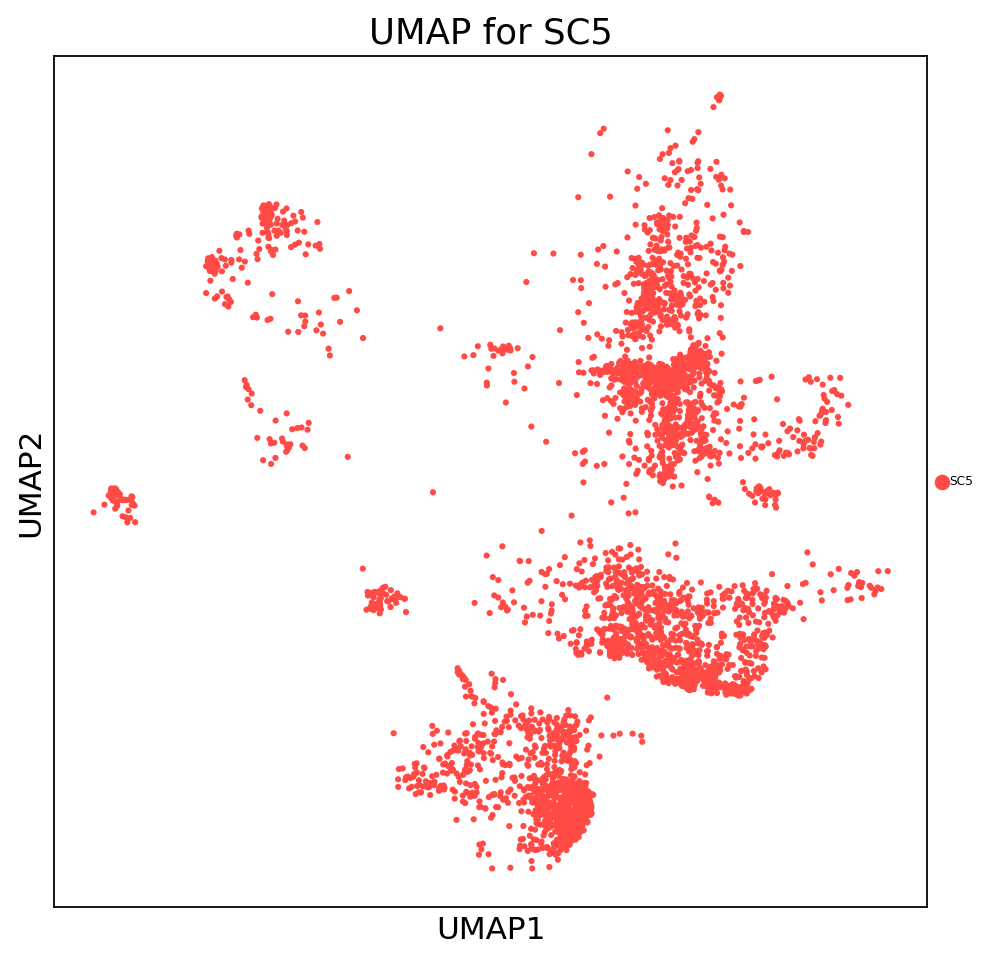

SC188


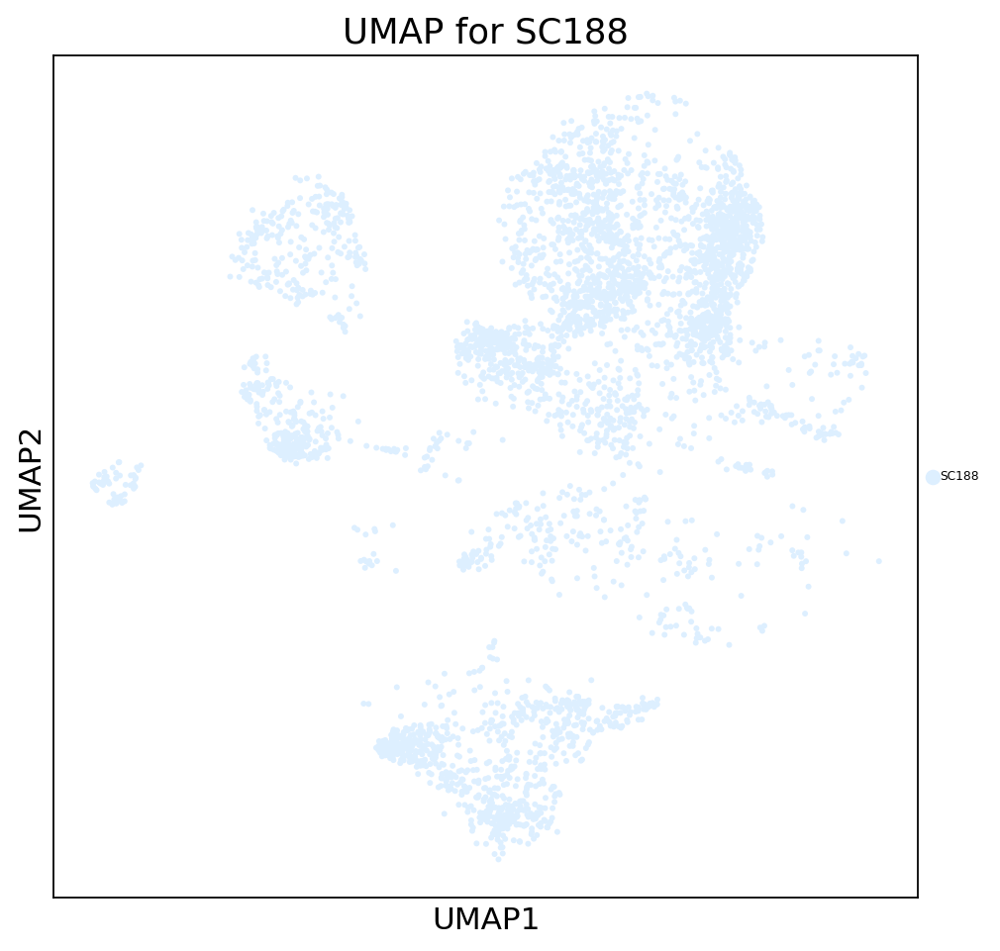

SC60


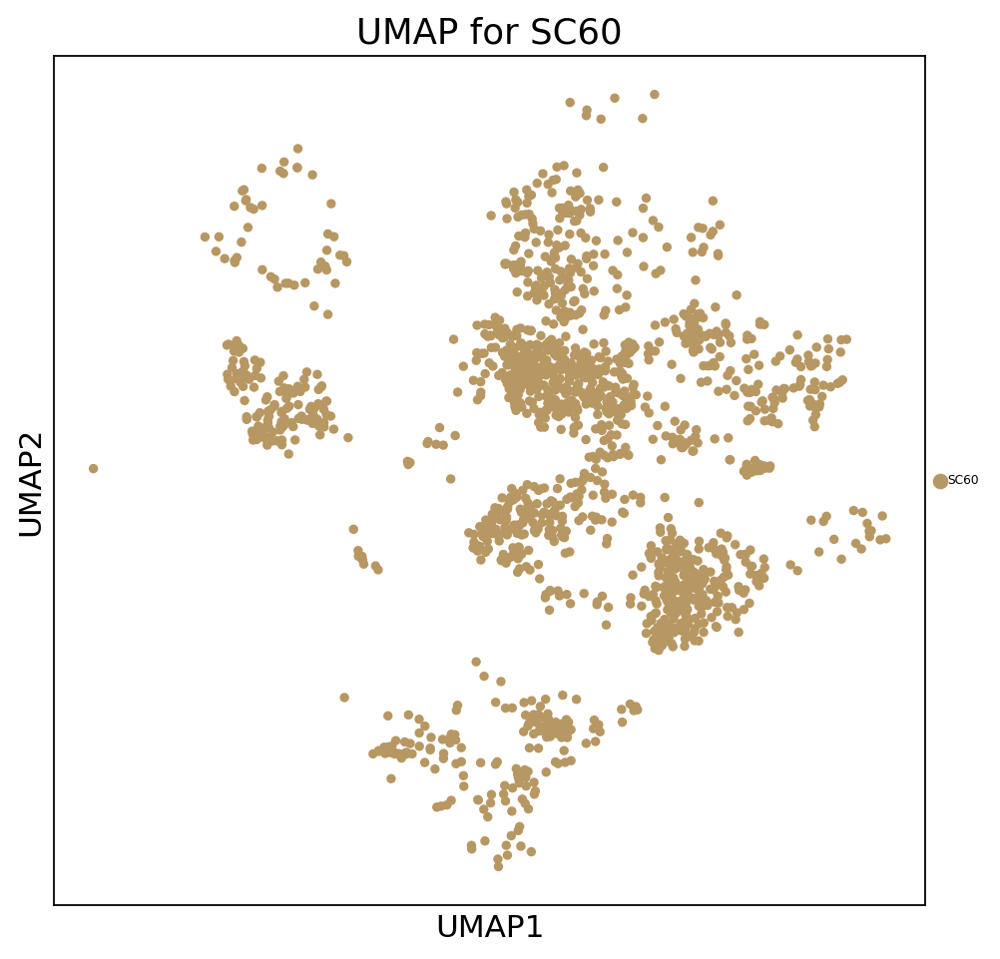

SC189


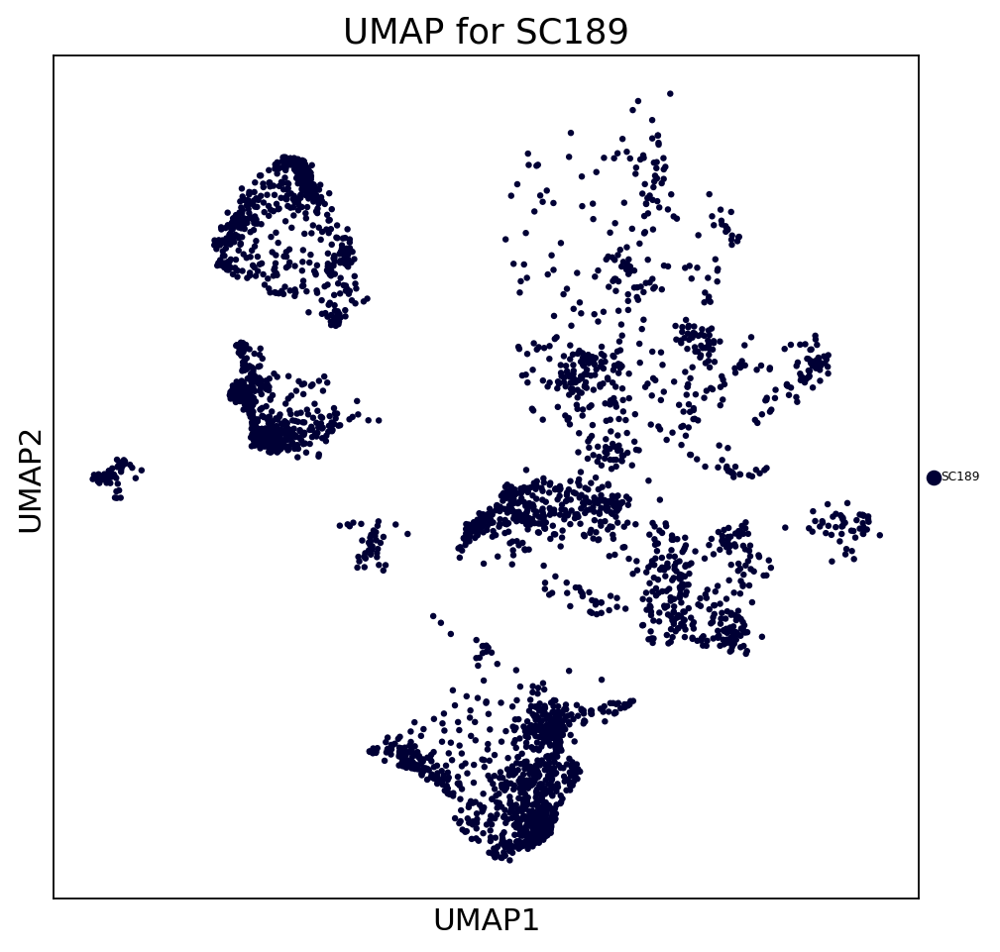

SC4


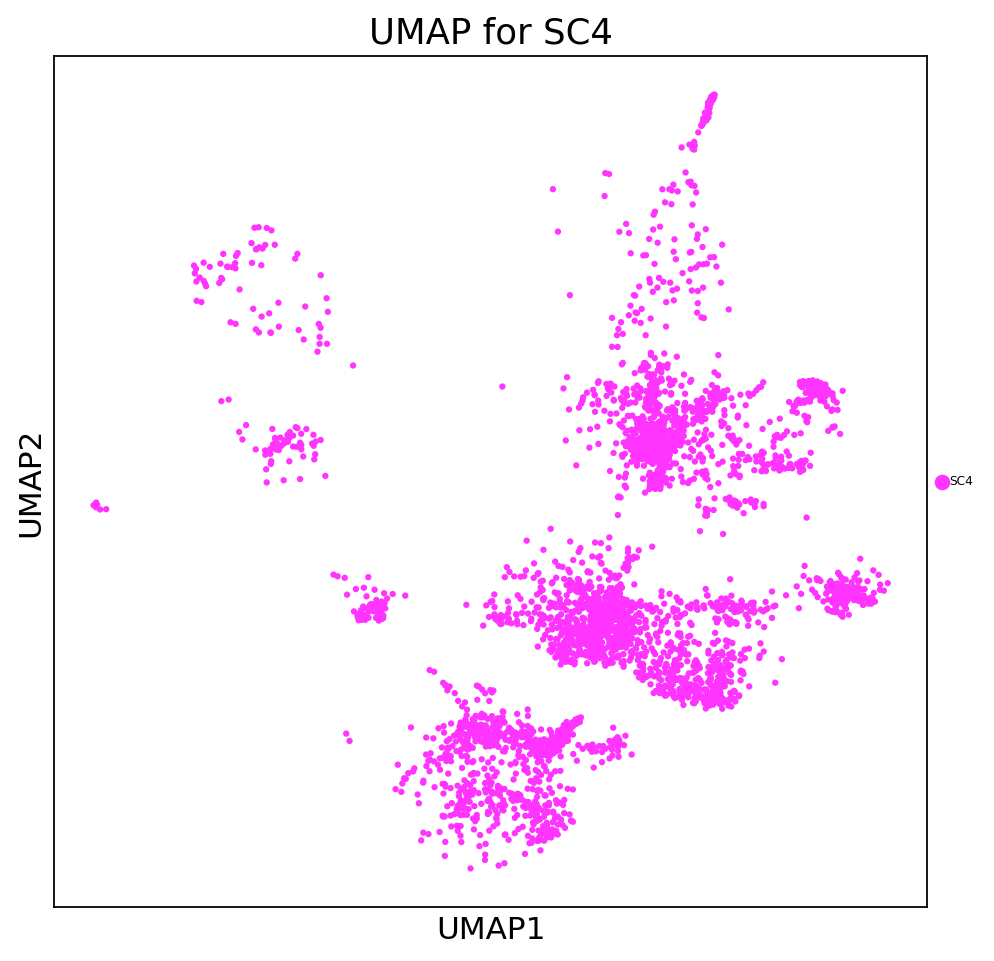

SC86


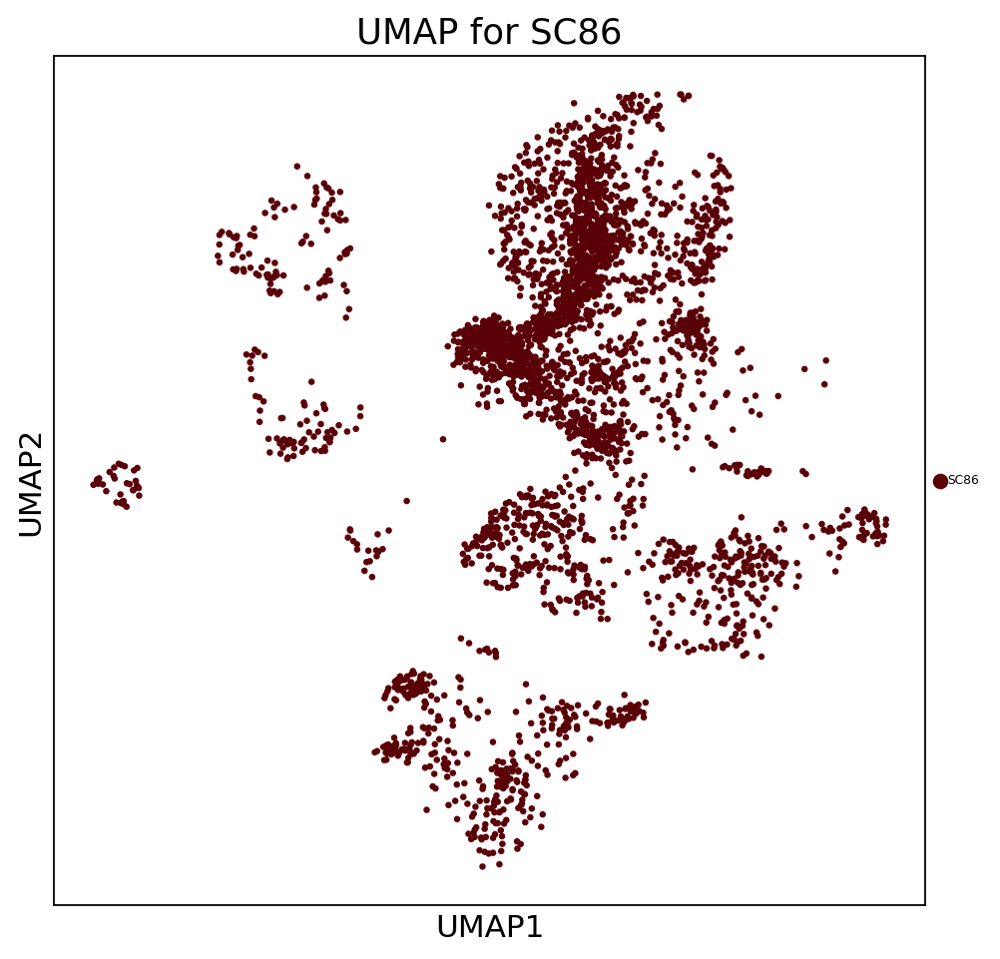

SC49


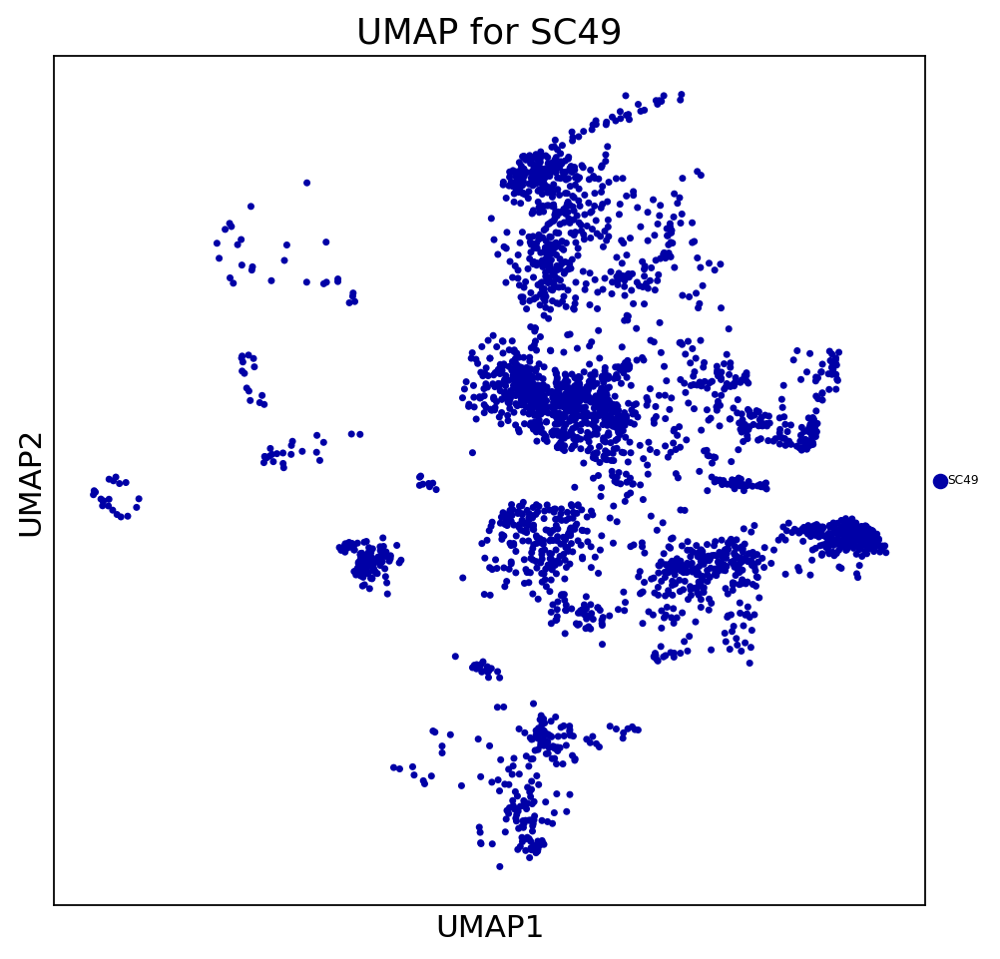

SC32


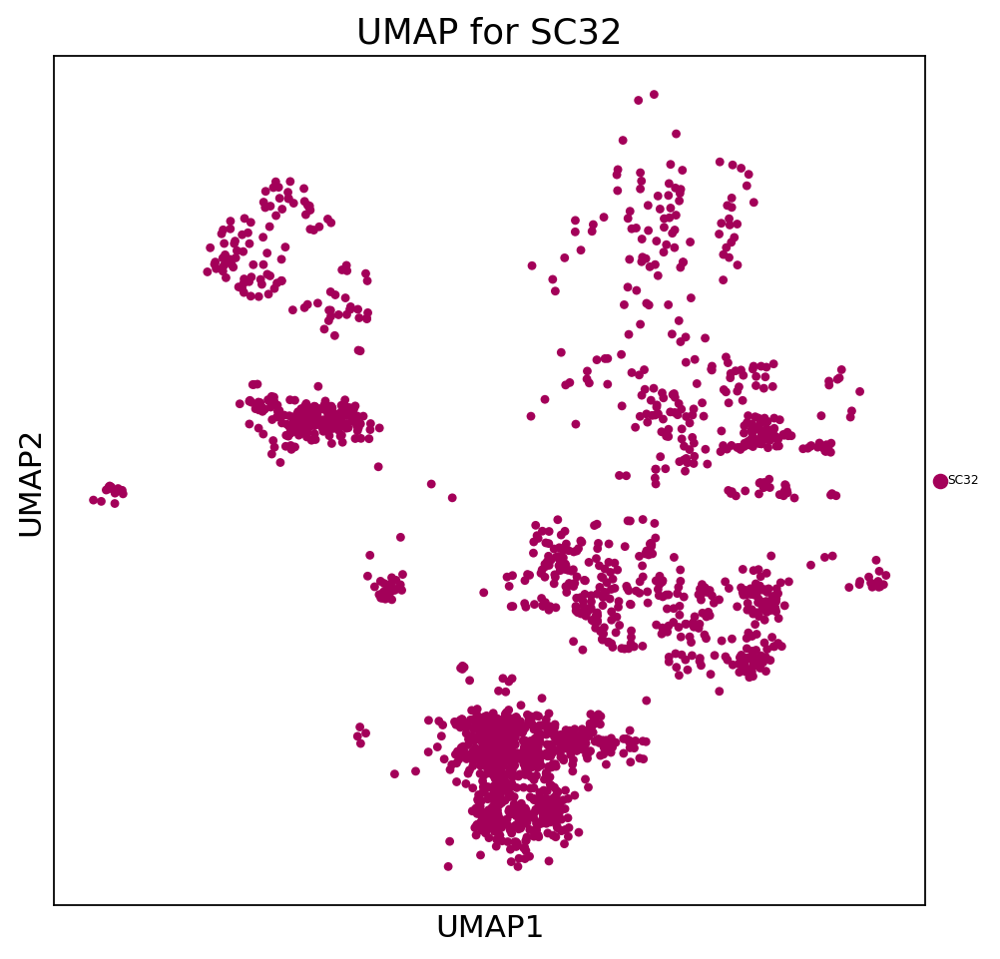

SC183


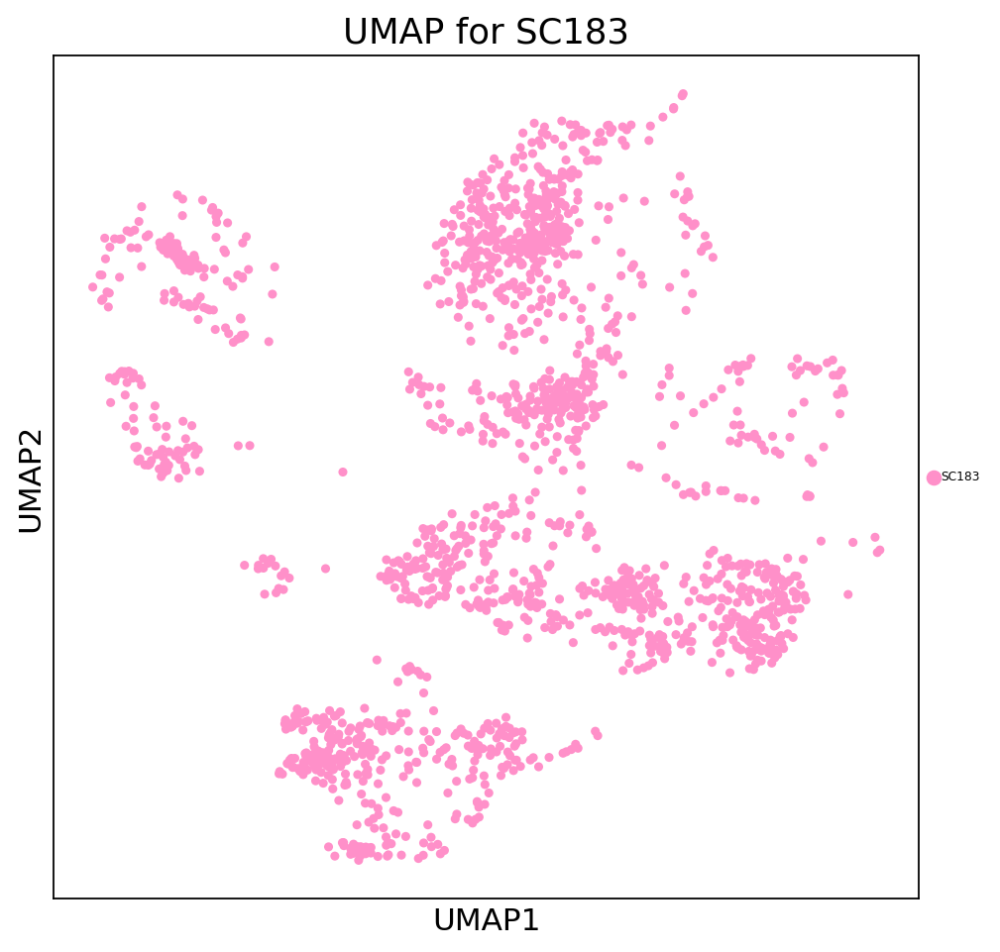

SC229


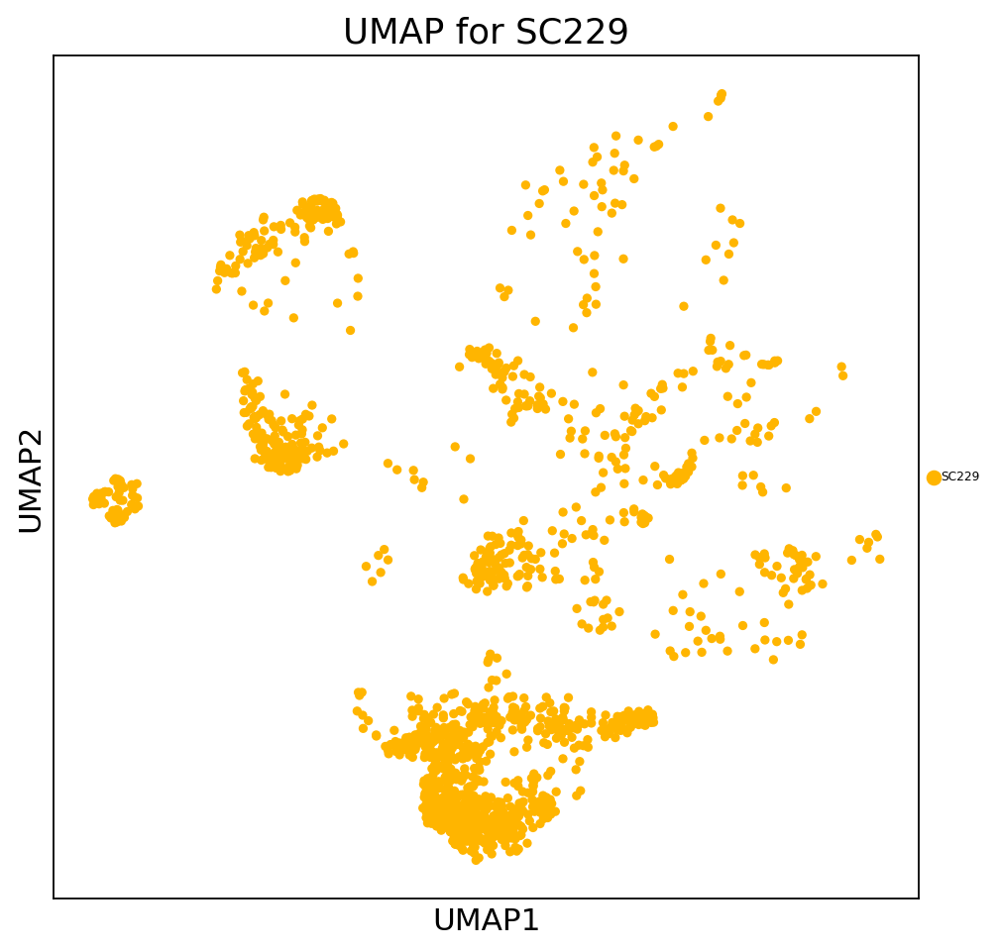

SC240


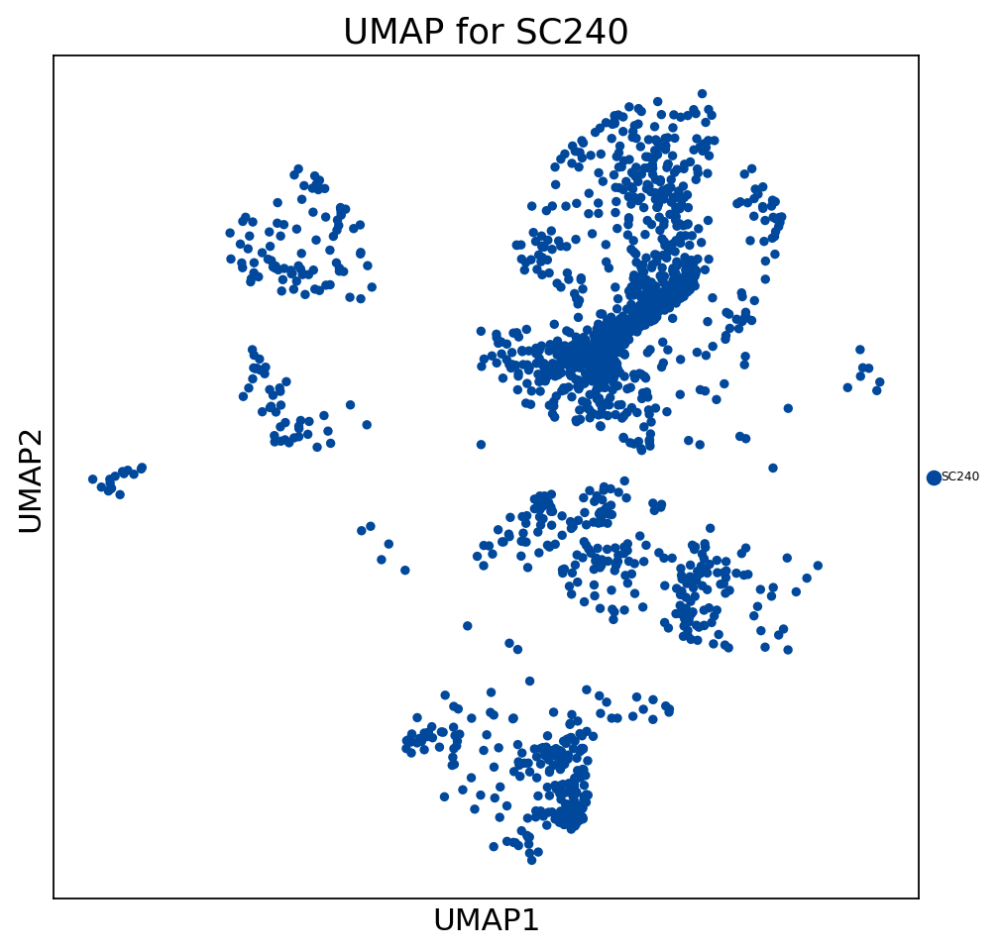

SC236


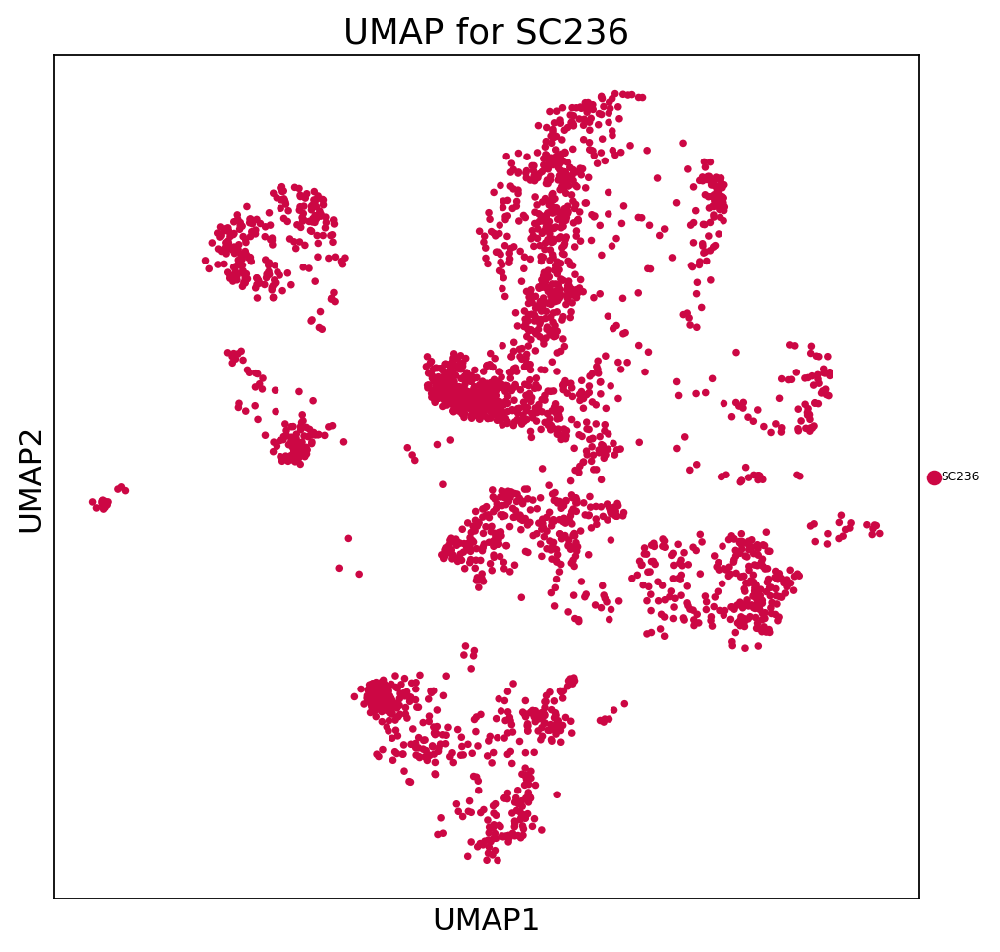

SC178


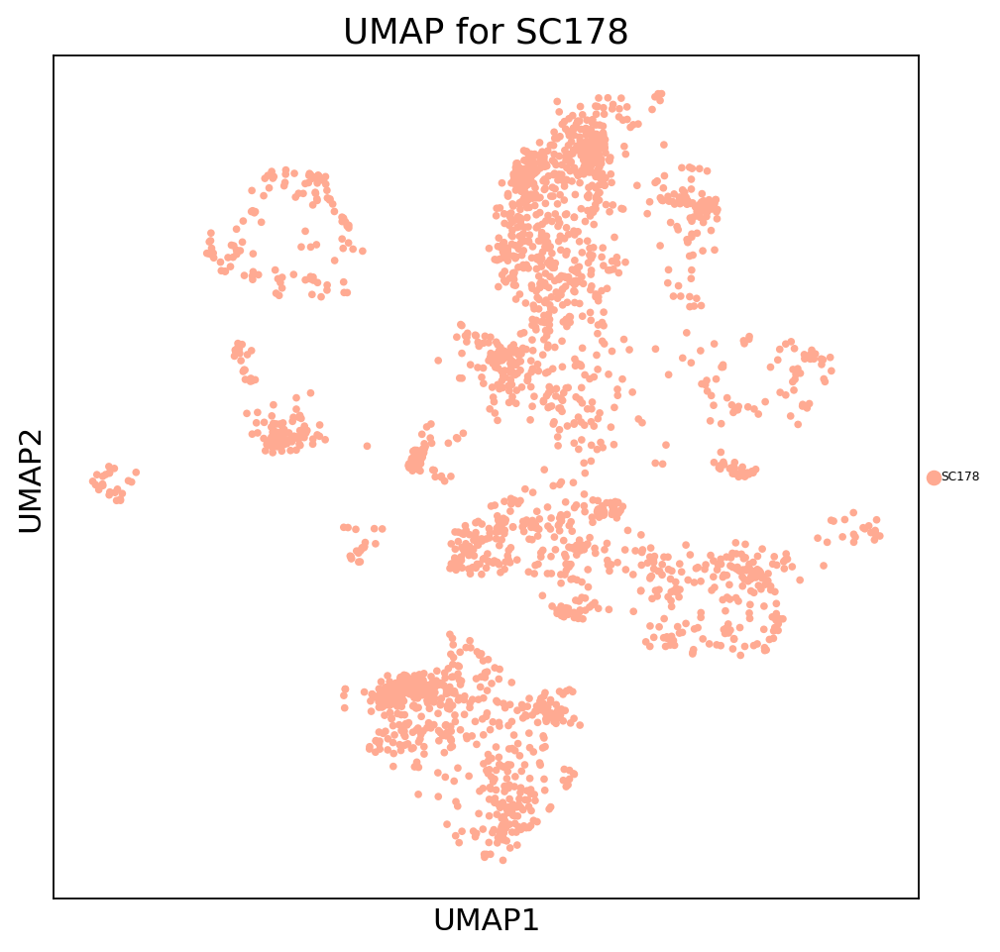

SC159


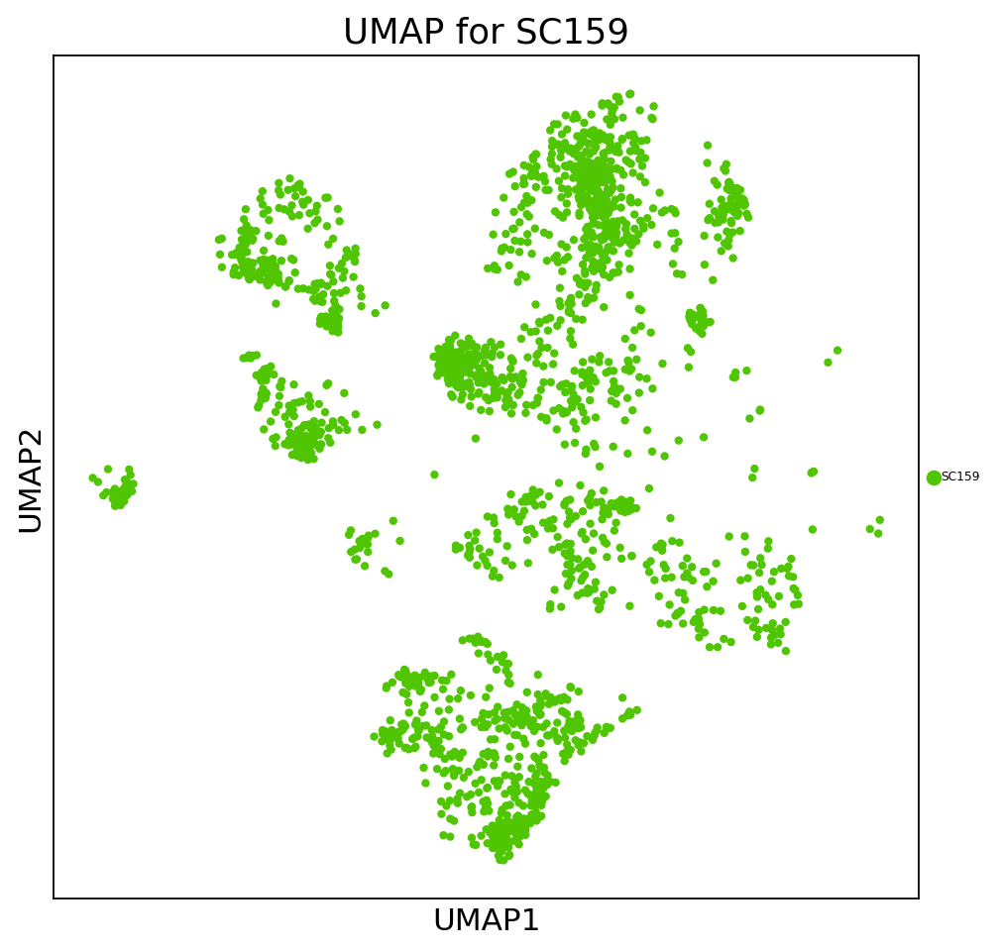

SC254


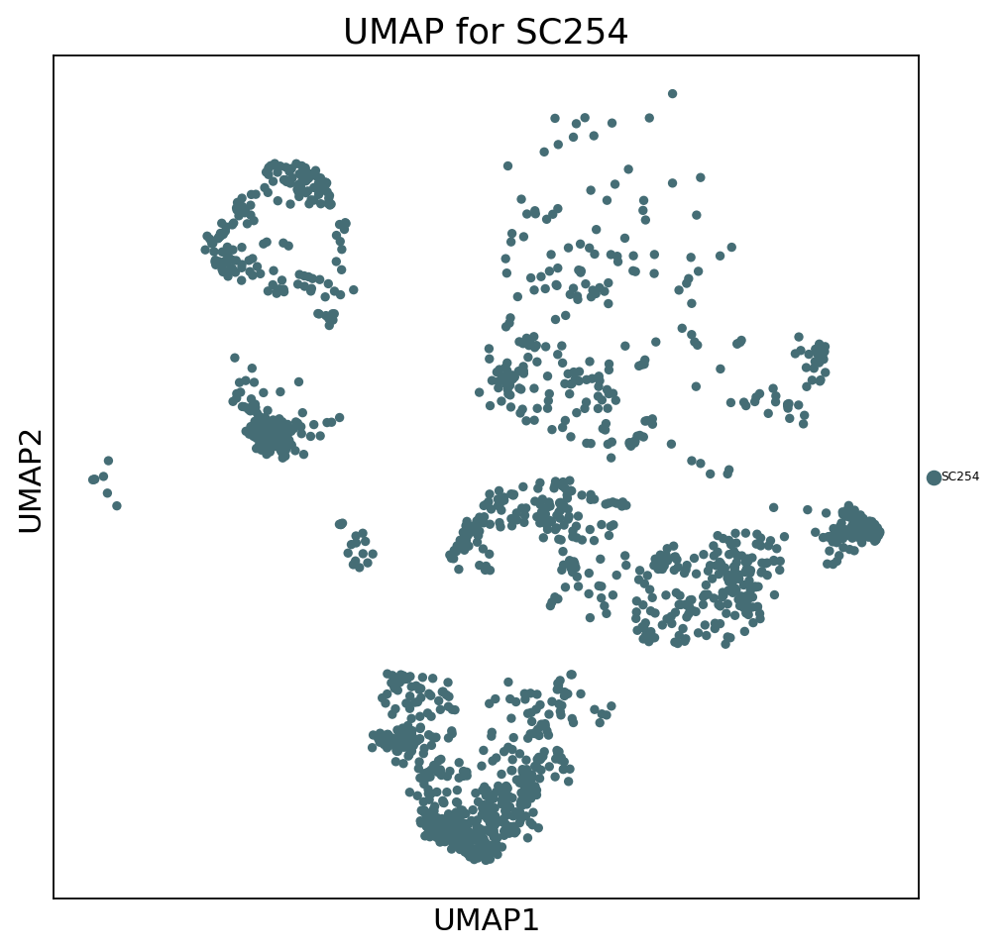

SC238


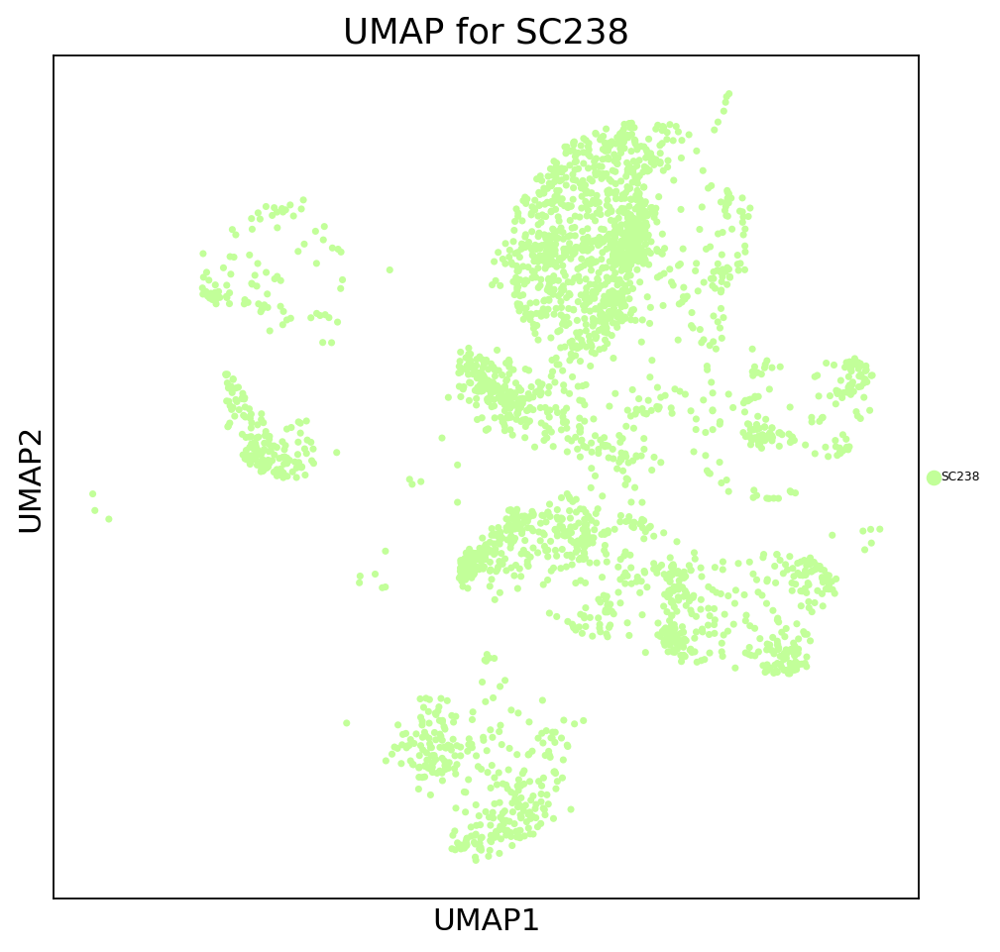

SC230


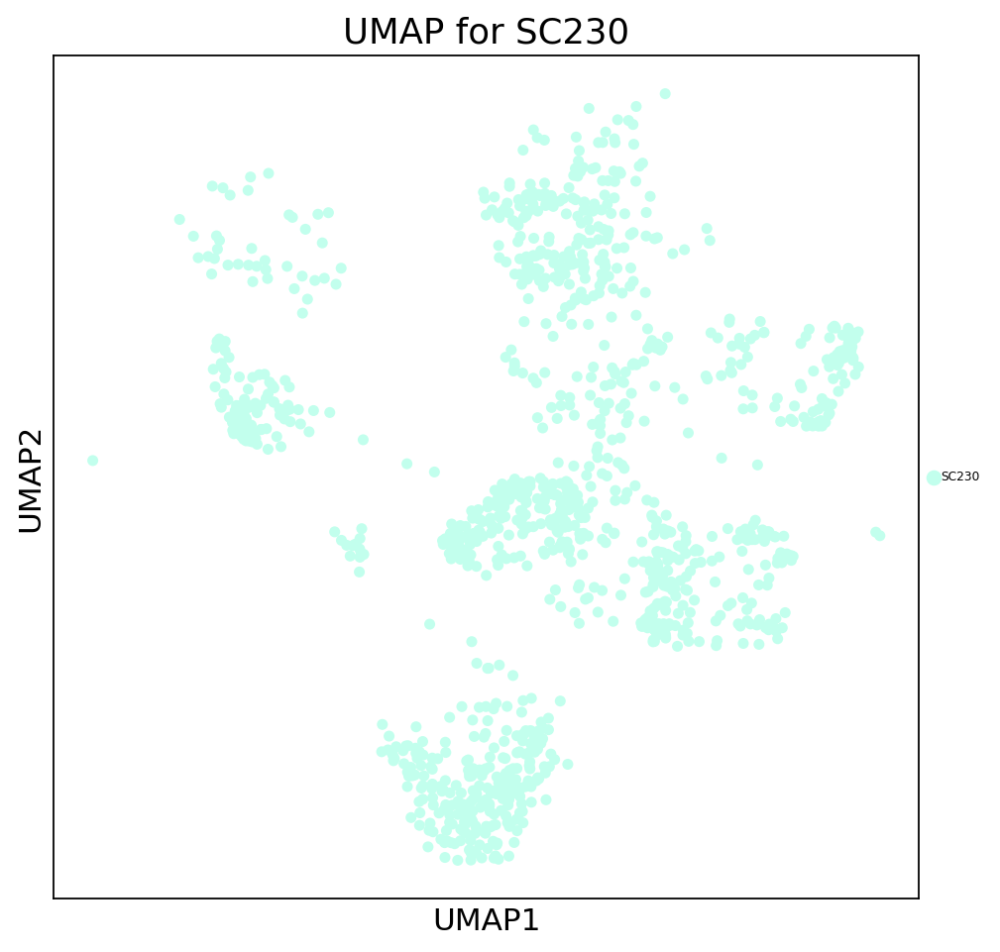

SC237


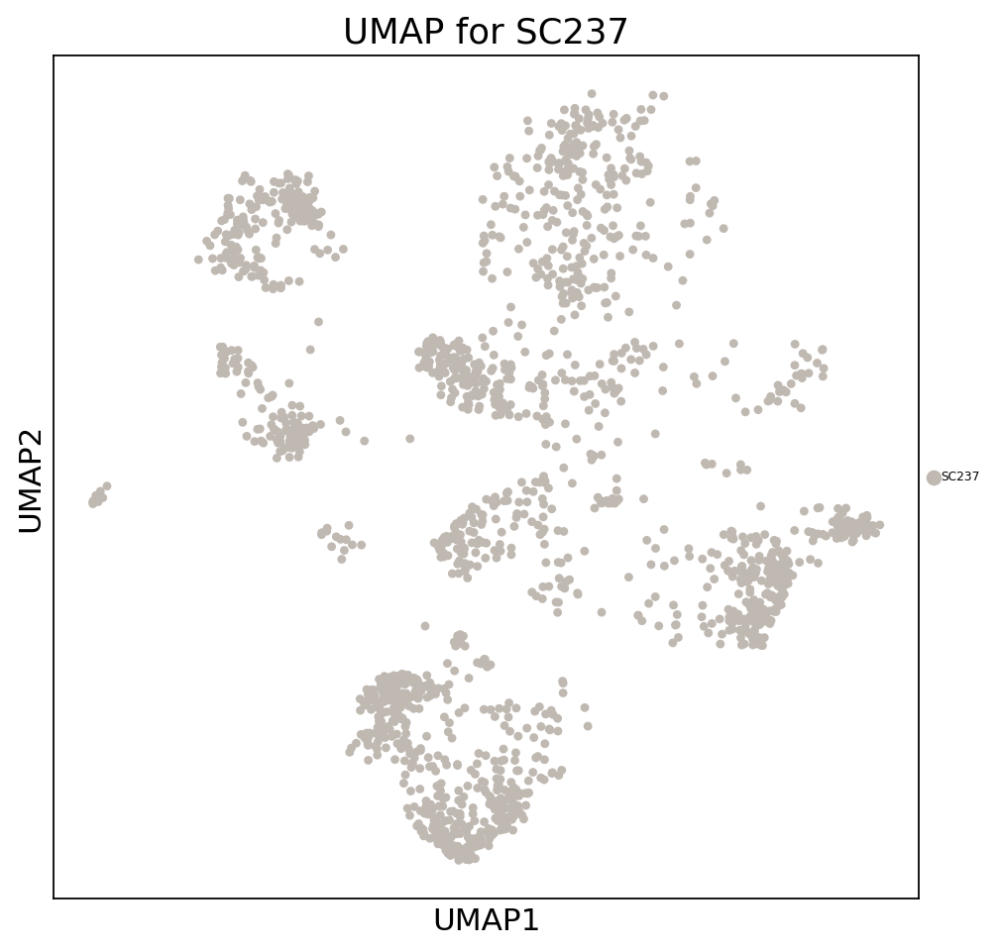

SC225


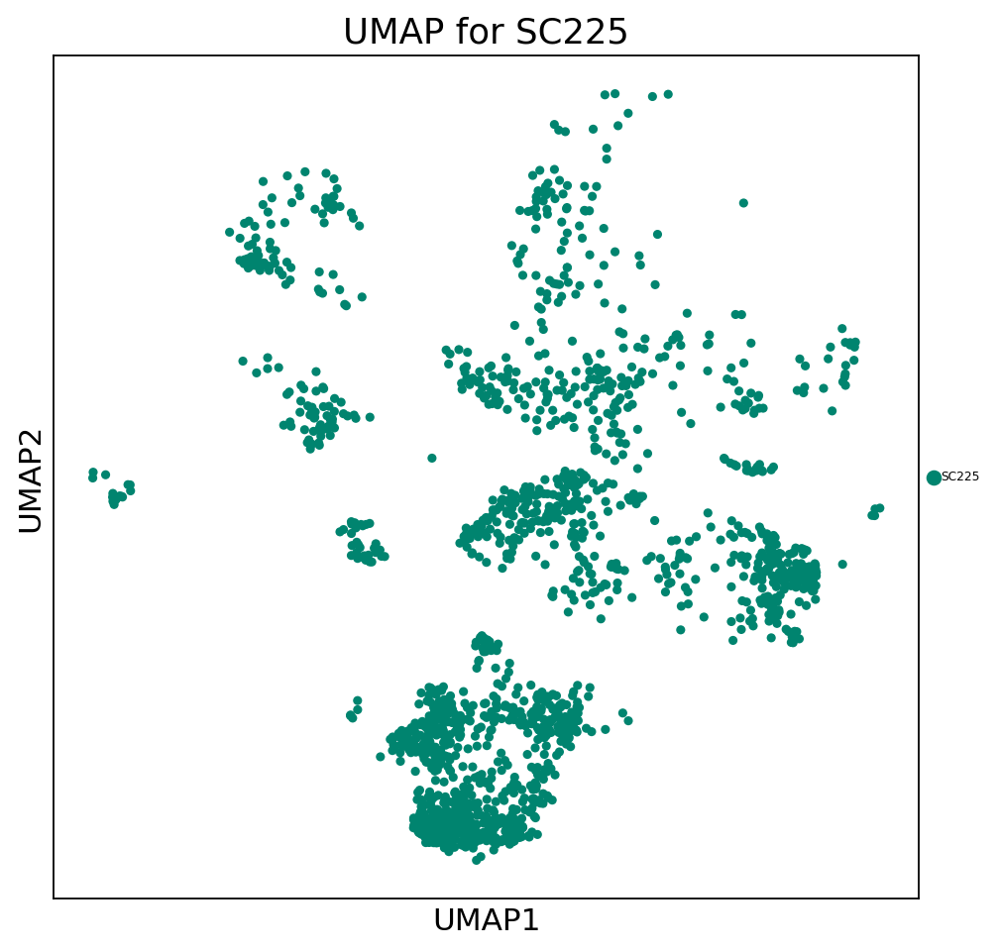

SC245


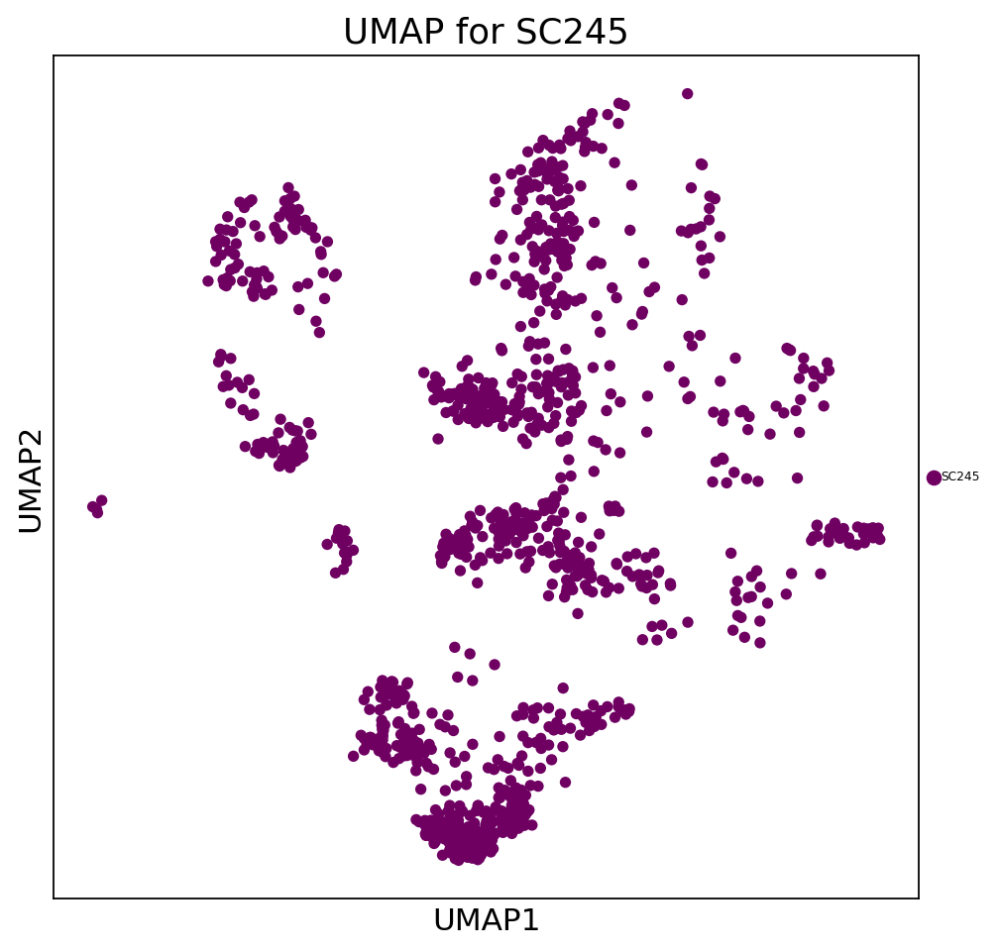

SC247


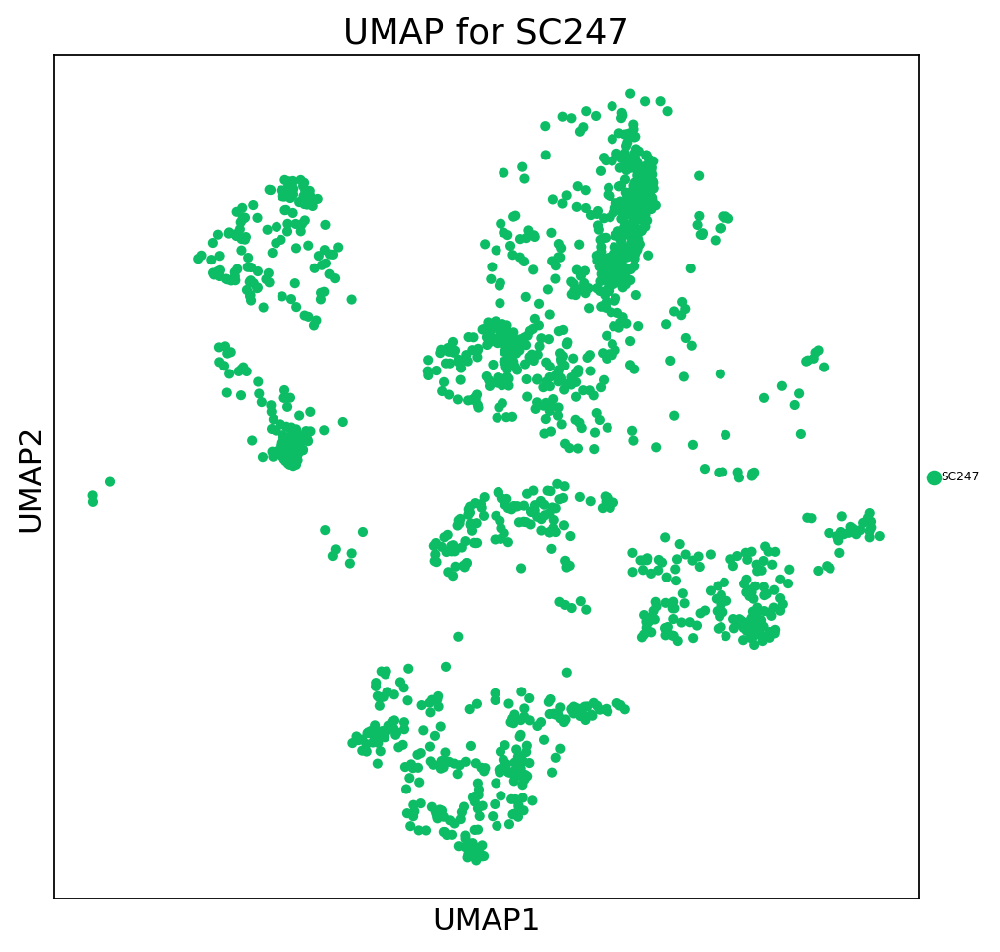

SC235


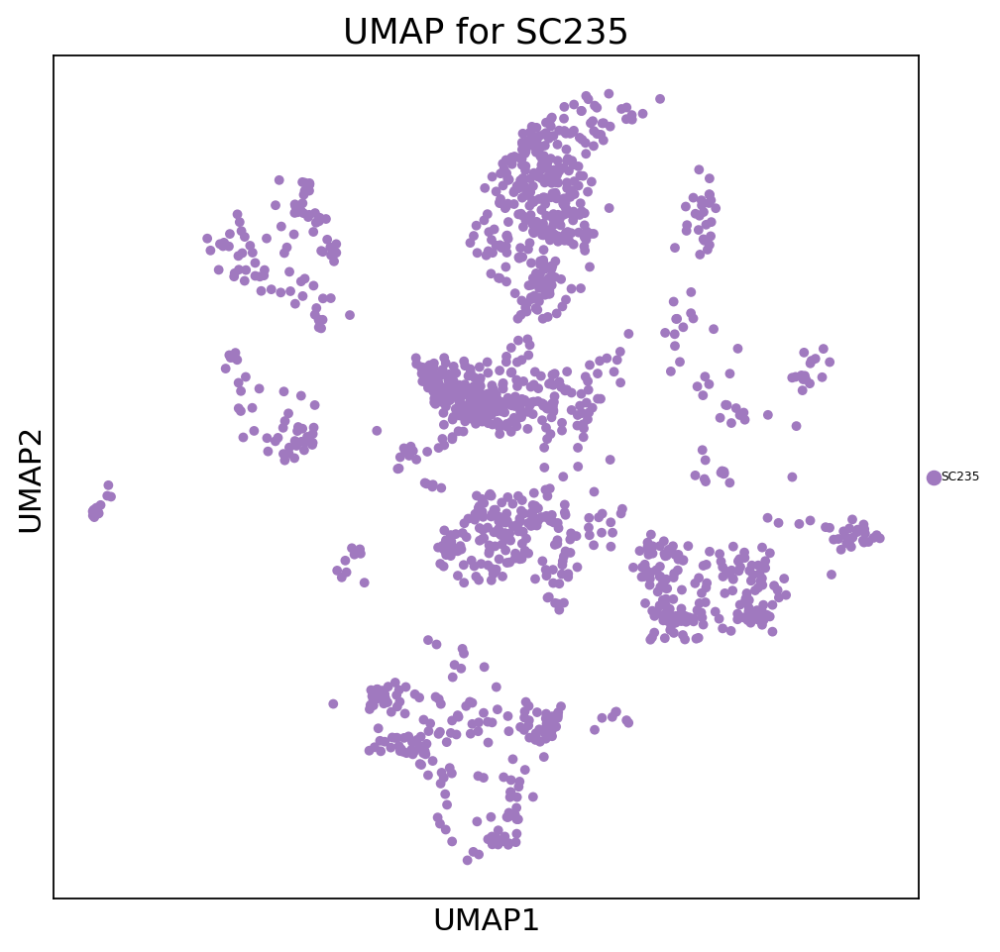

SC202


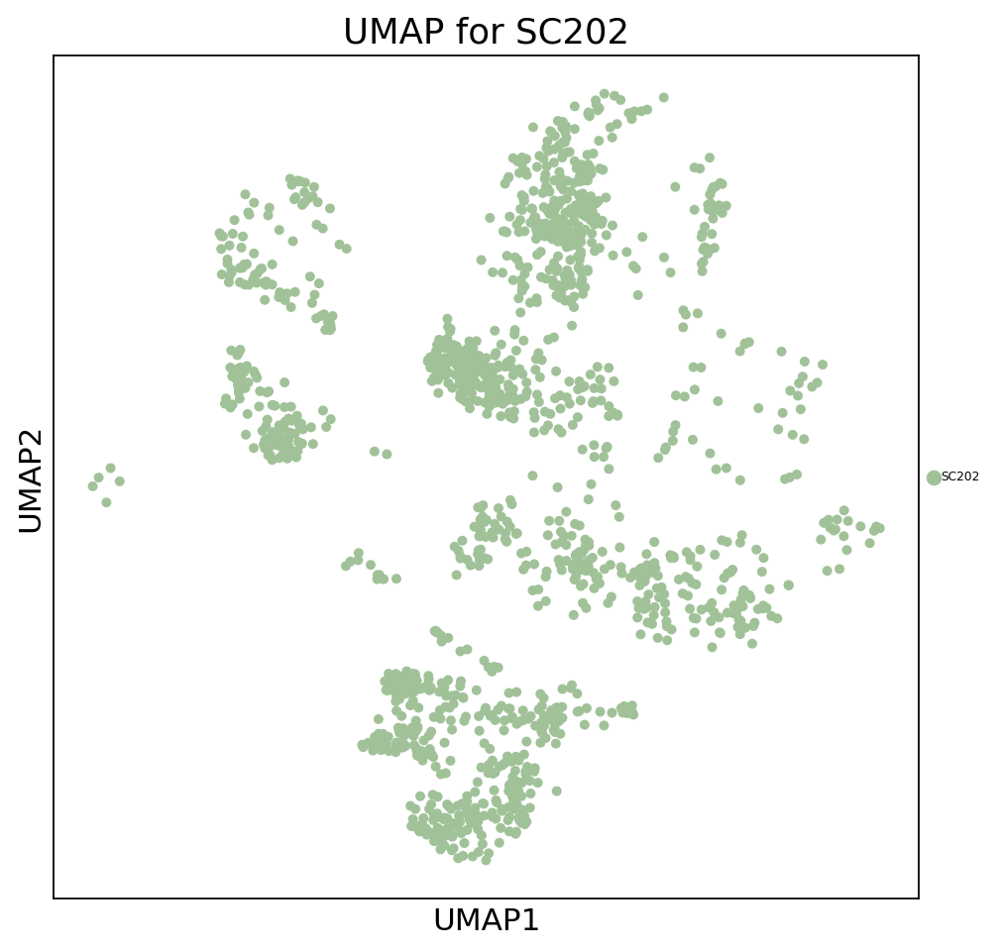

SC184


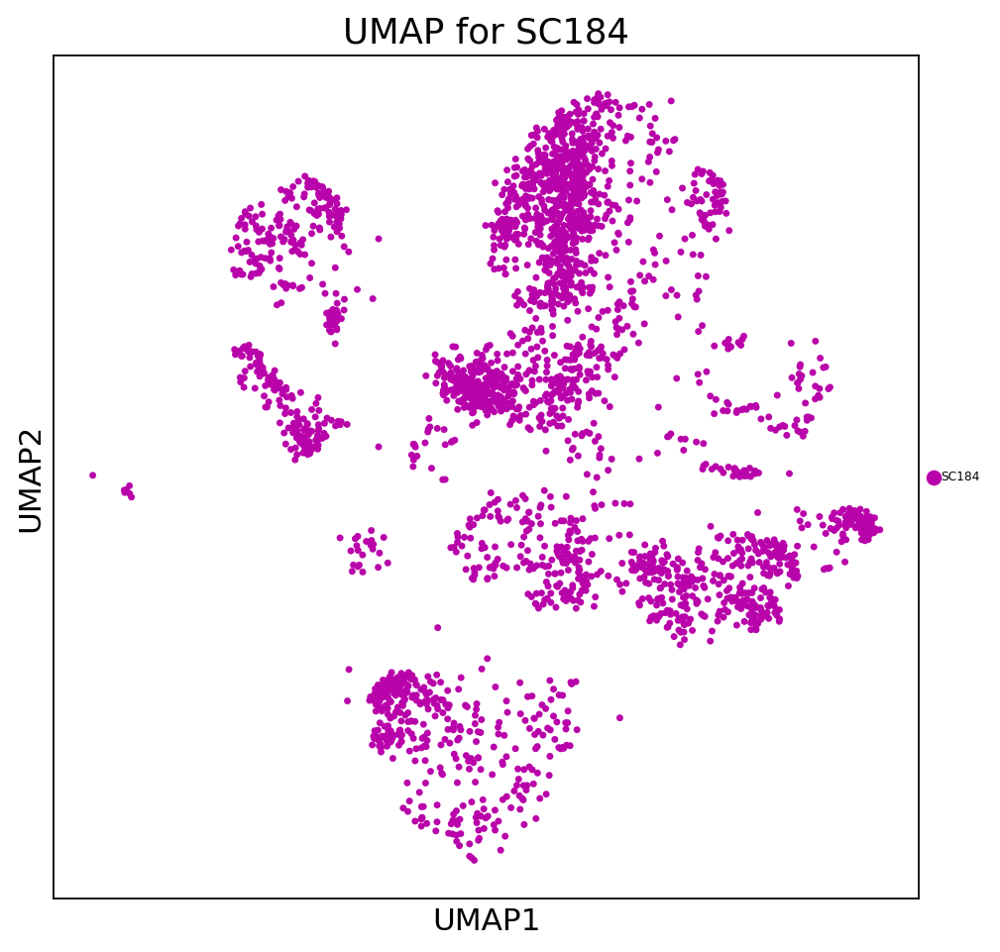

SC226


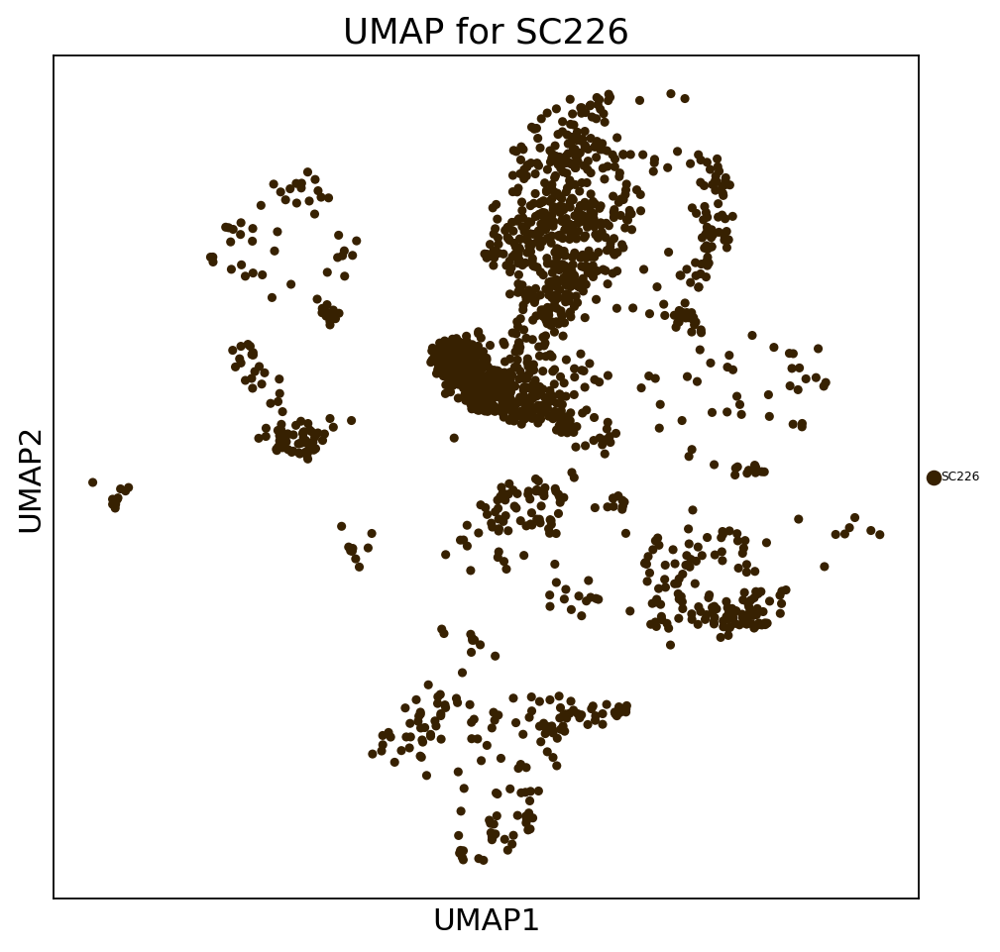

SC169


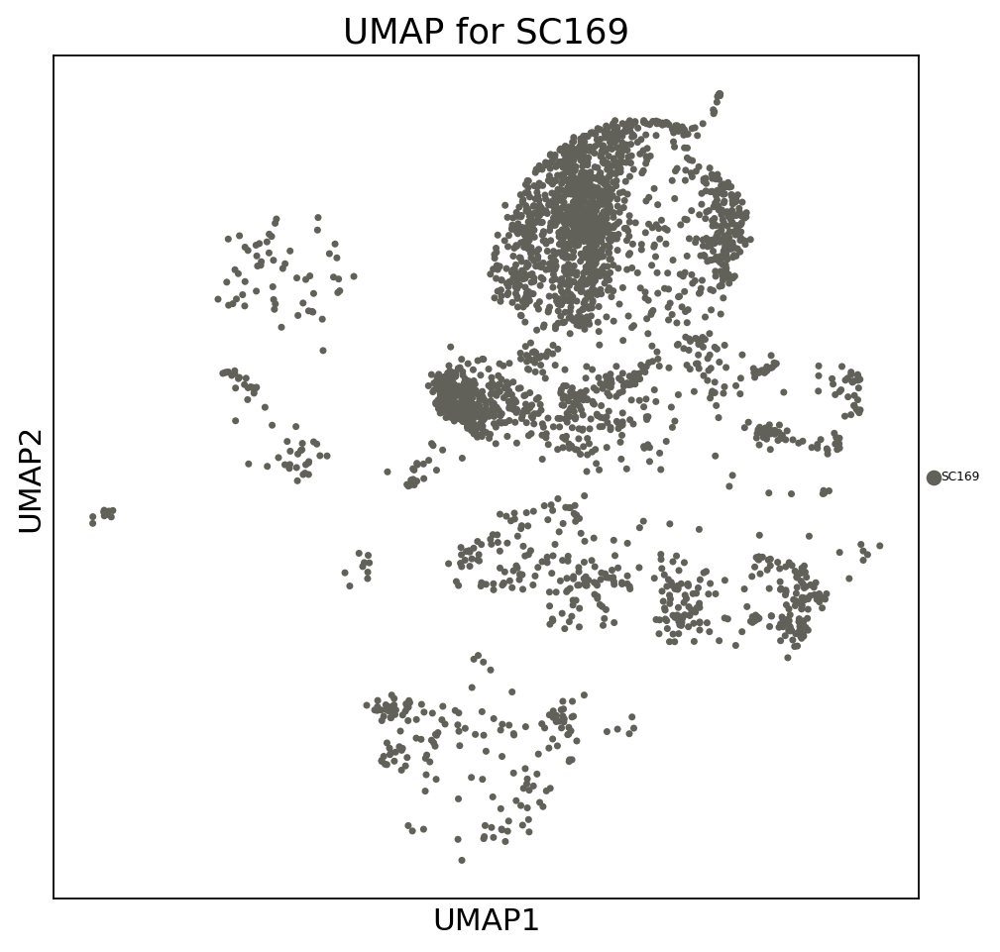

SC164


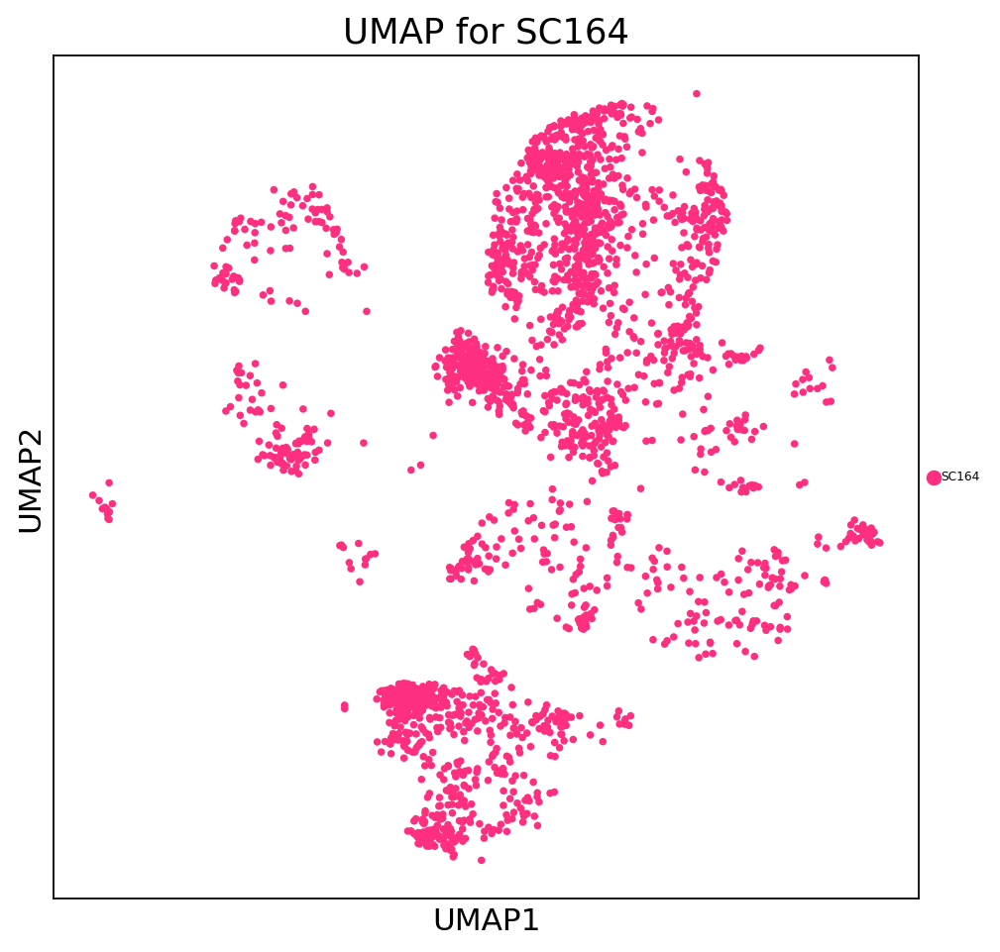

SC214


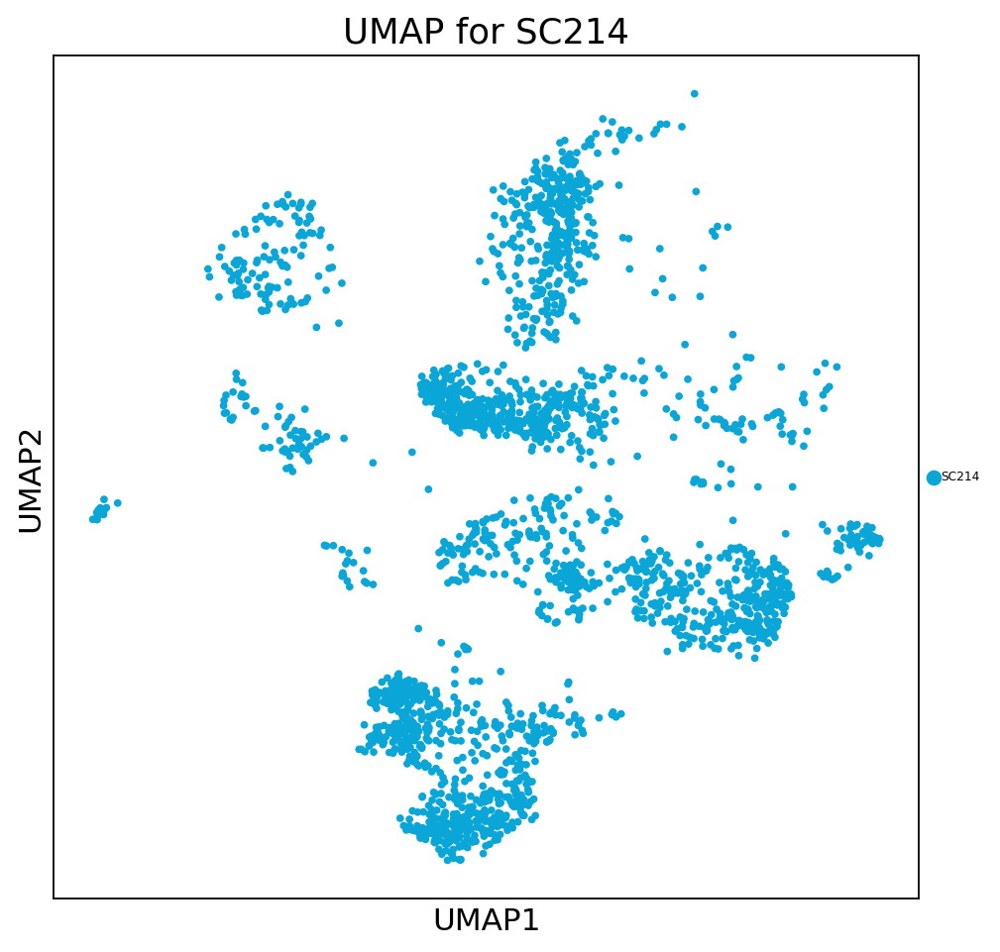

SC190


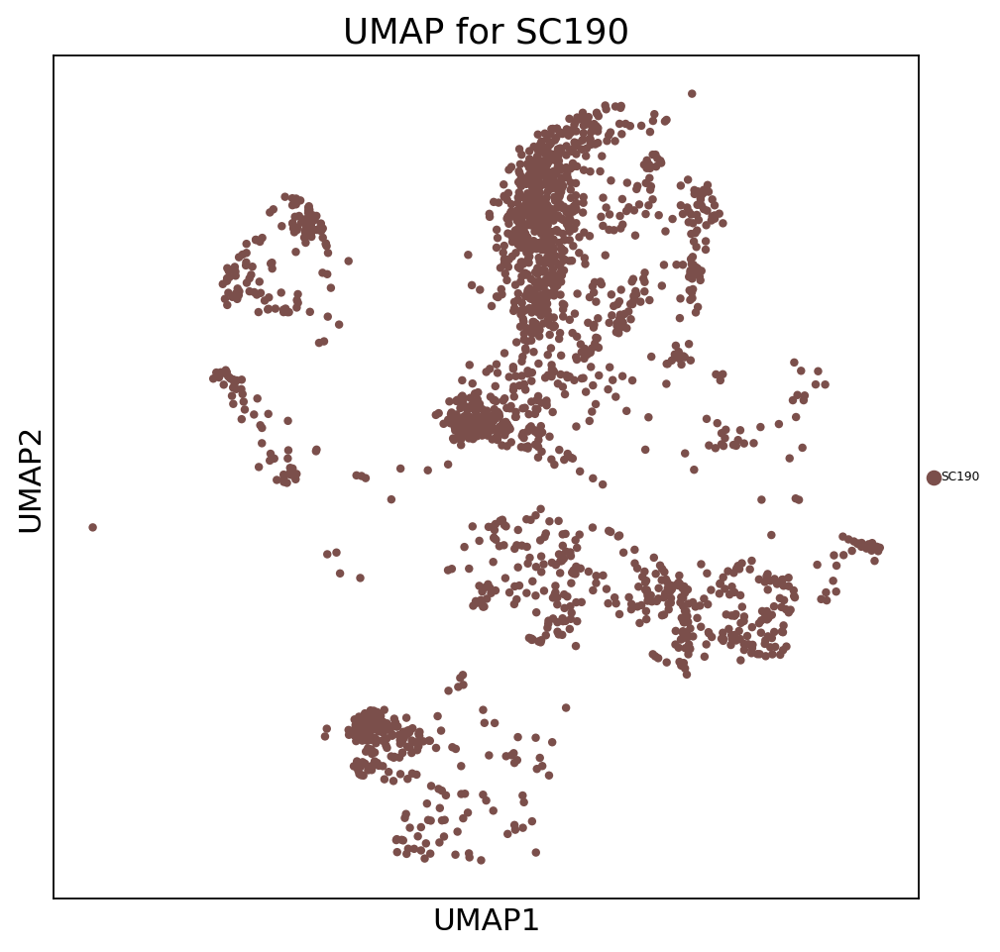

SC177


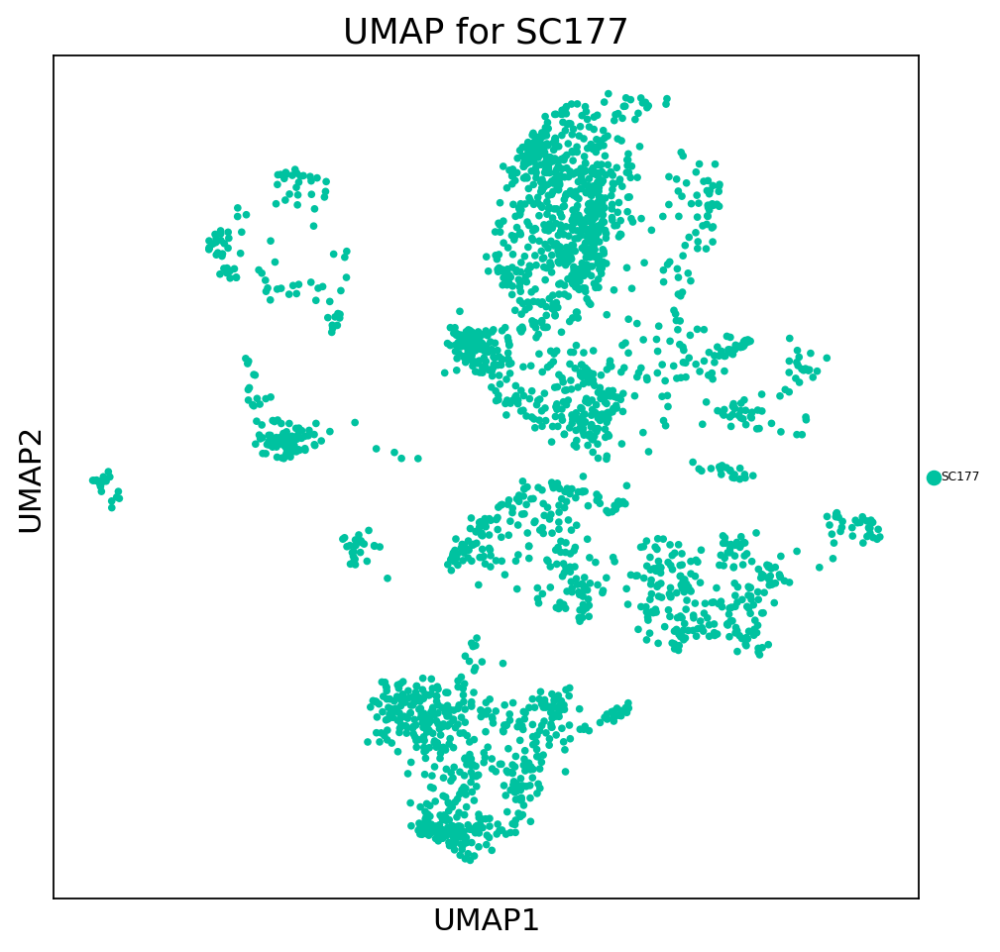

SC176


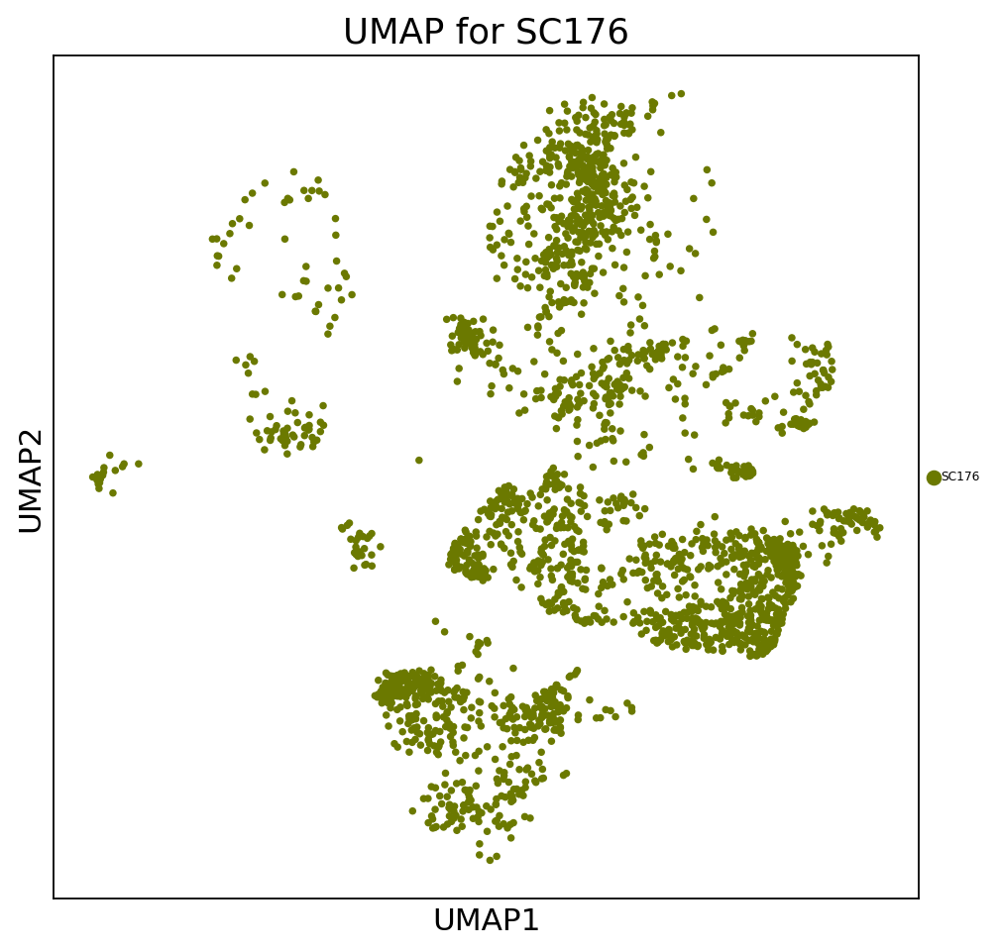

SC248


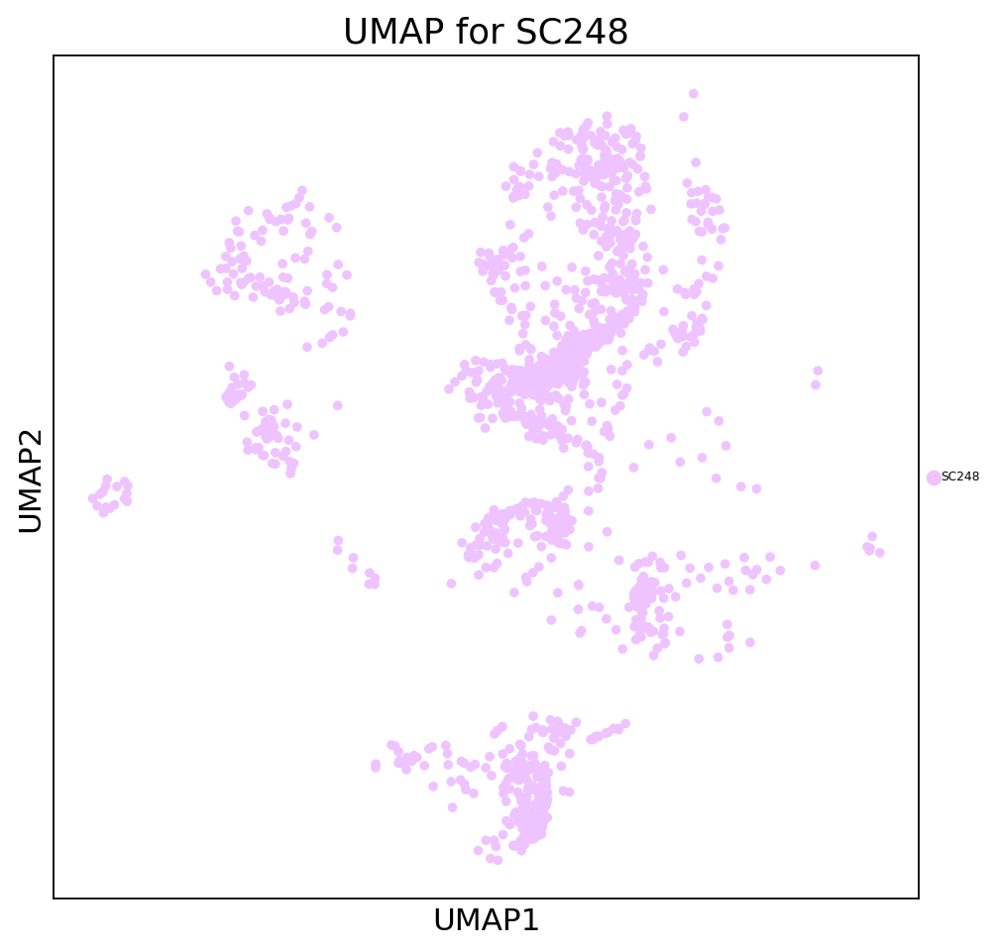

SC160


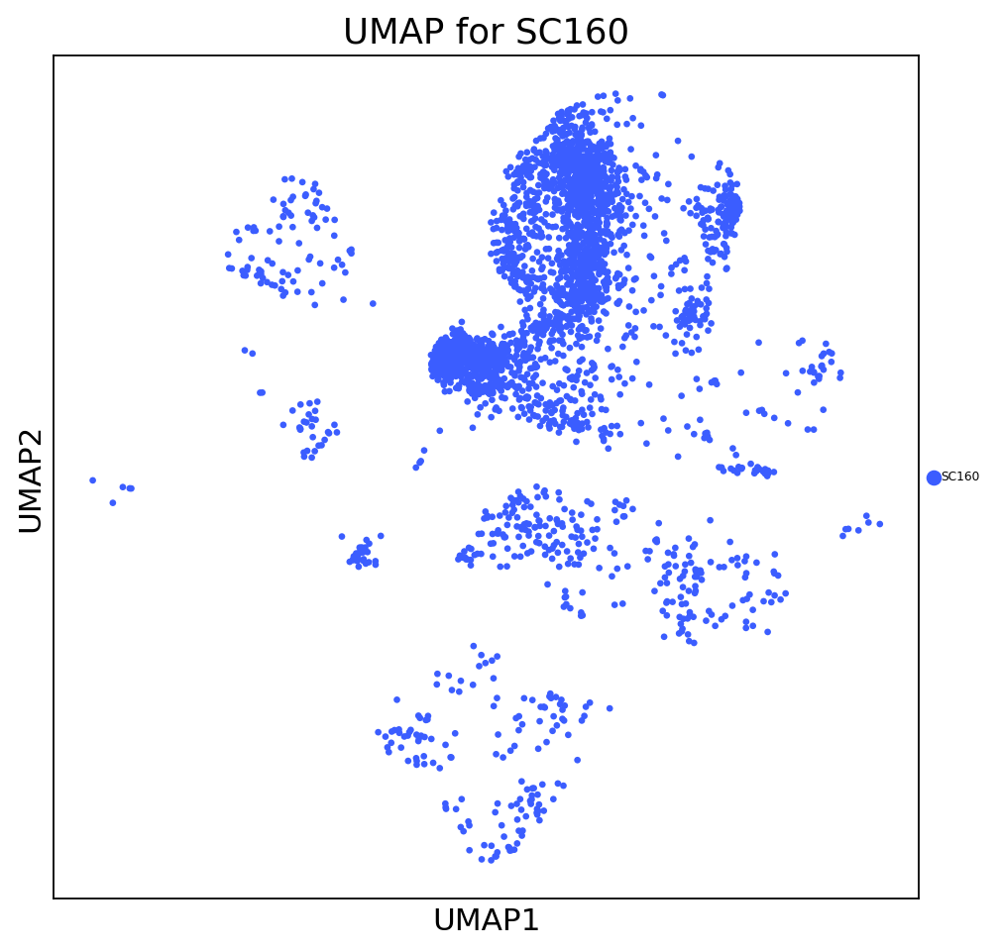

SC239


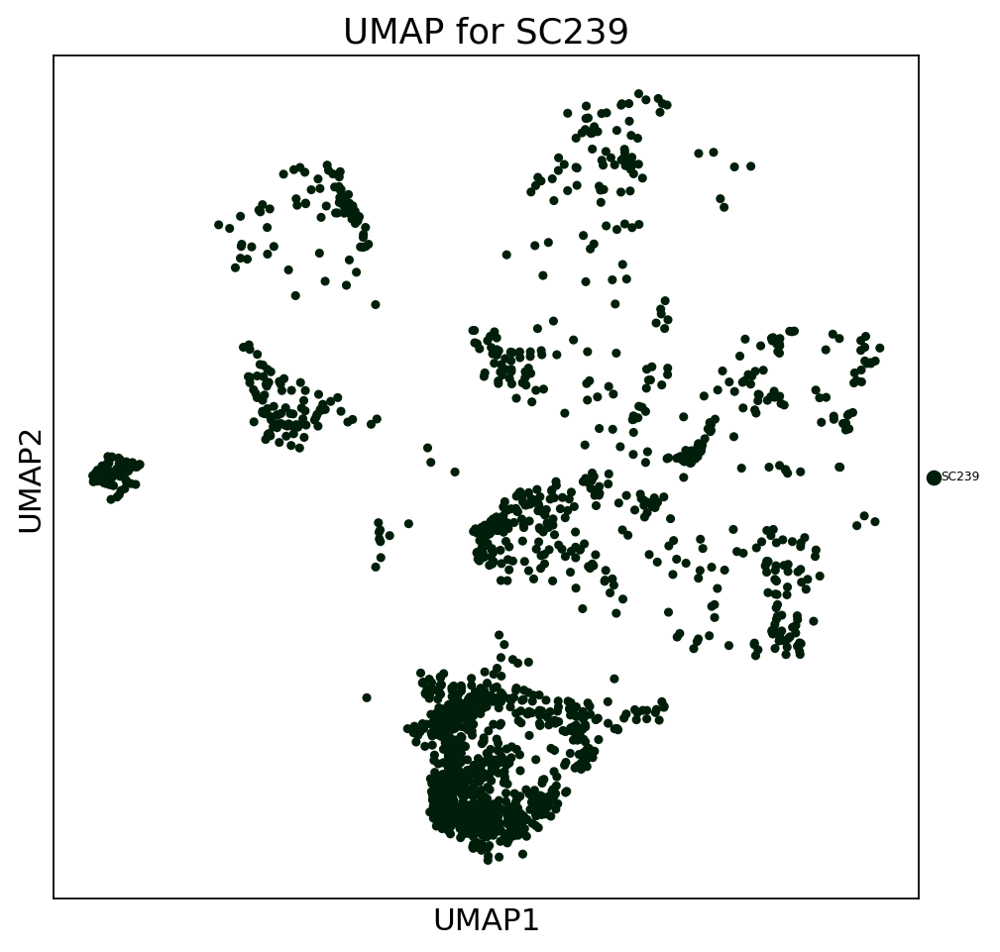

SC172


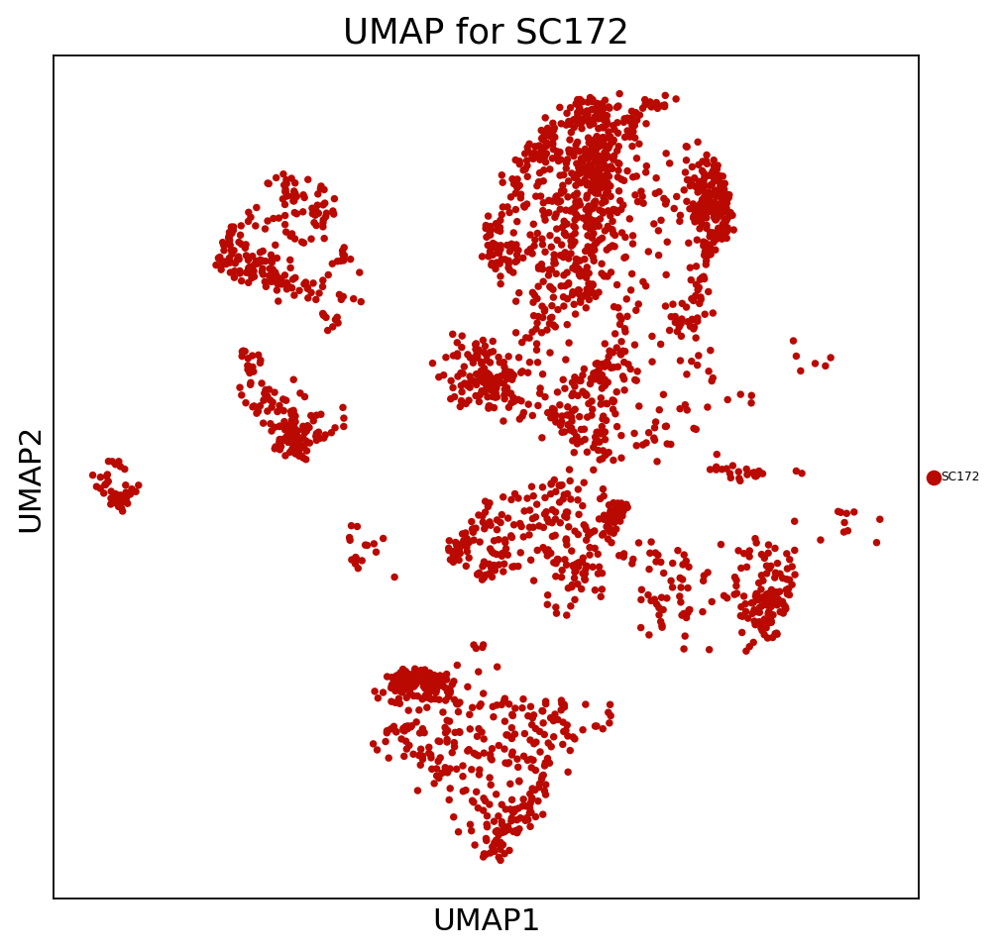

SC163


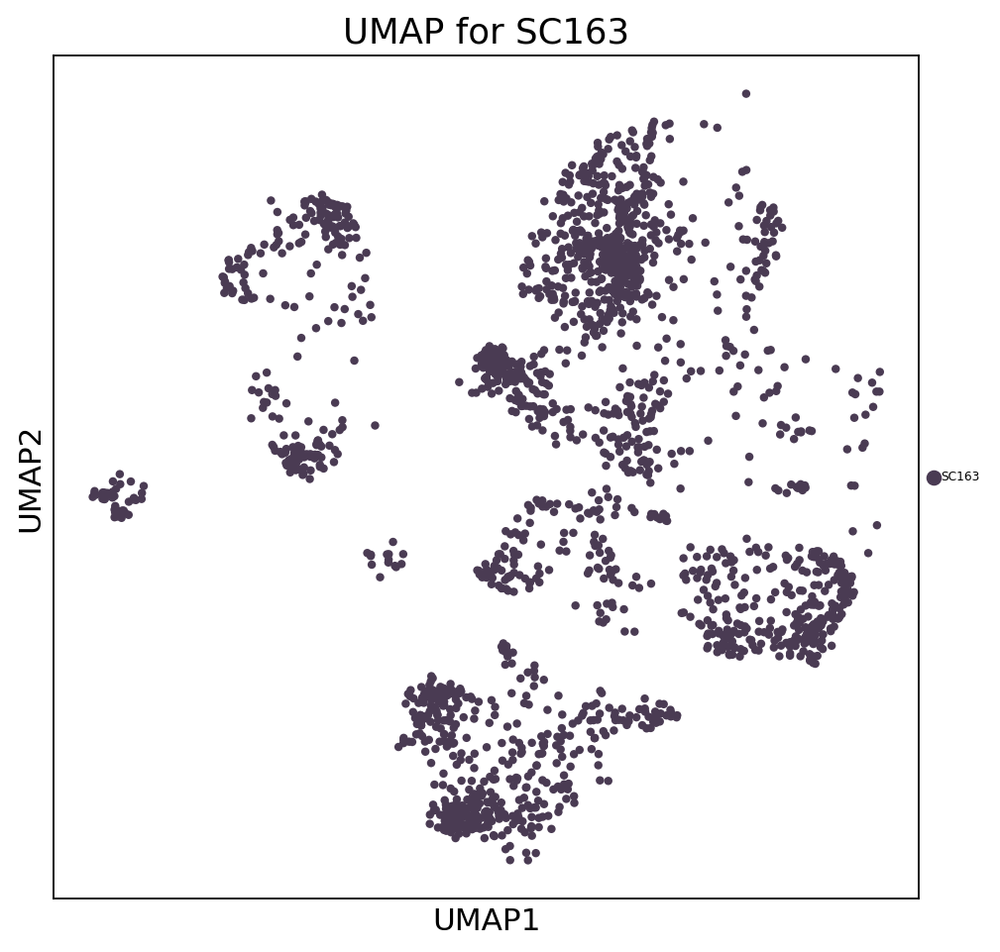

SC212


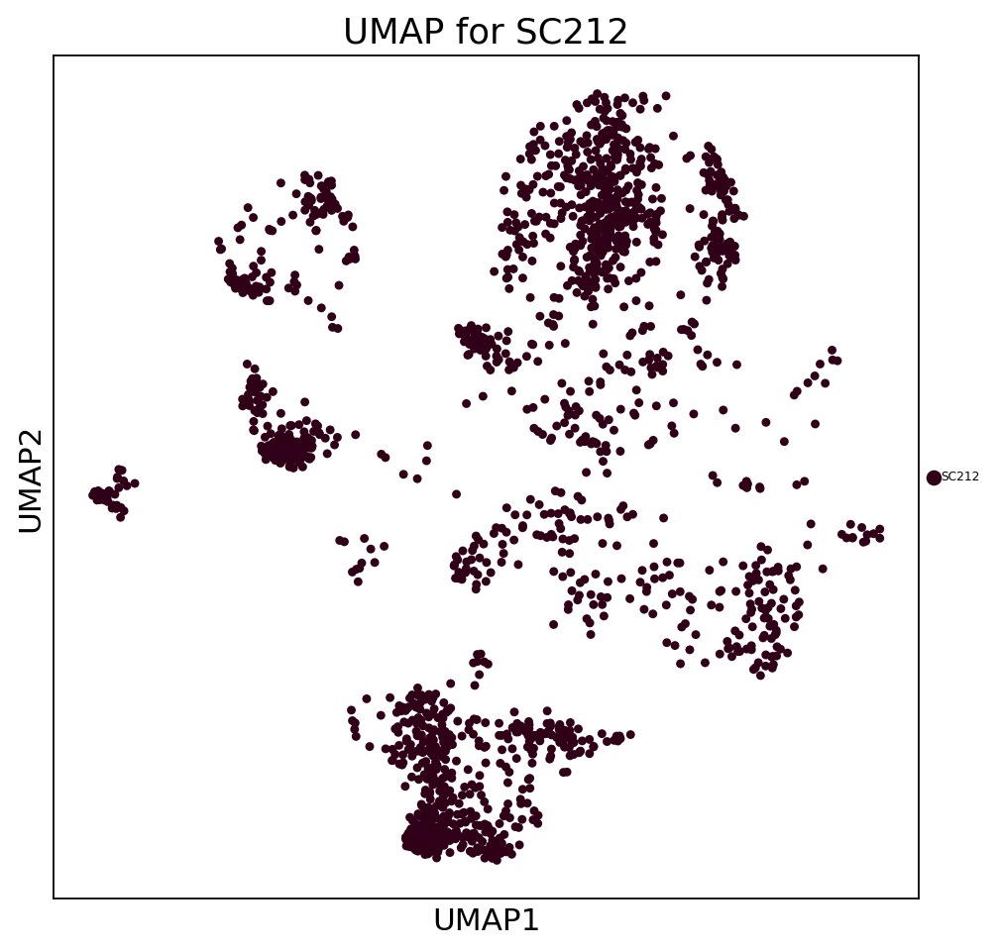

SC224


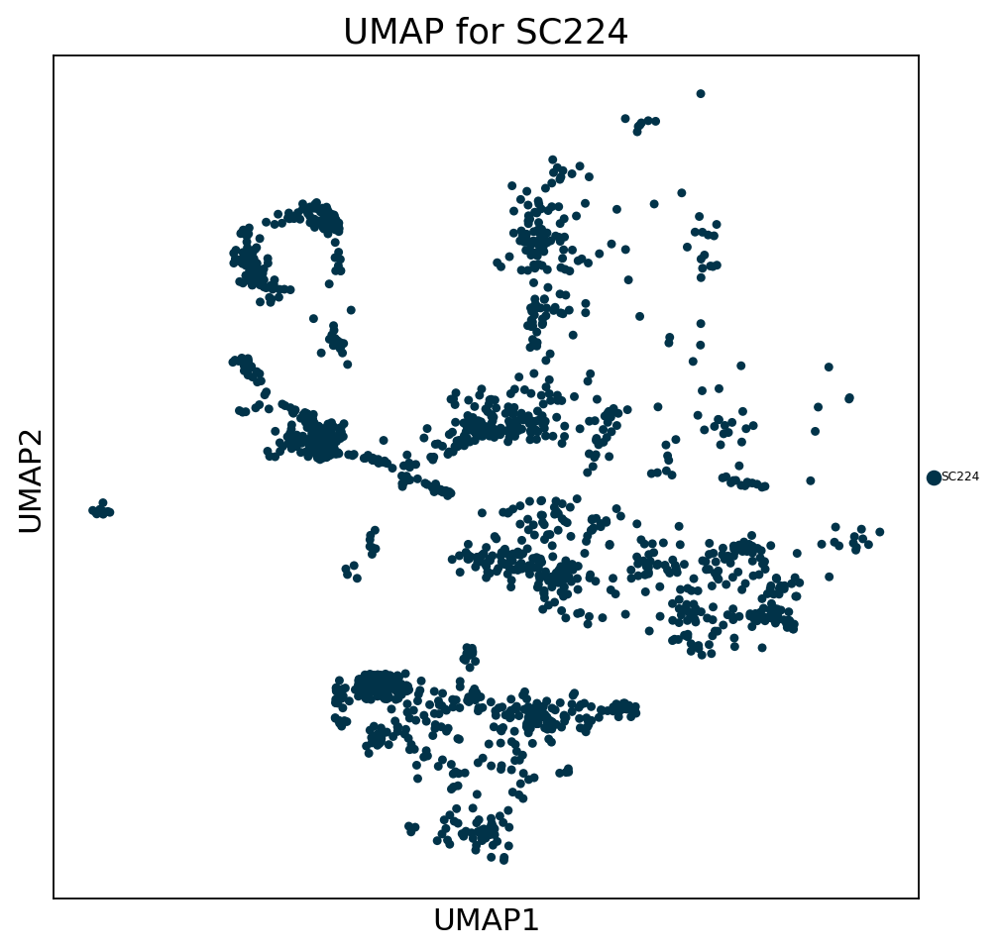

In [160]:
# Loop over each unique batch and generate a UMAP plot
for batch in adata3.obs['sample'].unique():
    print(batch)
    # Create a new adata object for the specific batch
    adata_batch = adata3[adata3.obs['sample'] == batch]
    
    # Plot UMAP for this batch
    sc.pl.umap(adata_batch, color='sample', title=f"UMAP for {batch}")

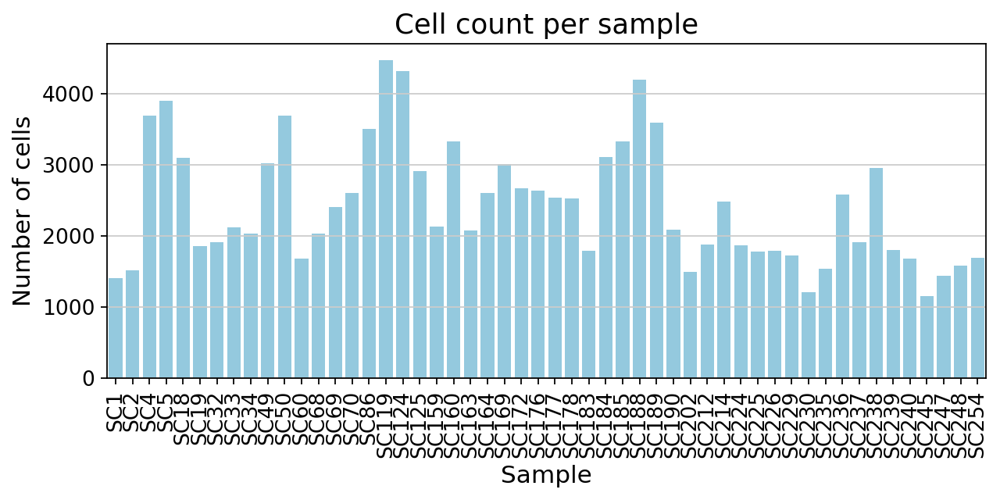

In [161]:
#Check and removal samples with less than 200 cells
import matplotlib.pyplot as plt
import seaborn as sns

# Count number of cells per sample
cell_counts = adata3.obs['sample'].value_counts().sort_index()

# Plot
plt.figure(figsize=(8,4))
sns.barplot(x=cell_counts.index, y=cell_counts.values, color="skyblue")
plt.xticks(rotation=90)
plt.ylabel("Number of cells")
plt.xlabel("Sample")
plt.title("Cell count per sample")
plt.tight_layout()
plt.show()


In [162]:
# Define minimum cell count threshold
#min_cells = 500

# Identify samples that meet the threshold
#valid_samples = cell_counts[cell_counts >= min_cells].index

# Filter the AnnData object
#adata3 = adata3[adata3.obs['sample'].isin(valid_samples)].copy()

#print(f"Kept {len(valid_samples)} samples with ≥ {min_cells} cells.")
#print(f"Remaining cells: {adata3.n_obs}")


# Annotation

In [163]:
import celltypist
import scanpy as sc
from celltypist import models

# Download the latest immune cell model
model = celltypist.models.Model.load('/home/ciperi/data/Atlas_SSC/Celltypist_model/Adult_Human_Skin.pkl')

adata = sc.AnnData(adata3.raw.X.copy(), var=adata3.raw.var.copy(), obs=adata3.obs.copy())
print(adata.X)

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 187982104 stored elements and shape (126397, 23748)>
  Coords	Values
  (0, 11)	1.0
  (0, 30)	1.0
  (0, 40)	1.0
  (0, 51)	4.0
  (0, 57)	1.0
  (0, 62)	1.0
  (0, 77)	1.0
  (0, 113)	15.0
  (0, 115)	1.0
  (0, 135)	1.0
  (0, 140)	1.0
  (0, 141)	1.0
  (0, 144)	2.0
  (0, 150)	1.0
  (0, 153)	6.0
  (0, 201)	2.0
  (0, 202)	1.0
  (0, 219)	1.0
  (0, 237)	1.0
  (0, 276)	2.0
  (0, 295)	2.0
  (0, 296)	1.0
  (0, 312)	2.0
  (0, 356)	35.0
  (0, 366)	2.0
  :	:
  (126396, 22181)	1.0
  (126396, 22201)	4.0
  (126396, 22323)	1.0
  (126396, 22400)	1.0
  (126396, 22458)	3.0
  (126396, 22619)	1.0
  (126396, 22674)	3.0
  (126396, 22781)	1.0
  (126396, 22877)	1.0
  (126396, 23098)	1.0
  (126396, 23198)	1.0
  (126396, 23219)	4.0
  (126396, 23328)	1.0
  (126396, 23375)	1.0
  (126396, 23379)	1.0
  (126396, 23457)	1.0
  (126396, 23724)	1.0
  (126396, 23725)	7.0
  (126396, 23726)	13.0
  (126396, 23727)	4.0
  (126396, 23729)	4.0
  (126396, 23730)	8.0
  (12639

In [164]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

🔬 Input data has 126397 cells and 23748 genes
🔗 Matching reference genes in the model
🧬 3288 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


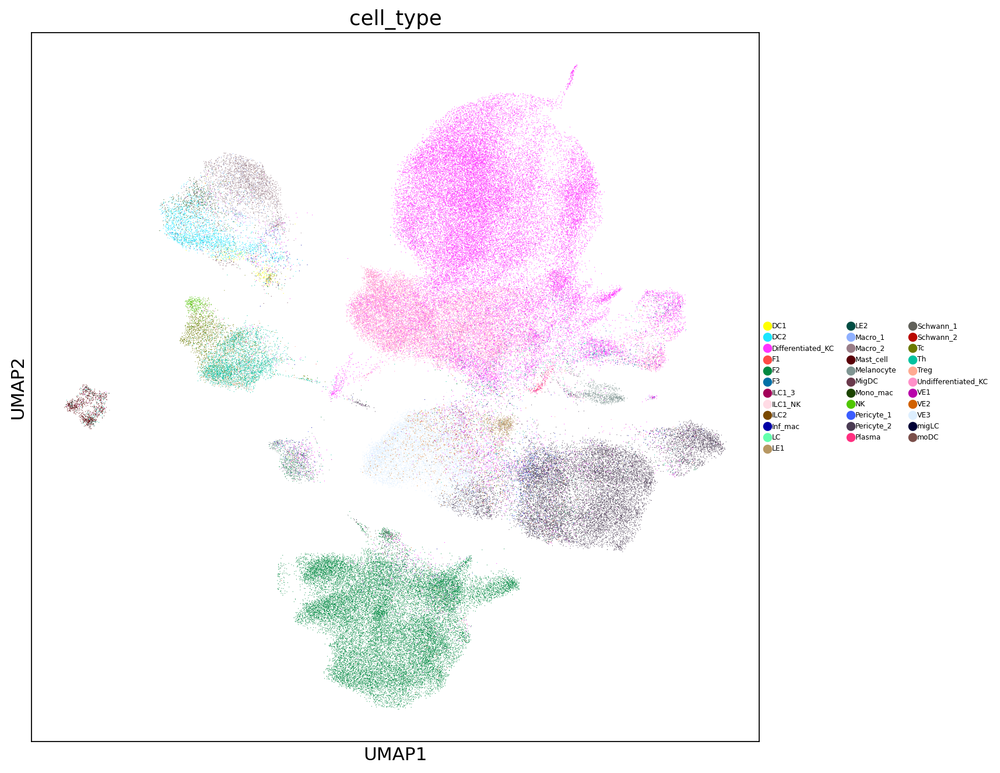

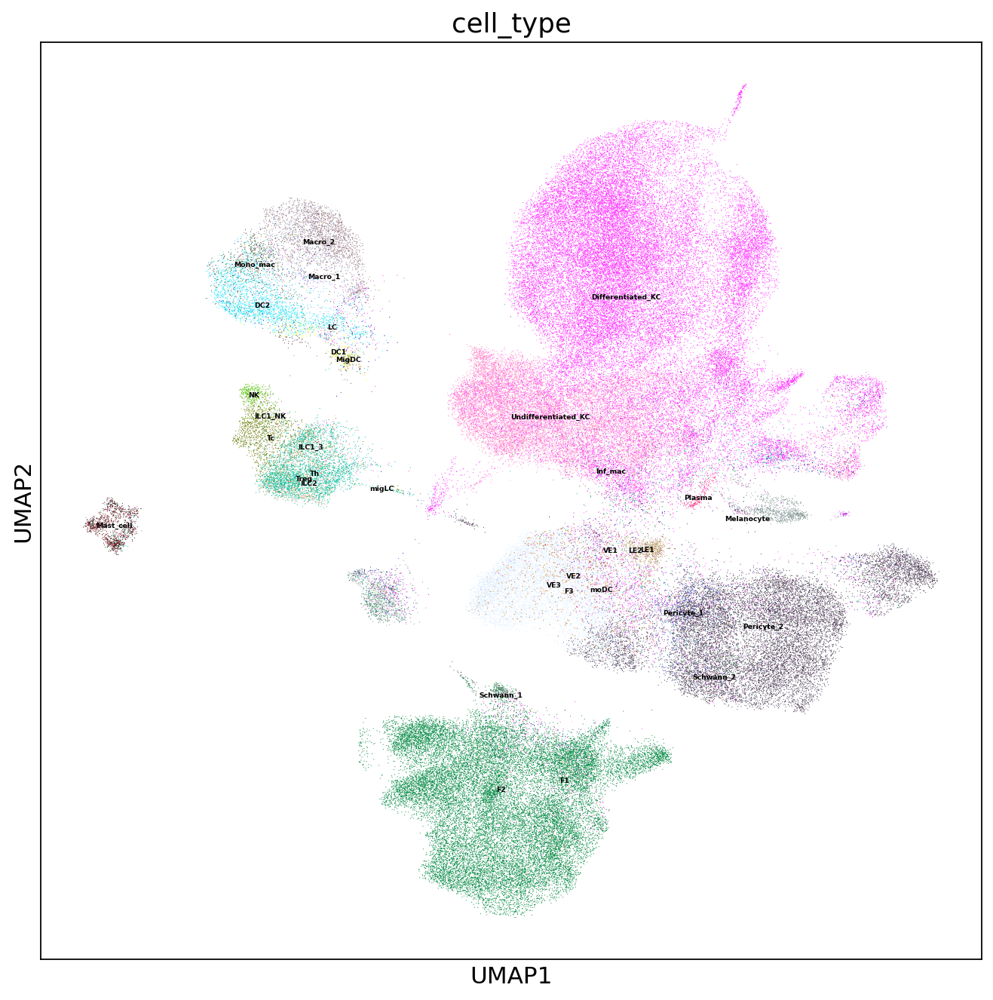

In [165]:
# Predict cell types
predictions = celltypist.annotate(adata, model=model)

# Store predictions in adata.obs
adata3.obs['cell_type'] = predictions.predicted_labels

plt.rcParams["figure.figsize"] = (10, 10)

# Visualize the results in UMAP
sc.pl.umap(adata3, color=['cell_type'])

sc.pl.umap(adata3, color=['cell_type'], legend_loc = "on data", legend_fontsize= 'x-small')

Keeping 30 cell types with ≥ 50 cells
Remaining cells: 126291
Remaining cell types: 30


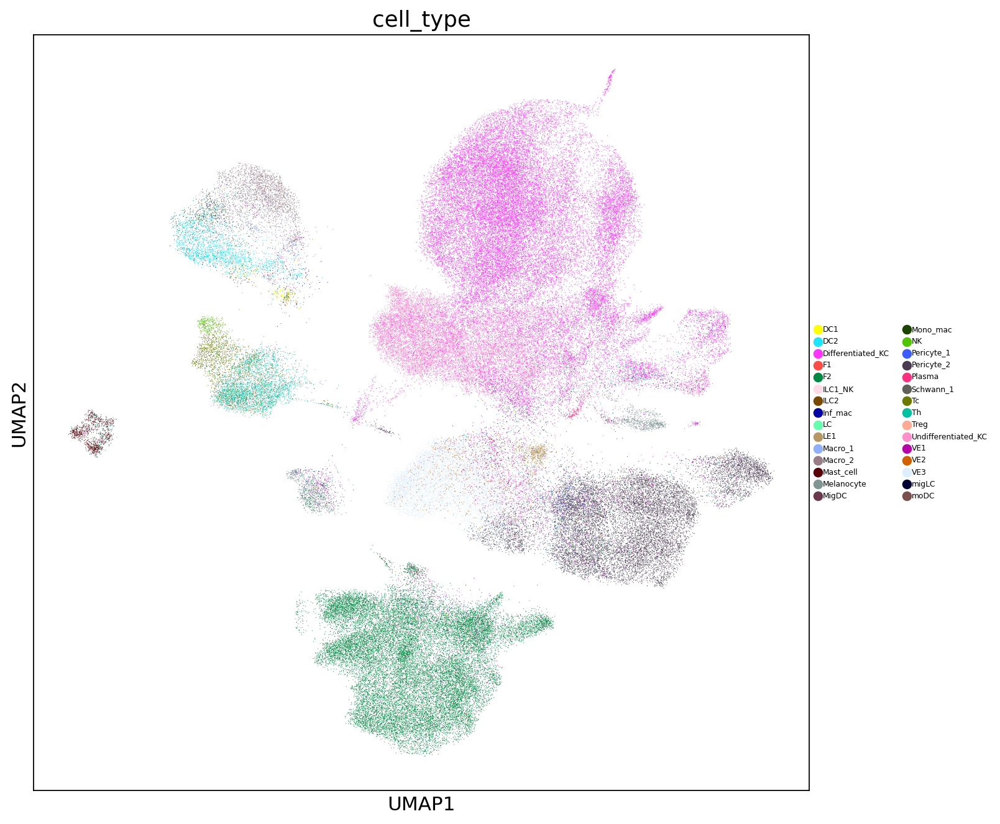

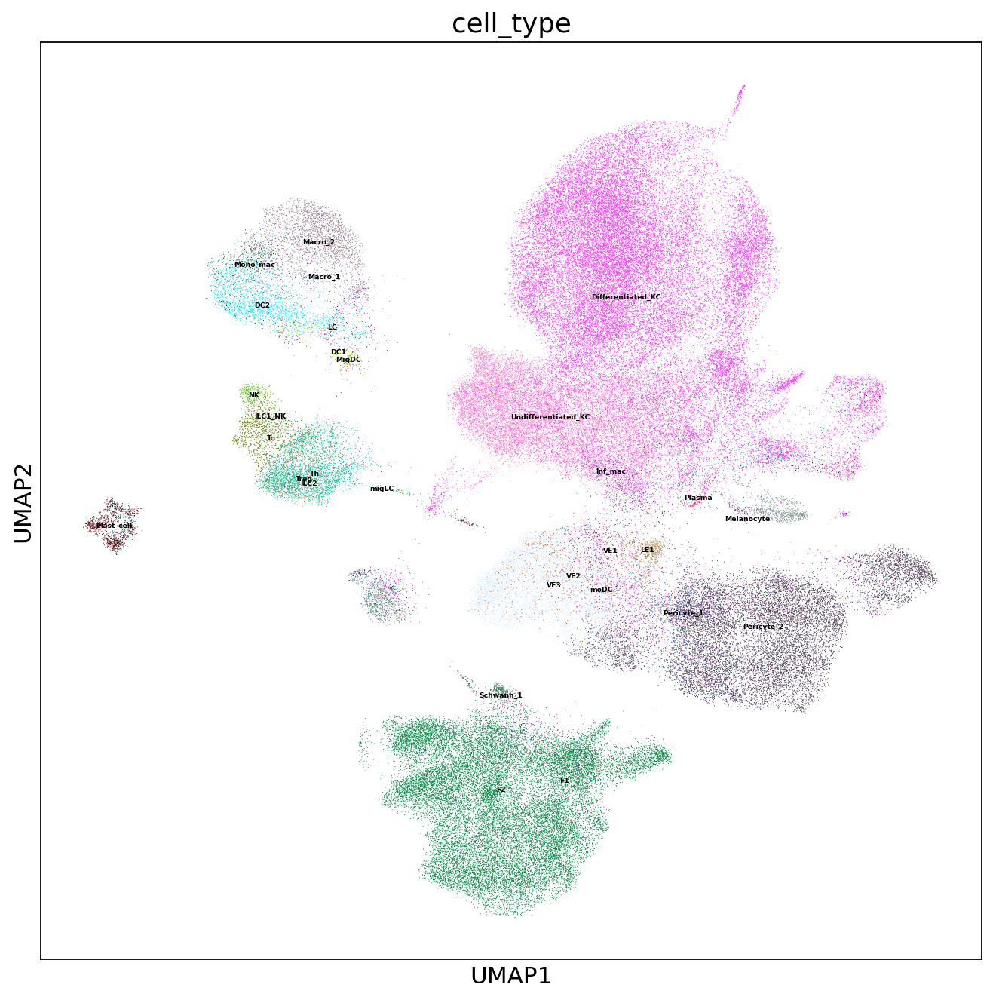

In [166]:
import pandas as pd

# Define the minimum cell count threshold
min_cells = 50

# Count cells per cell type
celltype_counts = adata3.obs['cell_type'].value_counts()

# Identify cell types that meet the threshold
valid_celltypes = celltype_counts[celltype_counts >= min_cells].index

print(f"Keeping {len(valid_celltypes)} cell types with ≥ {min_cells} cells")

# Filter AnnData to keep only valid cell types
adata3 = adata3[adata3.obs['cell_type'].isin(valid_celltypes)].copy()

# Report the result
print(f"Remaining cells: {adata3.n_obs}")
print(f"Remaining cell types: {adata3.obs['cell_type'].nunique()}")



plt.rcParams["figure.figsize"] = (10, 10)

# Visualize the results in UMAP
sc.pl.umap(adata3, color=['cell_type'])

sc.pl.umap(adata3, color=['cell_type'], legend_loc = "on data", legend_fontsize= 'x-small')




In [167]:
import numpy as np
import pandas as pd
import scanpy as sc

# Set parameters
min_keep = 500        # minimum cells to keep per cell type
groupby = "cell_type"  # column defining populations

# Prepare empty index list
subsampled_idx = []

# Loop through each cell type and subsample
for cell_type, indices in adata3.obs.groupby(groupby).groups.items():
    n_cells = len(indices)
    if n_cells <= min_keep:
        chosen = indices  # keep all
    else:
        chosen = np.random.choice(indices, size=min_keep, replace=False)
    subsampled_idx.extend(chosen)
    print(f"{cell_type:<20} → kept {len(chosen)} / {n_cells} cells")

# Create subsampled AnnData
adata_sub = adata3[subsampled_idx, :].copy()

print(f"\nTotal cells before: {adata3.n_obs}")
print(f"Total cells after subsampling: {adata_sub.n_obs}")


DC1                  → kept 254 / 254 cells
DC2                  → kept 500 / 2157 cells
Differentiated_KC    → kept 500 / 44622 cells
F1                   → kept 110 / 110 cells
F2                   → kept 500 / 25880 cells
ILC1_NK              → kept 145 / 145 cells
ILC2                 → kept 51 / 51 cells
Inf_mac              → kept 500 / 588 cells
LC                   → kept 71 / 71 cells
LE1                  → kept 500 / 756 cells
Macro_1              → kept 470 / 470 cells
Macro_2              → kept 500 / 2699 cells
Mast_cell            → kept 500 / 953 cells
Melanocyte           → kept 500 / 1460 cells
MigDC                → kept 160 / 160 cells
Mono_mac             → kept 437 / 437 cells
NK                   → kept 354 / 354 cells
Pericyte_1           → kept 500 / 551 cells
Pericyte_2           → kept 500 / 14570 cells
Plasma               → kept 186 / 186 cells
Schwann_1            → kept 211 / 211 cells
Tc                   → kept 500 / 1575 cells
Th                   → kep

In [168]:
sc.tl.rank_genes_groups(adata_sub, groupby='cell_type', method='logreg')
sc.pl.rank_genes_groups(adata_sub)

🔬 Input data has 126397 cells and 23748 genes
🔗 Matching reference genes in the model
🧬 3741 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


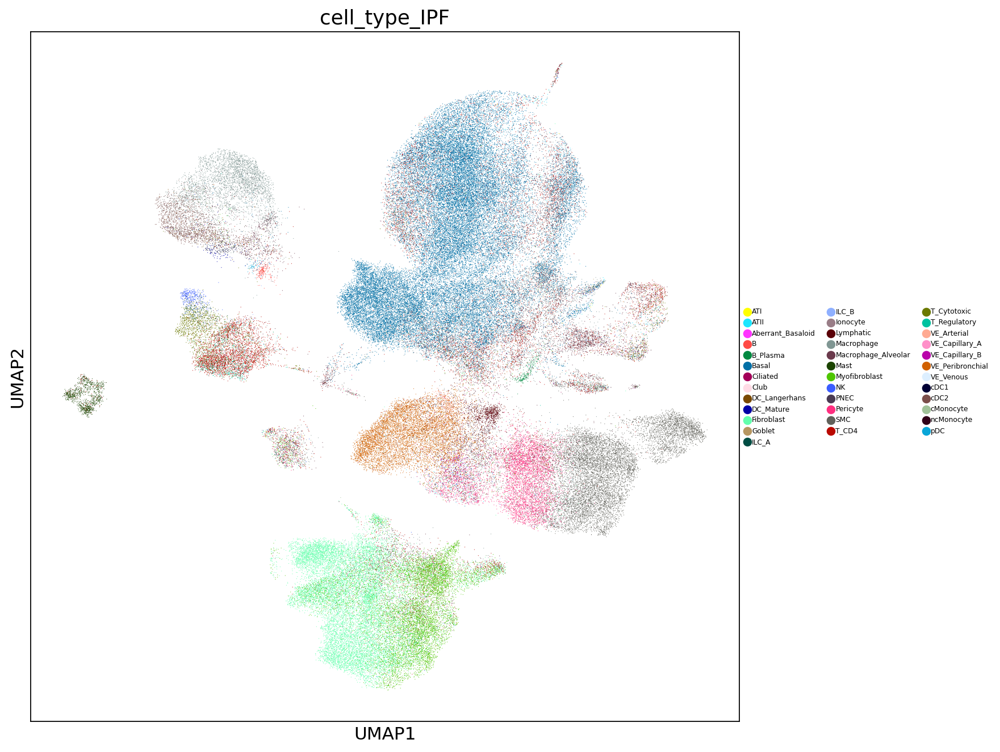

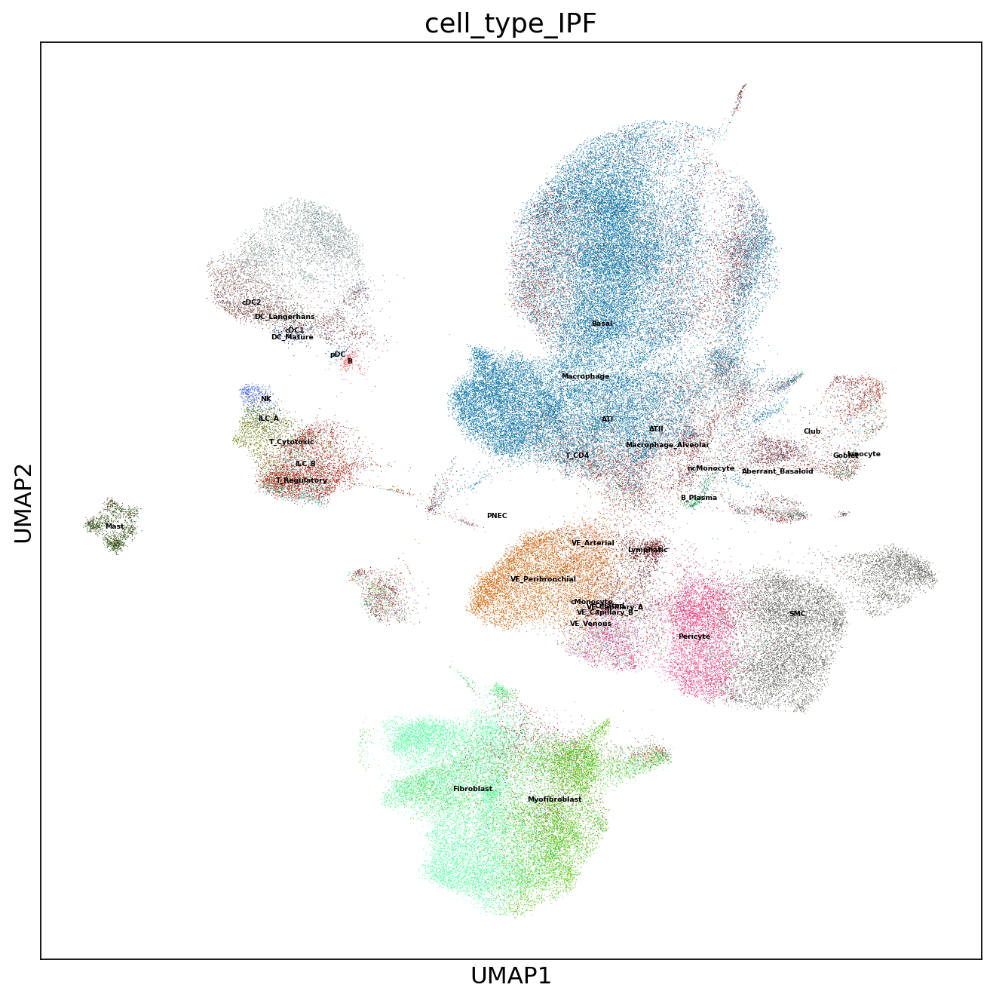

In [169]:
# Download the latest immune cell model
model = celltypist.models.Model.load('/home/ciperi/data/Atlas_SSC/Celltypist_model/Human_IPF_Lung.pkl')


predictions = celltypist.annotate(adata, model=model)

# Store predictions in adata.obs
adata3.obs['cell_type_IPF'] = predictions.predicted_labels

plt.rcParams["figure.figsize"] = (10, 10)

# Visualize the results in UMAP
sc.pl.umap(adata3, color=['cell_type_IPF'])

sc.pl.umap(adata3, color=['cell_type_IPF'], legend_loc = "on data", legend_fontsize= 'x-small')

Keeping 32 cell types with ≥ 50 cells
Remaining cells: 126190
Remaining cell types: 30


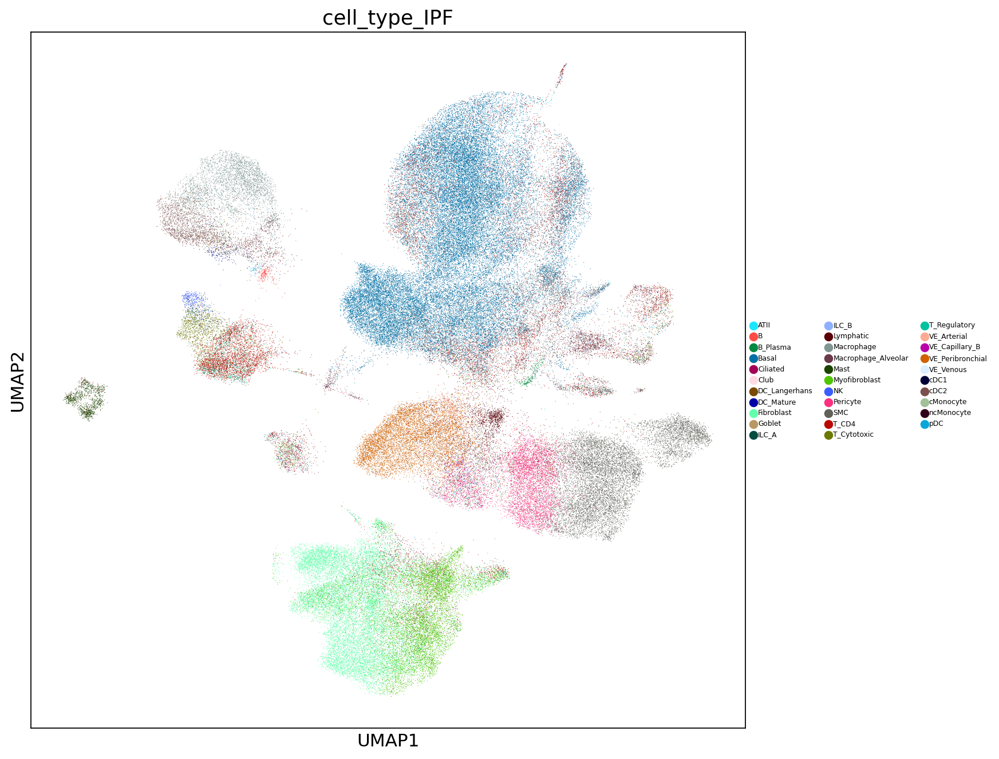

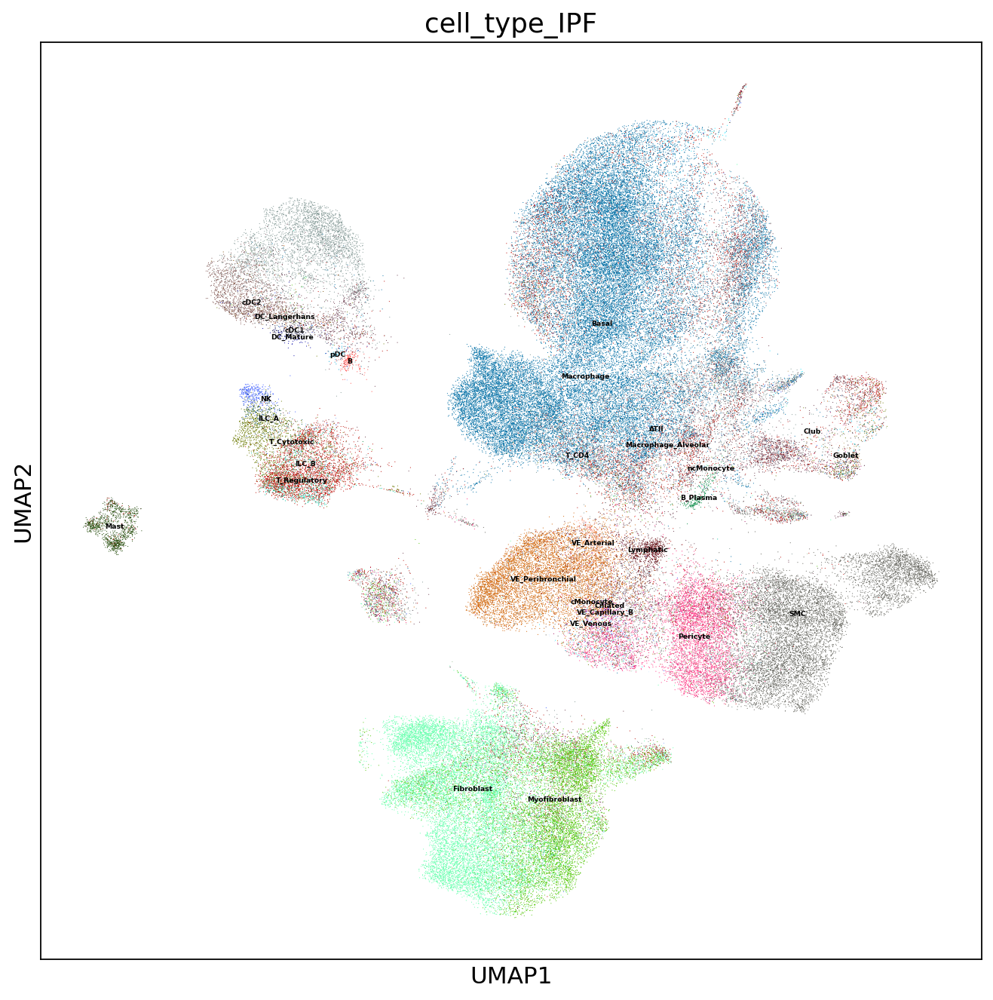

In [170]:
import pandas as pd

# Define the minimum cell count threshold
min_cells = 50

# Count cells per cell type
celltype_counts = adata3.obs['cell_type_IPF'].value_counts()

# Identify cell types that meet the threshold
valid_celltypes = celltype_counts[celltype_counts >= min_cells].index

print(f"Keeping {len(valid_celltypes)} cell types with ≥ {min_cells} cells")

# Filter AnnData to keep only valid cell types
adata3 = adata3[adata3.obs['cell_type_IPF'].isin(valid_celltypes)].copy()

# Report the result
print(f"Remaining cells: {adata3.n_obs}")
print(f"Remaining cell types: {adata3.obs['cell_type'].nunique()}")



plt.rcParams["figure.figsize"] = (10, 10)

# Visualize the results in UMAP
sc.pl.umap(adata3, color=['cell_type_IPF'])

sc.pl.umap(adata3, color=['cell_type_IPF'], legend_loc = "on data", legend_fontsize= 'x-small')




In [171]:
import numpy as np
import pandas as pd
import scanpy as sc

# Set parameters
min_keep = 500        # minimum cells to keep per cell type
groupby = "cell_type_IPF"  # column defining populations

# Prepare empty index list
subsampled_idx = []

# Loop through each cell type and subsample
for cell_type, indices in adata3.obs.groupby(groupby).groups.items():
    n_cells = len(indices)
    if n_cells <= min_keep:
        chosen = indices  # keep all
    else:
        chosen = np.random.choice(indices, size=min_keep, replace=False)
    subsampled_idx.extend(chosen)
    print(f"{cell_type:<20} → kept {len(chosen)} / {n_cells} cells")

# Create subsampled AnnData
adata_sub = adata3[subsampled_idx, :].copy()

print(f"\nTotal cells before: {adata3.n_obs}")
print(f"Total cells after subsampling: {adata_sub.n_obs}")


ATII                 → kept 378 / 378 cells
B                    → kept 224 / 224 cells
B_Plasma             → kept 228 / 228 cells
Basal                → kept 500 / 39902 cells
Ciliated             → kept 500 / 511 cells
Club                 → kept 500 / 504 cells
DC_Langerhans        → kept 94 / 94 cells
DC_Mature            → kept 84 / 84 cells
Fibroblast           → kept 500 / 15097 cells
Goblet               → kept 200 / 200 cells
ILC_A                → kept 177 / 177 cells
ILC_B                → kept 141 / 141 cells
Lymphatic            → kept 500 / 746 cells
Macrophage           → kept 500 / 10967 cells
Macrophage_Alveolar  → kept 500 / 8036 cells
Mast                 → kept 500 / 1017 cells
Myofibroblast        → kept 500 / 8882 cells
NK                   → kept 500 / 612 cells
Pericyte             → kept 500 / 4886 cells
SMC                  → kept 500 / 9529 cells
T_CD4                → kept 500 / 10106 cells
T_Cytotoxic          → kept 500 / 2264 cells
T_Regulatory         →

In [172]:
sc.tl.rank_genes_groups(adata_sub, groupby='cell_type_IPF', method='logreg')
sc.pl.rank_genes_groups(adata_sub)

In [173]:
sc.tl.leiden(
    adata3,
    resolution=2,
    random_state=0,
    flavor="igraph",
    n_iterations=2,
    directed=False,
    key_added="leiden_r2" 
) #Using igraph as flavor there is currently a bug on windows system that block freeze R.

['0', '11', '8', '18', '17', ..., '2', '43', '44', '45', '30']
Length: 46
Categories (46, object): ['0', '1', '2', '3', ..., '42', '43', '44', '45']


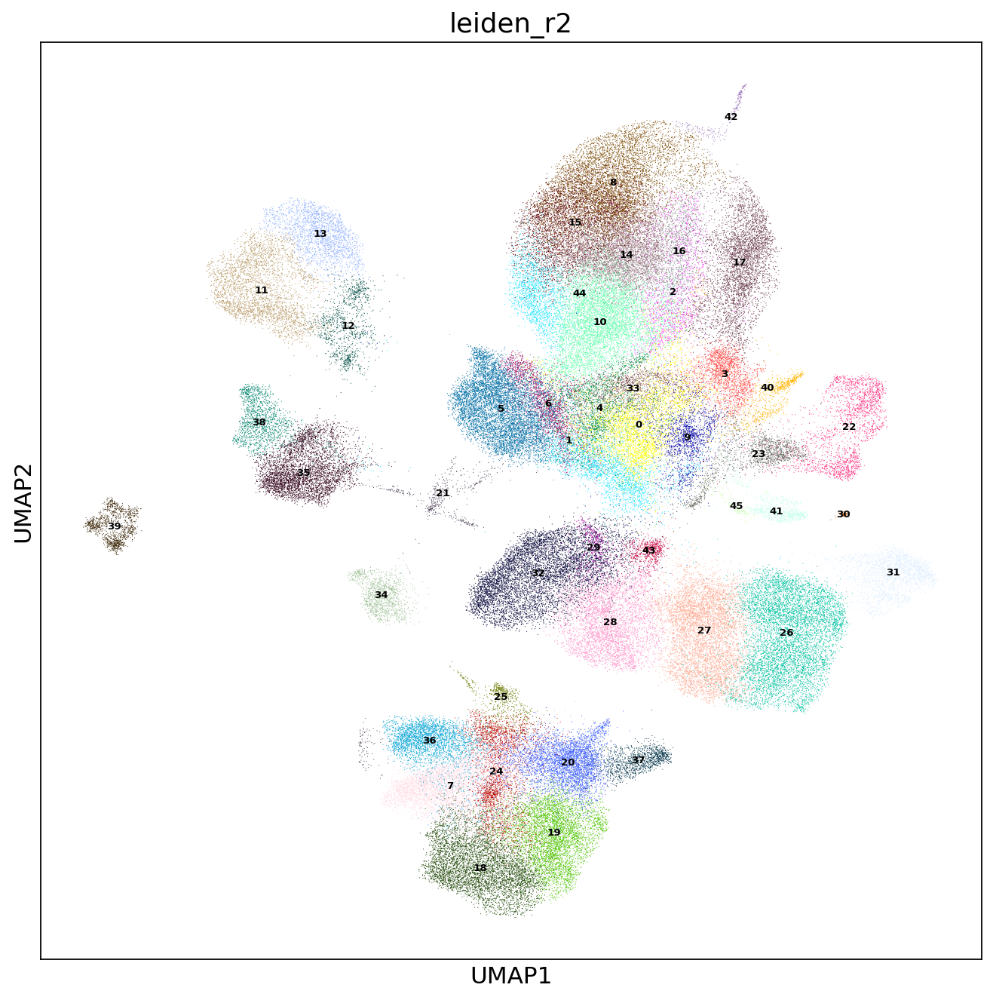

In [174]:
print(adata3.obs['leiden_r2'].unique())
sc.pl.umap(adata3, color='leiden_r2', legend_loc='on data')

In [175]:
sc.tl.leiden(
    adata3,
    resolution=0.4,
    random_state=0,
    flavor="igraph",
    n_iterations=2,
    directed=False,
    key_added="leiden_r0.4" 
) #Using igraph as flavor there is currently a bug on windows system that block freeze R.

['0', '5', '1', '4', '2', ..., '8', '13', '14', '15', '3']
Length: 16
Categories (16, object): ['0', '1', '2', '3', ..., '12', '13', '14', '15']


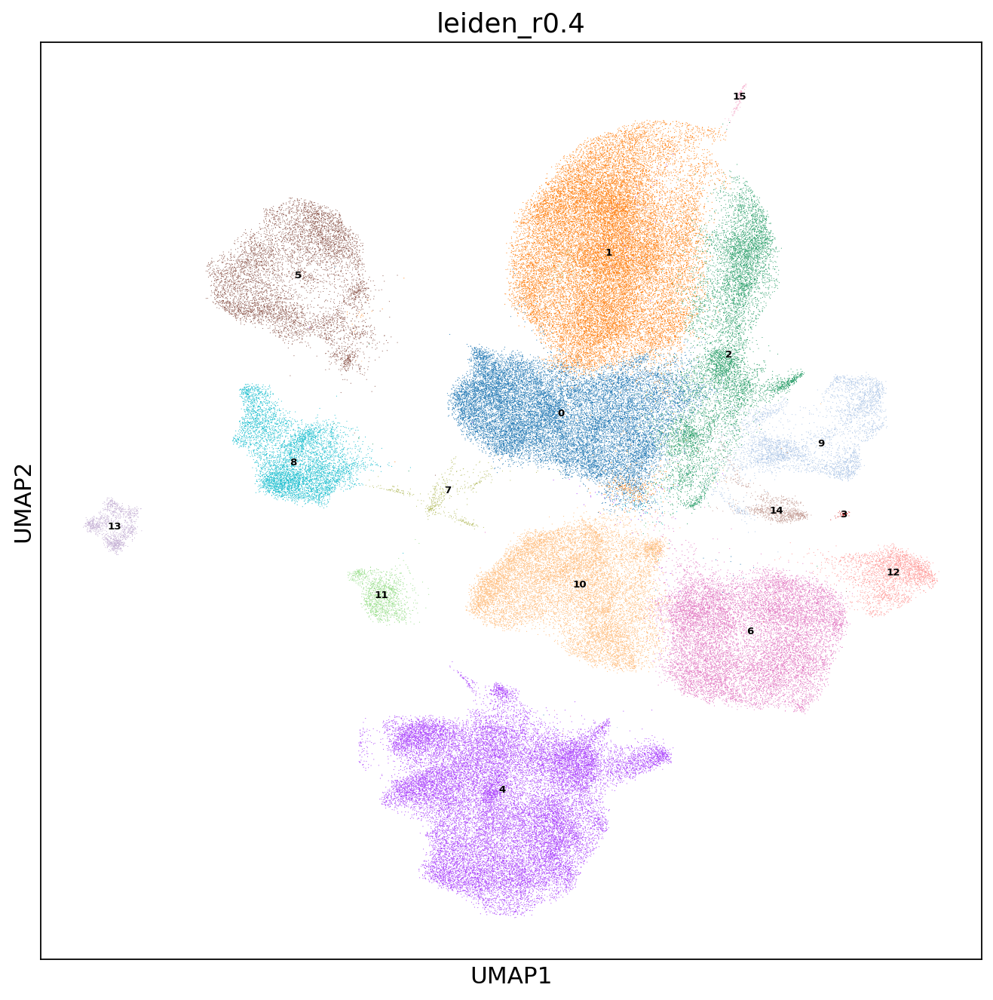

In [176]:
print(adata3.obs['leiden_r0.4'].unique())
sc.pl.umap(adata3, color='leiden_r0.4', legend_loc='on data')

In [177]:
import numpy as np
import pandas as pd
import scanpy as sc

# Set parameters
min_keep = 500        # minimum cells to keep per cell type
groupby = "leiden_r0.4"  # column defining populations

# Prepare empty index list
subsampled_idx = []

# Loop through each cell type and subsample
for cell_type, indices in adata3.obs.groupby(groupby).groups.items():
    n_cells = len(indices)
    if n_cells <= min_keep:
        chosen = indices  # keep all
    else:
        chosen = np.random.choice(indices, size=min_keep, replace=False)
    subsampled_idx.extend(chosen)
    print(f"{cell_type:<20} → kept {len(chosen)} / {n_cells} cells")

# Create subsampled AnnData
adata_sub = adata3[subsampled_idx, :].copy()

print(f"\nTotal cells before: {adata3.n_obs}")
print(f"Total cells after subsampling: {adata_sub.n_obs}")


0                    → kept 500 / 18403 cells
1                    → kept 500 / 25514 cells
2                    → kept 500 / 8987 cells
3                    → kept 49 / 49 cells
4                    → kept 500 / 26208 cells
5                    → kept 500 / 6476 cells
6                    → kept 500 / 12823 cells
7                    → kept 500 / 539 cells
8                    → kept 500 / 5756 cells
9                    → kept 500 / 3619 cells
10                   → kept 500 / 12197 cells
11                   → kept 500 / 1276 cells
12                   → kept 500 / 2208 cells
13                   → kept 500 / 1131 cells
14                   → kept 500 / 869 cells
15                   → kept 135 / 135 cells

Total cells before: 126190
Total cells after subsampling: 7184


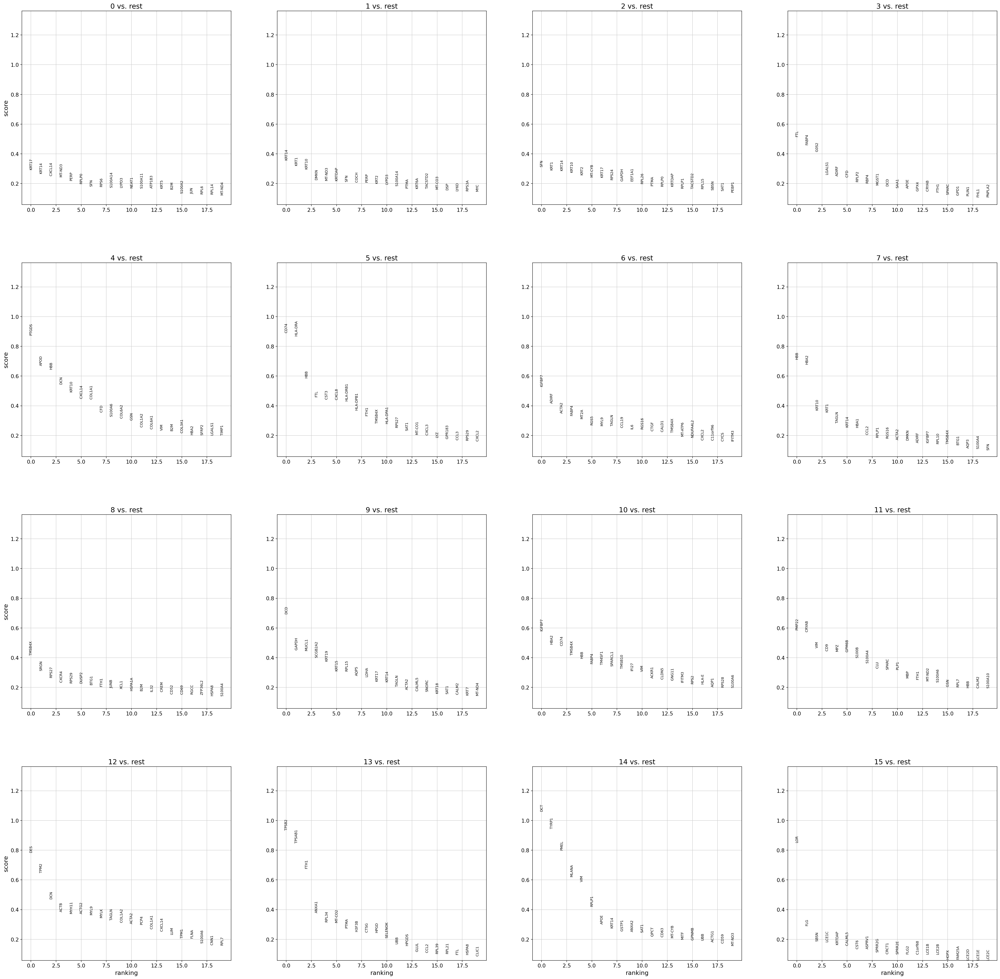

In [178]:
sc.tl.rank_genes_groups(adata_sub, groupby='leiden_r0.4', method='logreg')
sc.pl.rank_genes_groups(adata_sub)

In [179]:
adata3.write("/home/ciperi/data/Atlas_SSC/SKIN/Unintegrated_Skin_V2_reann.h5ad")